# Прогнозирование движения акций S&P 500
## Исправленная тетрадь: полный протокол проверки по рецензиям

Я сохраняю 273 признака, исходную 10-дневную цель и набор моделей.
Основной вопрос: меняется ли экономический результат при изменении формы
обучающего окна и правил обновления модели при одинаковых прочих условиях?

**Порядок:** 1. Предметная область → 2. Данные и признаки → 3. Модели,
значимость и экономическое сравнение → 4. SHAP → 5. Итоги и ограничения.
Сохранены 99 ячеек. Предыдущий выполненный прогон сохранён в
`reports/review_before_strict_20261101`; v6 и final не изменены.

Перед долгим обучением выполняются проверки окружения, сохранения файлов,
источников, контрольных сумм и факторных данных. Загрузка при Run All идёт
из зафиксированных локальных файлов, без сетевых запросов.

**Короткие ответы:** k=10, равные доли; 21-дневное удержание использует
тот же 10-дневный сигнал; 260 — прогрев признака, purge train/test равен 10 дням.
Основной результат — риск-корректированная альфа, а не простое превышение индекса.
Новый полный прогон вычисляет все числа заново; результаты старого прогона
не подставляются. Это ретроспективное исследование: прежний OOS уже просмотрен.


---
# 1. Анализ предметной области

## 1.1 Постановка и научный вопрос

Для каждой бумаги я оцениваю вероятность события: хотя бы в одну из следующих
10 торговых сессий её ценовая доходность превысит доходность индекса более чем
на **2 процентных пункта**. Это событие достижения уровня, а не доходность
ровно на десятый день и не гарантия денежной прибыли.

Я проверяю, сохраняются ли различия между стратегиями после выравнивания
периода, модели, расписания обновления, purge, комиссий и правил исполнения.
Это позволяет отделить качество ранжирования от экономического результата.
SHAP помогает описать экспозицию модели к волатильности и экстремумам,
но не доказывает причинность или прибыльность.

## 1.2 Критерии и процедура

- Классификация: ROC-AUC, AP, дневной Precision@10 и его базовая частота.
- Основная экономическая оценка: годовой intercept CAPM с фактическим RF,
  совместный блочный bootstrap разностей; FF5+momentum — проверка экспозиций.
- Дополнительные показатели: Sharpe excess returns, просадка, Profit Factor,
  средний логарифмический рост и накопленная доходность после комиссии.
- OOS фиксирован: 2022-06-02…2024-11-22. CV проводится внутри train:
  пять растущих фолдов по целым датам с purge 10 дней.
- Порог 2 п.п. сохранён из постановки; баланс классов измеряется заново,
  а не считается заранее равным 49/51.

## 1.3 Область применимости

Результат — исследовательское ранжирование и сравнение протоколов. Он не
обещает роста выбранных акций. Фундаментальные данные снимка 2024 не входят
в признаки. Исторический состав индекса не восстановлен, поэтому survivorship
bias остаётся. Проскальзывание, влияние на рынок и дивиденды не моделируются.


---
# 2. Формирование и подготовка данных
## 2.1 Источники

Вселенная — ровно 502 имени из исходного `sp500_companies.csv`.
Основной источник — Yahoo Close (`auto_adjust=False`); подтверждённые
переименования той же бумаги допускаются с сохранением исходного Symbol.
При отсутствии Yahoo используется **целая история** исходного Close или
проверенного архива. Бумага не заменяется компанией-покупателем.
Истории разных источников внутри одного тикера не склеиваются автоматически.

Происхождение каждой истории, даты, SHA256 и доступность будущих цен записаны
в `recovered_download_manifest.csv`. Снимок фиксируется; изменение файлов
после фиксации вызывает ошибку до обучения.

502 запрошенных имени, число загруженных историй и число бумаг с готовыми
признаками — разные величины. IPO нельзя снабжать искусственной предысторией.
Если часть историй не восстановлена, фактическая выборка указывается явно
в каждой итоговой сводке; такой опыт не называется полным опытом на 502.


In [1]:
# Импорт библиотек
import sys
import json
import os
import random
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.mplconfig_review'))
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
%matplotlib inline

from sklearn.model_selection import TimeSeriesSplit, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay,
    roc_auc_score, f1_score, average_precision_score,
    precision_score, recall_score
)
from xgboost import XGBClassifier
import shap
from flaml import AutoML as FlamlAutoML

from scipy.stats import randint, uniform, norm, wilcoxon, t as student_t

# ── Воспроизводимость ────────────────────────────────────────────────────────
SEED = 42


def set_seed(seed: int = SEED) -> None:
    """Фиксирует все источники случайности, доступные в ноутбуке."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)


set_seed(SEED)

# ── Пути ─────────────────────────────────────────────────────────────────────
# Ноутбук запускается из notebooks/, данные лежат в data/versions/<версия>/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_VERSION = 'review_strict_2026_11_01'
sys.path.insert(0, str(PROJECT_ROOT))
from src import review_revision as rr
DATA_DIR = PROJECT_ROOT / 'data' / 'versions' / 'v1.0.0_coursework'
YF_DIR = PROJECT_ROOT / 'data' / 'versions' / 'yfinance_review_2026_11_01'
CACHE_DIR = PROJECT_ROOT / 'data' / 'derived'  / DATA_VERSION
MODEL_DIR = PROJECT_ROOT / 'models' / 'versions' / DATA_VERSION
FIG_DIR = PROJECT_ROOT / 'reports' / DATA_VERSION / 'figures'

for _d in (CACHE_DIR, MODEL_DIR, FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

assert DATA_DIR.exists(), f'Не найден каталог с данными: {DATA_DIR}'
print(f'PROJECT_ROOT = {PROJECT_ROOT}')
print(f'DATA_DIR     = {DATA_DIR}')
from src import review_inference as ri
from src import review_protocol as rp
from src import review_factors as rf
from src import review_data as rd
import importlib
# Restart Kernel + Run All is recommended; reload also prevents stale helper code.
for module in (rr,ri,rp,rf,rd):
    importlib.reload(module)
from threadpoolctl import threadpool_limits
environment = rp.preflight(CACHE_DIR)
print('Python kernel:',environment['executable'])


c:\Users\dima\anaconda3\envs\bz\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PROJECT_ROOT = c:\Users\dima\Desktop\Важные файлы с МГТУ им. Н.Э.Баумана и не только\ИУ6\3 курс\6 семестр\КУРСАЧИ\МЛ\MMOAI
DATA_DIR     = c:\Users\dima\Desktop\Важные файлы с МГТУ им. Н.Э.Баумана и не только\ИУ6\3 курс\6 семестр\КУРСАЧИ\МЛ\MMOAI\data\versions\v1.0.0_coursework
Python kernel: c:\Users\dima\anaconda3\envs\bz\python.exe


In [2]:
# Конфигурация фиксируется до нового обучения; значения не выбираются по P&L.
OOS_START=pd.Timestamp('2022-06-02')
OOS_END=pd.Timestamp('2024-11-22')
LABEL_DAYS=10
HOLD_DAYS,HOLD_DAYS_ROBUST=10,21
INITIAL_CAPITAL,TOP_K,COMMISSION=100_000,10,.001
TRAIN_DAYS,GAP_DAYS,TEST_DAYS,STEP_DAYS=253,10,21,21
BASE_MODEL='Random Forest'
VIZ_SAMPLE,SHAP_SAMPLE=5000,2000
RUN_HYPERPARAM_SEARCH=False
USE_HIST_GB=True
XGB_DEVICE='cpu'
SAVE_PREDICTIONS=True
MIN_MODEL_DAYS=0
# Сохраняю ранее выбранное разрешение явно неполного опыта. Покрытие не скрывается.
# True запрещает обучение до восстановления всех 502 историй.
REQUIRE_FULL_QUOTES=False
REFRESH_DATA=False
N_BOOT=2000
BOOT_BLOCK_DAYS=21  # основной блок; остальные длины — sensitivity, не выбор лучшего p
PRED_DIR=CACHE_DIR/'predictions'
PRED_DIR.mkdir(parents=True,exist_ok=True)
FACTOR_DIR=PROJECT_ROOT/'data/versions/french_factors_review_2026_11_01'
config=dict(protocol='strict_review_v2',mode='retrospective',
    oos_start=str(OOS_START.date()),oos_end=str(OOS_END.date()),label_days=LABEL_DAYS,
    holding=[HOLD_DAYS,HOLD_DAYS_ROBUST],top_k=TOP_K,capital=INITIAL_CAPITAL,
    commission=COMMISSION,train_days=TRAIN_DAYS,gap_days=GAP_DAYS,step_days=STEP_DAYS,
    seed=SEED,bootstrap=N_BOOT,block_days=BOOT_BLOCK_DAYS,model=BASE_MODEL,
    price='Close',auto_adjust=False,execution_lag=1,min_model_days=MIN_MODEL_DAYS,
    require_full_quotes=REQUIRE_FULL_QUOTES,primary_metric='jensen_alpha',
    bootstrap_method=ri.METHOD,parquet_required=False)
assert N_BOOT>=2000
(CACHE_DIR/'experiment_config.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
print(config)


{'protocol': 'strict_review_v2', 'mode': 'retrospective', 'oos_start': '2022-06-02', 'oos_end': '2024-11-22', 'label_days': 10, 'holding': [10, 21], 'top_k': 10, 'capital': 100000, 'commission': 0.001, 'train_days': 253, 'gap_days': 10, 'step_days': 21, 'seed': 42, 'bootstrap': 2000, 'block_days': 21, 'model': 'Random Forest', 'price': 'Close', 'auto_adjust': False, 'execution_lag': 1, 'min_model_days': 0, 'require_full_quotes': False, 'primary_metric': 'jensen_alpha', 'bootstrap_method': 'circular_moving_block_basic_equal_tail_plus_one', 'parquet_required': False}


## 2.2 Загрузка и первичный осмотр данных

Данные компаний

In [3]:
companies = pd.read_csv(DATA_DIR / 'sp500_companies.csv')
print(f'sp500_companies.csv: {companies.shape[0]} строк, {companies.shape[1]} столбцов')
print('Колонки:', companies.columns.tolist())
companies.head()


sp500_companies.csv: 502 строк, 16 столбцов
Колонки: ['Exchange', 'Symbol', 'Shortname', 'Longname', 'Sector', 'Industry', 'Currentprice', 'Marketcap', 'Ebitda', 'Revenuegrowth', 'City', 'State', 'Country', 'Fulltimeemployees', 'Longbusinesssummary', 'Weight']


,Exchange,Symbol,Shortname,Longname,Sector,Industry,Currentprice,Marketcap,Ebitda,Revenuegrowth,City,State,Country,Fulltimeemployees,Longbusinesssummary,Weight
0,NMS,AAPL,Apple Inc.,Apple Inc.,Technology,Consumer Electronics,254.49,3846819807232,1.346610e+11,0.061,Cupertino,CA,United States,164000.0,"Apple Inc. designs, manufactures, and markets ...",0.069209
1,NMS,NVDA,NVIDIA Corporation,NVIDIA Corporation,Technology,Semiconductors,134.70,3298803056640,6.118400e+10,1.224,Santa Clara,CA,United States,29600.0,NVIDIA Corporation provides graphics and compu...,0.059350
2,NMS,MSFT,Microsoft Corporation,Microsoft Corporation,Technology,Software - Infrastructure,436.60,3246068596736,1.365520e+11,0.160,Redmond,WA,United States,228000.0,Microsoft Corporation develops and supports so...,0.058401
3,NMS,AMZN,"Amazon.com, Inc.","Amazon.com, Inc.",Consumer Cyclical,Internet Retail,224.92,2365033807872,1.115830e+11,0.110,Seattle,WA,United States,1551000.0,"Amazon.com, Inc. engages in the retail sale of...",0.042550
4,NMS,GOOGL,Alphabet Inc.,Alphabet Inc.,Communication Services,Internet Content & Information,191.41,2351625142272,1.234700e+11,0.151,Mountain View,CA,United States,181269.0,Alphabet Inc. offers various products and plat...,0.042309


Исторические значения индекса за 10 лет

In [4]:
requested_symbols=sorted(companies.Symbol.dropna().unique())
assert len(requested_symbols)==502,'Изменился фиксированный состав исследования'
price_downloaded,index_df,download_audit=rd.prepare_review_data(
    DATA_DIR,YF_DIR,CACHE_DIR,require_full=REQUIRE_FULL_QUOTES,refresh=REFRESH_DATA)
missing_downloads=download_audit.loc[download_audit.status.ne('ok')].copy()
display(download_audit)
if len(missing_downloads):
    print('НЕПОЛНАЯ ВСЕЛЕННАЯ. Не использовать формулировку «эксперимент на 502 акциях».')
    display(missing_downloads[['Symbol','error']])
assert not price_downloaded.duplicated(['Date','Symbol']).any()
factors=rf.prepare_factors(FACTOR_DIR,download=False)
factor_dates=index_df.loc[index_df.Date.between(OOS_START,OOS_END),'Date']
rf.require_coverage(factors,factor_dates)
assert pd.Timestamp(OOS_START) in set(index_df.Date) and pd.Timestamp(OOS_END) in set(index_df.Date)
config.update(requested=len(requested_symbols),loaded=int(price_downloaded.Symbol.nunique()),
              missing=missing_downloads.Symbol.tolist(),factor_source='French daily FF5+Mom+RF')
(CACHE_DIR/'experiment_config.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
print('Preflight data/factors OK:',config['loaded'],'из',config['requested'])


,Symbol,YahooSymbol,status,Source,SourceURL,PriceConvention,n_quotes,first,last,required_actual_end,covers_required_end,missing_requested_end_sessions,sha256,source_file,error
0,A,A,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,0e520b703ee60465d270ca6cbc4dd152bb82976b69ffbd...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,
1,AAPL,AAPL,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,51d26b1575b5b6bf13768dcefdcc7a834e6ab611e89470...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,
2,ABBV,ABBV,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,3ff7e985c6f9a21b462ed626ed630cf2a1b2cc8c90e6b9...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,
3,ABNB,ABNB,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,1014,2020-12-10,2024-12-20,2024-12-09,True,0,dea1e72659ee3ae866776a5cb38f389533521dd564d0bc...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,
4,ABT,ABT,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,9aacb188887fa381cc4b3cc76eb3066dd31147cf6989f7...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
497,XYL,XYL,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,9380e88ae8fb3c090c959278e7f18ffc55f993cb2e2c67...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,
498,YUM,YUM,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,5c9ec498ab068641fcc5384505f535431a0ea6cb81d7d2...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,
499,ZBH,ZBH,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,fca5d79635025134c44ab551fa38cb876b8d4a04ddd49e...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,
500,ZBRA,ZBRA,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,567cf5da2ea72d3d2018ee6327a86bd17d2a9a1a9ed6dd...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,


НЕПОЛНАЯ ВСЕЛЕННАЯ. Не использовать формулировку «эксперимент на 502 акциях».


,Symbol,error
119,CTRA,No verified positive Close history for origina...
127,DAY,No verified positive Close history for origina...
221,HES,No verified positive Close history for origina...
225,HOLX,No verified positive Close history for origina...
246,IPG,No verified positive Close history for origina...
260,JNPR,No verified positive Close history for origina...
390,QRVO,No verified positive Close history for origina...


Preflight data/factors OK: 495 из 502


In [5]:
index_df.drop('Date', axis=1, inplace=False).describe()


C:\Users\dima\AppData\Local\Temp\ipykernel_30504\487538865.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  index_df.drop('Date', axis=1, inplace=False).describe()


,SP500
count,2517.000000
mean,3346.349035
std,1078.202326
min,1829.079956
25%,2428.370117
50%,2999.909912
75%,4199.120117
max,6090.270020


Историческое окно фиксировано заранее. Сравнение относится только к этому
периоду; оно не гарантирует устойчивости на другом рыночном режиме.


## 2.3 Методы предобработки данных

- Один календарь торговых сессий индекса. Пропуски цены остаются NaN;
  нет bfill, синтетической предыстории IPO или сжатия горизонта по непустым строкам.
- Прогрев базового X_260: 260 прошлых торговых сессий; rolling-формулы
  сохранены (`min_periods=1`, sample std, cv=std/(mean(abs(X))+1e-6)).
- **Изменение отбора:** прежний фильтр ещё 270 готовых строк после прогрева
  исключал молодые бумаги целиком; в основном новом опыте он отключён.
  Число бумаг, которые он исключил бы, сохраняется в аудите.
- Для метки требуются все следующие 10 цен; неполный хвост не становится классом 0.
- StandardScaler внутри Pipeline для LR и KNN; деревьям масштабирование не нужно.
- Разбиение по целым датам с purge 10 дней и проверкой `LabelEnd < test_start`.
- Баланс классов рассчитывается заново для train и каждого теста.


Базовая информация о датасете companies

In [6]:
def basic_info(df, name):
    print(name)
    print(f'Размер: {df.shape[0]} строк и {df.shape[1]} столбцов')
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    if len(missing):
        print(f'\nПропущенные значения:')
        print(missing.to_string())
    else:
        print('Пропущенных значений: нет')
    print(f'Дубликаты: {df.duplicated().sum()}')

basic_info(companies, 'sp500_companies.csv')


sp500_companies.csv
Размер: 502 строк и 16 столбцов

Пропущенные значения:
Ebitda               29
Revenuegrowth         3
State                20
Fulltimeemployees     9
Дубликаты: 0


Проверка уникальных значений категориальных признаков

In [7]:
for col in ['Exchange', 'Sector']:
    vals = companies[col].value_counts()
    print(f'\n{col} ({len(vals)} уникальных значений):')
    print(vals.to_string())



Exchange (4 уникальных значений):
Exchange
NYQ    348
NMS    152
BTS      1
NGM      1

Sector (11 уникальных значений):
Sector
Technology                82
Industrials               70
Financial Services        67
Healthcare                62
Consumer Cyclical         55
Consumer Defensive        37
Utilities                 32
Real Estate               31
Communication Services    22
Energy                    22
Basic Materials           22


## 2.4 Feature Engineering

### Описание создаваемых признаков (по Htun et al., 2024):

Для каждой акции в каждый торговый день i вычисляется **13-мерный вектор относительных доходностей**:

$$X(i, k) = R(i, k) - R_{SP}(i, k)$$

где $R(i, k) = \frac{P(i) - P(i-k)}{P(i-k)} \times 100$ - доходность акции за k торговых дней,  
$R_{SP}(i, k)$ - аналогичная доходность индекса S&P 500.

| Признак | Горизонт k | Интерпретация |
|---|---|---|
| `X_1` | 1 торговый день | Дневная относительная доходность |
| `X_5` | 5 дней (~1 неделя) | Недельный относительный моментум |
| `X_10` | 10 дней (~2 недели) | Двухнедельный |
| `X_15` | 15 дней (~3 недели) | Трёхнедельный |
| `X_20` | 20 дней (~1 месяц) | Месячный |
| `X_40` | 40 дней (~2 месяца) | Двухмесячный |
| `X_60` | 60 дней (~квартал) | Квартальный |
| `X_80` | 80 дней | |
| `X_100` | 100 дней (~5 месяцев) | |
| `X_120` | 120 дней (~6 месяцев) | Полугодовой |
| `X_150` | 150 дней (~7 месяцев) | |
| `X_180` | 180 дней (~9 месяцев) | |
| `X_260` | 260 дней (~1 год) | Годовой относительный моментум |

**Целевая переменная:**

$$y(i) = \begin{cases} 1, & \text{если } \max_{k=1..10} X(i+k, k) > 2\% \\ 0, & \text{иначе} \end{cases}$$

Т.е. класс 1 присваивается, если акция опередила индекс более чем на 2% **хотя бы в один из следующих 10 торговых дней**.


In [8]:
index_df = index_df.sort_values('Date').drop_duplicates('Date').reset_index(drop=True)
assert index_df.SP500.gt(0).all()
print('Индекс:',index_df.Date.min(),index_df.Date.max(),len(index_df))


Индекс: 2014-12-22 00:00:00 2024-12-20 00:00:00 2517


Подготовка данных индекса: расчёт месячных доходностей

In [9]:
# Вычисляем дневные доходности индекса для k = 1,5,10,15,20,40,60,80,100,120,150,180,260

K_VALUES = [1, 5, 10, 15, 20, 40, 60, 80, 100, 120, 150, 180, 260]

index_df = index_df.sort_values('Date').reset_index(drop=True)
for k in K_VALUES:
    index_df[f'RSP_{k}'] = (
        (index_df['SP500'] - index_df['SP500'].shift(k)) / index_df['SP500'].shift(k) * 100
    )

print(f'Индекс с доходностями: {index_df.shape}')
index_df[['Date','SP500'] + [f'RSP_{k}' for k in K_VALUES]].dropna().tail()


Индекс с доходностями: (2517, 15)


,Date,SP500,RSP_1,RSP_5,RSP_10,RSP_15,RSP_20,RSP_40,RSP_60,RSP_80,RSP_100,RSP_120,RSP_150,RSP_180,RSP_260
2512,2024-12-16,6074.080078,0.379935,0.350744,0.445337,1.754637,3.465732,3.570707,6.515161,9.037380,12.499210,10.883371,16.330044,15.834220,32.918442
2513,2024-12-17,6050.609863,-0.386399,0.260148,0.012066,1.056219,2.663724,3.358909,5.806348,7.382942,10.835298,10.354791,15.322636,16.228018,32.480209
2514,2024-12-18,5872.160156,-2.949285,-3.484930,-3.521407,-2.482214,-0.757478,0.358216,2.428601,4.545622,7.479036,7.539267,10.625364,12.677179,29.077193
2515,2024-12-19,5867.080078,-0.086511,-3.043502,-3.424297,-2.194797,-0.845510,1.201572,2.530824,4.288817,7.921363,7.159521,10.760227,13.985637,27.946028
2516,2024-12-20,5930.850098,1.086912,-1.987076,-2.617617,-1.683080,-0.300231,2.082498,3.228338,6.056134,7.398191,7.657281,11.833832,13.959700,28.809152


## 2.5 Разведочный анализ данных (EDA)

### Статистические характеристики числовых признаков

Распределение месячных доходностей индекса + баланс классов

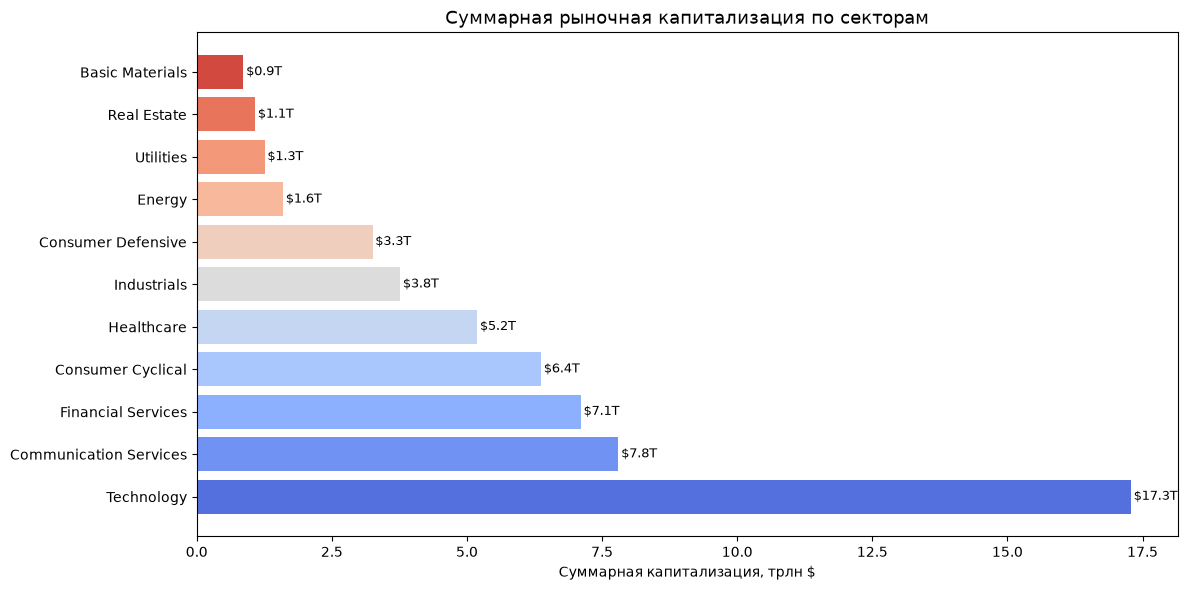

In [10]:
# График 3: Market Cap по секторам
sector_mc = companies.groupby('Sector')['Marketcap'].sum().sort_values(ascending=False) / 1e12
fig, ax = plt.subplots(figsize=(12, 6))
colors = sns.color_palette('coolwarm', len(sector_mc))
bars = ax.barh(sector_mc.index, sector_mc.values, color=colors)
ax.set_xlabel('Суммарная капитализация, трлн $')
ax.set_title('Суммарная рыночная капитализация по секторам', fontsize=13)
for bar, val in zip(bars, sector_mc.values):
    ax.text(val + 0.05, bar.get_y() + bar.get_height()/2,
            f'${val:.1f}T', va='center', fontsize=9)
plt.tight_layout()
plt.show()


Секторальная принадлежность из sp500_companies.csv используется как контрольная метка, позволяющая увидеть, какие макроэкономические тренды модель смогла "прочитать" сквозь призму голых цифр доходности

---
## 2.6 Построение итогового датасета для моделирования

### Полнота и пригодность данных

Показываются отдельно: исходная выгрузка, восстановленные истории, готовые
273 признака, наблюдаемые метки и OOS-кандидаты. Наличие котировок после
IPO ещё не означает наличия 260-дневной истории для X_260.


In [11]:
legacy_raw = pd.read_csv(DATA_DIR/'sp500_stocks.csv',usecols=['Date','Symbol','Close'],parse_dates=['Date'])
legacy_coverage = legacy_raw.groupby('Symbol').Close.count().rename('legacy_quotes')
coverage_audit = download_audit[download_audit.Symbol != '^GSPC'].merge(legacy_coverage,on='Symbol',how='left')
n_symbols_file = len(requested_symbols)
price_raw = price_downloaded.copy()
coverage_funnel = [('Запрошено фиксированных тикеров',n_symbols_file,'снимок состава 2024'),
                   ('Загружены непустые истории',price_raw.Symbol.nunique(),'см. manifest')]
coverage_audit.to_csv(CACHE_DIR/'coverage_audit.csv',index=False)
display(coverage_audit)
print('Старых непустых историй:',int(legacy_coverage.gt(0).sum()))
print('Новых непустых историй:',price_raw.Symbol.nunique())
print('Данные исходного CSV не подмешиваются к новой выгрузке.')


,Symbol,YahooSymbol,status,Source,SourceURL,PriceConvention,n_quotes,first,last,required_actual_end,covers_required_end,missing_requested_end_sessions,sha256,source_file,error,legacy_quotes
0,A,A,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,0e520b703ee60465d270ca6cbc4dd152bb82976b69ffbd...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,,0
1,AAPL,AAPL,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,51d26b1575b5b6bf13768dcefdcc7a834e6ab611e89470...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,,0
2,ABBV,ABBV,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,3ff7e985c6f9a21b462ed626ed630cf2a1b2cc8c90e6b9...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,,3014
3,ABNB,ABNB,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,1014,2020-12-10,2024-12-20,2024-12-09,True,0,dea1e72659ee3ae866776a5cb38f389533521dd564d0bc...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,,0
4,ABT,ABT,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,9aacb188887fa381cc4b3cc76eb3066dd31147cf6989f7...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,,3768
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
497,XYL,XYL,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,9380e88ae8fb3c090c959278e7f18ffc55f993cb2e2c67...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,,3319
498,YUM,YUM,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,5c9ec498ab068641fcc5384505f535431a0ea6cb81d7d2...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,,0
499,ZBH,ZBH,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,fca5d79635025134c44ab551fa38cb876b8d4a04ddd49e...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,,0
500,ZBRA,ZBRA,ok,Yahoo Close,,split_adjusted_close_excluding_dividends,2517,2014-12-22,2024-12-20,2024-12-09,True,0,567cf5da2ea72d3d2018ee6327a86bd17d2a9a1a9ed6dd...,C:\Users\dima\Desktop\Важные файлы с МГТУ им. ...,,0


Старых непустых историй: 172
Новых непустых историй: 495
Данные исходного CSV не подмешиваются к новой выгрузке.


In [12]:
K_VALUES = rr.K_VALUES
FEAT_COLS = rr.BASE_FEATURES
price_all = price_raw.sort_values(['Symbol','Date']).copy()
# Полная панель цен нужна в бэктесте, включая хвост без меток.
full_price_panel = price_all[['Date','Symbol','Close']].copy()
daily_df = rr.build_base_panel(price_all,index_df,horizon=LABEL_DAYS)
print('До прогрева:',daily_df.shape)


До прогрева: (1245915, 19)


In [13]:
pd.DataFrame(price_all['Close'].describe())


,Close
count,1.211382e+06
mean,1.841506e+02
std,2.452396e+03
min,4.785000e-01
25%,4.493000e+01
50%,7.946000e+01
75%,1.409300e+02
max,1.139000e+05


Описательные характеристики цен выводятся выше заново. Различия между
средним и медианой не доказывают предсказуемость относительных доходностей.


In [14]:
daily_df = rr.add_statistical_features(daily_df)
ALL_FEAT_COLS = rr.ALL_FEATURES.copy()
ext_feature_cols = rr.EXTRA_FEATURES.copy()
assert len(ALL_FEAT_COLS) == 273
feature_ready = daily_df[ALL_FEAT_COLS].notna().all(axis=1)
prediction_panel = daily_df.loc[feature_ready].copy()  # independent of FUTURE label availability
valid_rows = feature_ready & daily_df.Target.notna()
available_counts = daily_df.loc[valid_rows].groupby('Symbol').size()
dropped_by_filter = sorted(available_counts[available_counts < 270].index)
eligibility = pd.DataFrame({'Symbol':requested_symbols}).merge(
    available_counts.rename('eligible_rows'),on='Symbol',how='left').fillna({'eligible_rows':0})
eligibility['excluded_by_old_270_filter'] = eligibility.eligible_rows.lt(270)
eligibility.to_csv(CACHE_DIR/'model_eligibility.csv',index=False)
daily_df = daily_df.loc[valid_rows].copy()
if MIN_MODEL_DAYS:
    daily_df = daily_df[daily_df.Symbol.isin(available_counts[available_counts>=MIN_MODEL_DAYS].index)]
daily_df['Target'] = daily_df.Target.astype(int)
coverage_funnel.append(('Есть 273 признака и полный таргет',daily_df.Symbol.nunique(),'IPO/пропуски/прогрев'))
funnel_df = pd.DataFrame(coverage_funnel,columns=['Шаг','Тикеров','Причина отсева'])
display(funnel_df)
funnel_df.to_csv(CACHE_DIR/'coverage_funnel.csv',index=False)
print('Рабочих строк:',len(daily_df),'бумаг:',daily_df.Symbol.nunique())
print('Класс 0:',(daily_df.Target==0).mean(),'класс 1:',daily_df.Target.mean())
# Target-зависимый EDA ограничен доступными до OOS метками.
eda_train = daily_df[(daily_df.Date<OOS_START)&(daily_df.LabelEnd<OOS_START)].copy()


,Шаг,Тикеров,Причина отсева
0,Запрошено фиксированных тикеров,502,снимок состава 2024
1,Загружены непустые истории,495,см. manifest
2,Есть 273 признака и полный таргет,492,IPO/пропуски/прогрев


Рабочих строк: 1077612 бумаг: 492
Класс 0: 0.5177392233939488 класс 1: 0.48226077660605116


In [15]:
# Итоговый датасет для моделирования - только ценовые признаки

print('Итоговые признаки:')
print(ALL_FEAT_COLS)
print(f'\nПримеры данных:')
daily_df


Итоговые признаки:
['X_1', 'X_5', 'X_10', 'X_15', 'X_20', 'X_40', 'X_60', 'X_80', 'X_100', 'X_120', 'X_150', 'X_180', 'X_260', 'X_1_mean_2', 'X_1_std_2', 'X_1_min_2', 'X_1_max_2', 'X_1_cv_2', 'X_1_mean_5', 'X_1_std_5', 'X_1_min_5', 'X_1_max_5', 'X_1_cv_5', 'X_1_mean_10', 'X_1_std_10', 'X_1_min_10', 'X_1_max_10', 'X_1_cv_10', 'X_1_mean_20', 'X_1_std_20', 'X_1_min_20', 'X_1_max_20', 'X_1_cv_20', 'X_5_mean_2', 'X_5_std_2', 'X_5_min_2', 'X_5_max_2', 'X_5_cv_2', 'X_5_mean_5', 'X_5_std_5', 'X_5_min_5', 'X_5_max_5', 'X_5_cv_5', 'X_5_mean_10', 'X_5_std_10', 'X_5_min_10', 'X_5_max_10', 'X_5_cv_10', 'X_5_mean_20', 'X_5_std_20', 'X_5_min_20', 'X_5_max_20', 'X_5_cv_20', 'X_10_mean_2', 'X_10_std_2', 'X_10_min_2', 'X_10_max_2', 'X_10_cv_2', 'X_10_mean_5', 'X_10_std_5', 'X_10_min_5', 'X_10_max_5', 'X_10_cv_5', 'X_10_mean_10', 'X_10_std_10', 'X_10_min_10', 'X_10_max_10', 'X_10_cv_10', 'X_10_mean_20', 'X_10_std_20', 'X_10_min_20', 'X_10_max_20', 'X_10_cv_20', 'X_15_mean_2', 'X_15_std_2', 'X_15_min_2', 

,Date,Close,SP500,Symbol,X_1,X_5,X_10,X_15,X_20,X_40,...,X_260_mean_10,X_260_std_10,X_260_min_10,X_260_max_10,X_260_cv_10,X_260_mean_20,X_260_std_20,X_260_min_20,X_260_max_20,X_260_cv_20
261,2016-01-06,40.730000,1990.260010,A,1.755437,0.390951,1.283415,2.759354,4.253155,11.980365,...,1.333035,2.169534,-0.201057,2.867127,1.414213,1.333035,2.169534,-0.201057,2.867127,1.414213
262,2016-01-07,39.000000,1943.089966,A,-1.877438,-1.688339,-0.683363,0.474253,0.568520,9.366504,...,1.384645,1.536694,-0.201057,2.867127,1.011860,1.384645,1.536694,-0.201057,2.867127,1.011860
263,2016-01-08,38.590000,1922.030029,A,0.032556,-1.737053,-0.721646,0.430878,0.301349,9.277168,...,1.348558,1.256780,-0.201057,2.867127,0.867290,1.348558,1.256780,-0.201057,2.867127,0.867290
264,2016-01-11,37.939999,1923.670044,A,-1.769705,-2.336906,-3.303965,-1.174466,-1.759844,8.036501,...,1.035084,1.294585,-0.218812,2.867127,1.076102,1.035084,1.294585,-0.218812,2.867127,1.076102
265,2016-01-12,38.189999,1938.680054,A,-0.121345,-1.950808,-2.863480,-1.428845,-1.314514,7.111120,...,0.716434,1.396420,-0.876817,2.867127,1.215691,0.716434,1.396420,-0.876817,2.867127,1.215691
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1245900,2024-12-02,176.809998,6047.149902,ZTS,0.645310,-1.388265,-2.053482,-0.866465,-8.381964,-12.105058,...,-31.454452,2.159314,-34.538571,-26.869262,0.068649,-31.202653,2.946740,-37.520101,-24.331530,0.094439
1245901,2024-12-03,176.940002,6049.879883,ZTS,0.028383,-2.034461,-2.356584,-0.360162,-4.897786,-11.735042,...,-32.021643,1.449278,-34.538571,-29.868290,0.045259,-31.317031,2.952355,-37.520101,-24.331530,0.094273
1245902,2024-12-04,175.320007,6086.490234,ZTS,-1.520704,-1.293395,-3.001510,-0.931115,-5.223815,-12.262327,...,-32.612573,1.757723,-36.025032,-29.868290,0.053897,-31.555157,3.134190,-37.520101,-24.331530,0.099324
1245903,2024-12-05,174.770004,6075.109863,ZTS,-0.126736,-2.387727,-3.182543,-2.781343,0.118986,-12.985236,...,-32.980532,2.026166,-36.025032,-29.868290,0.061435,-31.473081,2.987839,-36.025032,-24.331530,0.094933


In [16]:
daily_df.drop('Date', axis=1, inplace=False).describe()


C:\Users\dima\AppData\Local\Temp\ipykernel_30504\114929476.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  daily_df.drop('Date', axis=1, inplace=False).describe()


,Close,SP500,X_1,X_5,X_10,X_15,X_20,X_40,X_60,X_80,...,X_260_mean_10,X_260_std_10,X_260_min_10,X_260_max_10,X_260_cv_10,X_260_mean_20,X_260_std_20,X_260_min_20,X_260_max_20,X_260_cv_20
count,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06,...,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06,1.077612e+06
mean,1.739321e+02,3.500787e+03,8.115710e-03,4.392369e-02,8.569770e-02,1.303368e-01,1.718579e-01,3.359986e-01,4.966818e-01,6.439937e-01,...,2.621862e+00,3.187445e+00,-2.046952e+00,7.461243e+00,2.810243e-01,2.636200e+00,4.429634e+00,-4.612908e+00,1.035074e+01,3.531676e-01
min,6.305000e-01,1.829080e+03,-8.240296e+01,-8.452048e+01,-8.462501e+01,-8.895973e+01,-8.820203e+01,-9.564938e+01,-1.058565e+02,-1.160463e+02,...,-1.400689e+02,2.249603e-03,-1.452271e+02,-1.350419e+02,1.722238e-04,-1.373517e+02,2.249603e-03,-1.452271e+02,-1.329438e+02,1.722238e-04
25%,4.703000e+01,2.663990e+03,-7.586511e-01,-1.825799e+00,-2.689824e+00,-3.388249e+00,-3.978695e+00,-5.824366e+00,-7.298760e+00,-8.430117e+00,...,-1.663148e+01,1.576277e+00,-2.033563e+01,-1.296413e+01,8.155999e-02,-1.646781e+01,2.266508e+00,-2.230053e+01,-1.070778e+01,1.170926e-01
50%,8.341000e+01,3.298460e+03,3.103465e-03,2.767041e-03,-1.025239e-02,-2.155473e-02,-8.128881e-03,2.321862e-02,3.436495e-02,-8.162510e-02,...,-4.915905e-01,2.361878e+00,-4.333507e+00,3.351854e+00,1.518194e-01,-4.438729e-01,3.337758e+00,-6.438136e+00,5.642895e+00,2.157449e-01
75%,1.485000e+02,4.304760e+03,7.609373e-01,1.828482e+00,2.701958e+00,3.391831e+00,3.996200e+00,5.900464e+00,7.367846e+00,8.510090e+00,...,1.635810e+01,3.658861e+00,1.191998e+01,2.093735e+01,3.315537e-01,1.628163e+01,5.098465e+00,9.455714e+00,2.366381e+01,4.650020e-01
max,1.139000e+05,6.090270e+03,9.776355e+01,1.318404e+02,1.230425e+02,1.479457e+02,2.171697e+02,2.652858e+02,3.912065e+02,4.177241e+02,...,1.047308e+03,3.339033e+02,9.396308e+02,1.169177e+03,2.611426e+00,9.758008e+02,3.259294e+02,7.565618e+02,1.169177e+03,2.815920e+00
std,2.108987e+03,1.030266e+03,1.750307e+00,3.866472e+00,5.343597e+00,6.563551e+00,7.576356e+00,1.078683e+01,1.332777e+01,1.562315e+01,...,3.541344e+01,3.737464e+00,3.261690e+01,3.902428e+01,3.134251e-01,3.509917e+01,4.940535e+00,3.101336e+01,4.103409e+01,3.334715e-01


Признаки готовы к хронологическому разбиению. Прогрев X_260 использует
прошлое; он не требует 260-дневного разрыва перед тестом.


### Зависимость целевой переменной от ключевых признаков

In [17]:
from sklearn.feature_selection import mutual_info_classif
df_scoring = eda_train.sample(min(5000,len(eda_train)),random_state=SEED)
X_score,y_score = df_scoring[ALL_FEAT_COLS],df_scoring.Target
importances = mutual_info_classif(X_score,y_score,random_state=SEED)
feature_info = pd.DataFrame({'Feature':ALL_FEAT_COLS,'Importance':importances}).sort_values('Importance',ascending=False)
display(feature_info.head(5))
print('Описательный EDA на train; признаки из модели не удаляются.')


,Feature,Importance
225,X_150_min_10,0.031404
81,X_15_max_5,0.026596
131,X_40_max_20,0.024734
230,X_150_min_20,0.024627
71,X_10_max_20,0.023646


Описательный EDA на train; признаки из модели не удаляются.


C:\Users\dima\AppData\Local\Temp\ipykernel_30504\2203834324.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=tmp, x='Target_label', y=feat,
C:\Users\dima\AppData\Local\Temp\ipykernel_30504\2203834324.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=tmp, x='Target_label', y=feat,
C:\Users\dima\AppData\Local\Temp\ipykernel_30504\2203834324.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=tmp, x='Target_label', y=feat,
C:\Users\dima\AppData\Local\Temp\ipykernel_30504\2203834324.py:13: FutureWarning: 

Passing

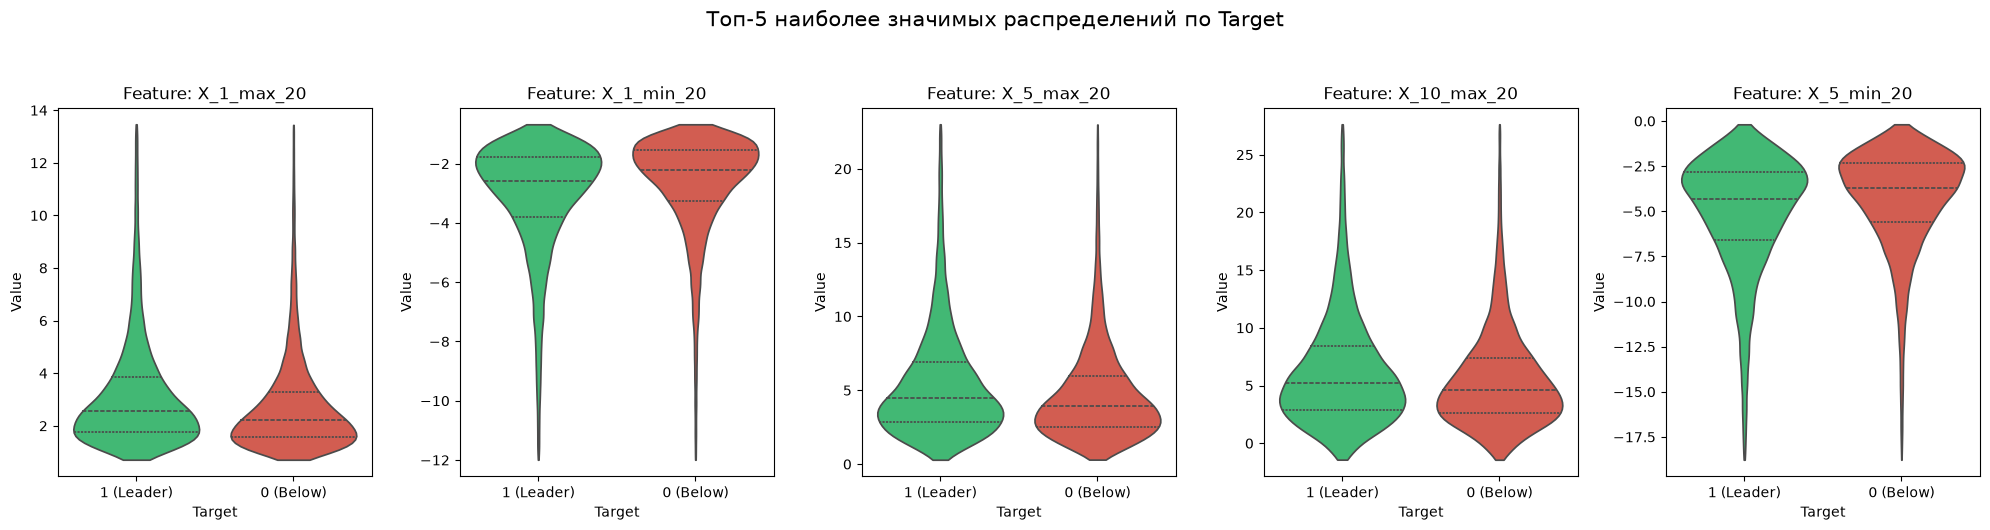

In [18]:
# Выбранные топ-5 признаков на основе анализа распределений
SHOW_FEATS = ['X_1_max_20', 'X_1_min_20', 'X_5_max_20', 'X_10_max_20', 'X_5_min_20']

sample = eda_train.dropna(subset=SHOW_FEATS + ['Target']).sample(min(50000, len(eda_train)), random_state=42)
sample['Target_label'] = sample['Target'].map({0: '0 (Below)', 1: '1 (Leader)'})

fig, axes = plt.subplots(1, len(SHOW_FEATS), figsize=(20, 5))
for ax, feat in zip(axes, SHOW_FEATS):
    # Визуализация с обрезкой 1% выбросов
    q1, q99 = sample[feat].quantile([0.01, 0.99])
    tmp = sample[(sample[feat] >= q1) & (sample[feat] <= q99)]

    sns.violinplot(data=tmp, x='Target_label', y=feat,
                   palette={'0 (Below)': '#e74c3c', '1 (Leader)': '#2ecc71'},
                   ax=ax, inner='quartile', cut=0)

    ax.set_title(f'Feature: {feat}', fontsize=12)
    ax.set_xlabel('Target')
    ax.set_ylabel('Value')

fig.suptitle('Топ-5 наиболее значимых распределений по Target', fontsize=15, y=1.05)
plt.tight_layout()
plt.show()


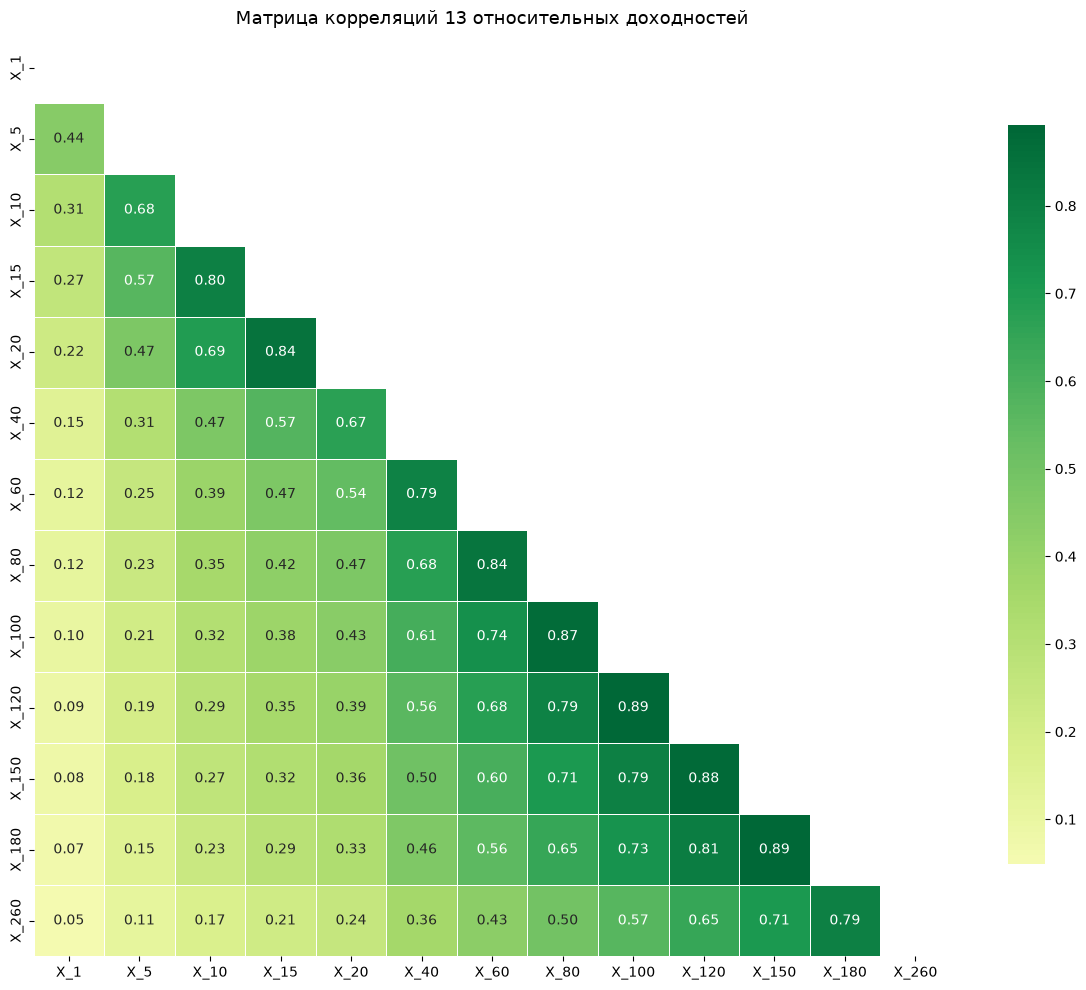

Корреляции описывают текущий train и не доказывают предсказуемость.
Выводы о группах признаков делаются по текущей матрице.


In [19]:
# EDA: матрица корреляций между 13 признаками
sample_corr = eda_train[FEAT_COLS].dropna().sample(min(30000, len(eda_train)), random_state=42)
corr = sample_corr.corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='RdYlGn', center=0, annot=True, fmt='.2f',
            linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Матрица корреляций 13 относительных доходностей', fontsize=13)
plt.tight_layout()
plt.show()
print('Корреляции описывают текущий train и не доказывают предсказуемость.')
print('Выводы о группах признаков делаются по текущей матрице.')


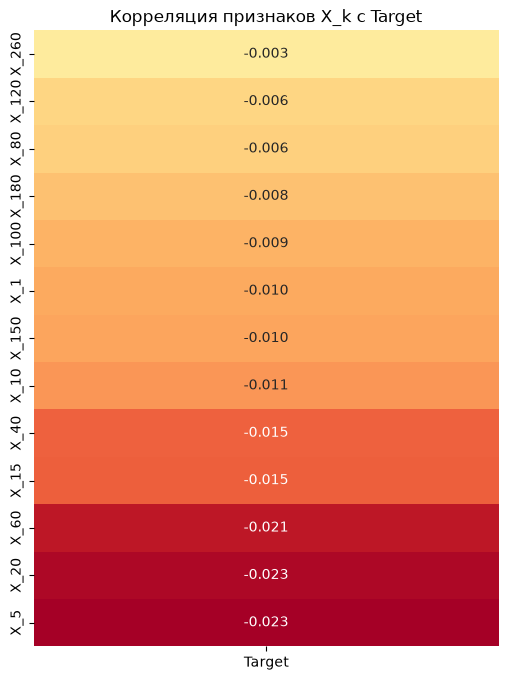

Наиболее значимые признаки для таргета:
         Target
X_260 -0.002995
X_120 -0.005585
X_80  -0.006169


In [20]:
# 1. Выбираем признаки и таргет
cols_to_corr = FEAT_COLS + ['Target']
sample_corr = eda_train[cols_to_corr].dropna().sample(min(30000, len(eda_train)), random_state=42)

# 2. Считаем матрицу
corr = sample_corr.corr()

# 3. Выделяем только корреляцию признаков с таргетом
target_corr = corr[['Target']].drop('Target').sort_values(by='Target', ascending=False)

# 4. Визуализация
plt.figure(figsize=(6, 8))
sns.heatmap(target_corr, annot=True, cmap='RdYlGn', center=0, fmt='.3f', cbar=False)
plt.title('Корреляция признаков X_k с Target')
plt.show()

print("Наиболее значимые признаки для таргета:")
print(target_corr.head(3))


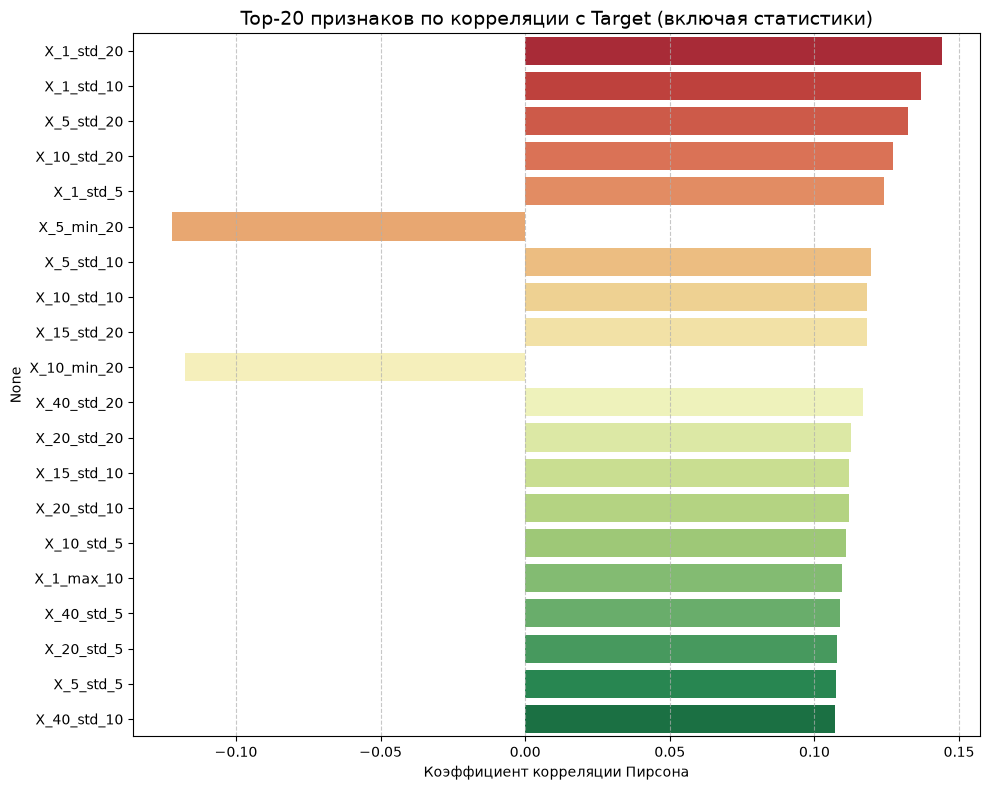

In [21]:
# 1. Список всех признаков (базовые + 270 расширенных)
all_cols = ALL_FEAT_COLS + ['Target']

# 2. Считаем корреляцию только со столбцом Target
# Берем выборку, чтобы расчет прошел быстрее
correlations = eda_train[all_cols].sample(min(50000, len(eda_train)),random_state=SEED).corr()['Target'].drop('Target')

# 3. Берем абсолютные значения, так как сильная отрицательная корреляция так же важна, как и положительная
top_features = correlations.abs().sort_values(ascending=False).head(20)
top_features_names = top_features.index

# 4. Визуализация Top-20 самых «говорящих» признаков
plt.figure(figsize=(10, 8))
sns.barplot(x=correlations[top_features_names].values, y=top_features_names,
            hue=top_features_names, palette='RdYlGn', legend=False)
plt.title('Top-20 признаков по корреляции с Target (включая статистики)', fontsize=14)
plt.xlabel('Коэффициент корреляции Пирсона')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


Интерпретация зависит от текущего прогона. EDA/PCA/t-SNE не доказывают
    прибыльность и не используются для выбора модели на тестовой части.
    Все 273 признака сохраняются независимо от ранга важности.


Интерпретация зависит от текущего прогона. EDA/PCA/t-SNE не доказывают
    прибыльность и не используются для выбора модели на тестовой части.
    Все 273 признака сохраняются независимо от ранга важности.


## 2.7 Признаки: ANOVA и проверка зависимости по блокам дат

Прежний «критерий Фишера» — однофакторный ANOVA F-тест, не точный тест
Фишера для таблиц сопряжённости. Для его 273 p-values применяется BH.
Обычные ANOVA-предположения независимости строк в панели нарушены, поэтому
результат описательный и не считается достаточным доказательством сигнала.

Дополнительно я проверяю разность средних признака между классами общим
bootstrap смежных блоков train-дат: внутри дня сохраняются все бумаги.
Публикуются p, BH и более консервативная BY, допускающая зависимость проверок.
Все 273 признака остаются в моделях независимо от этих результатов.


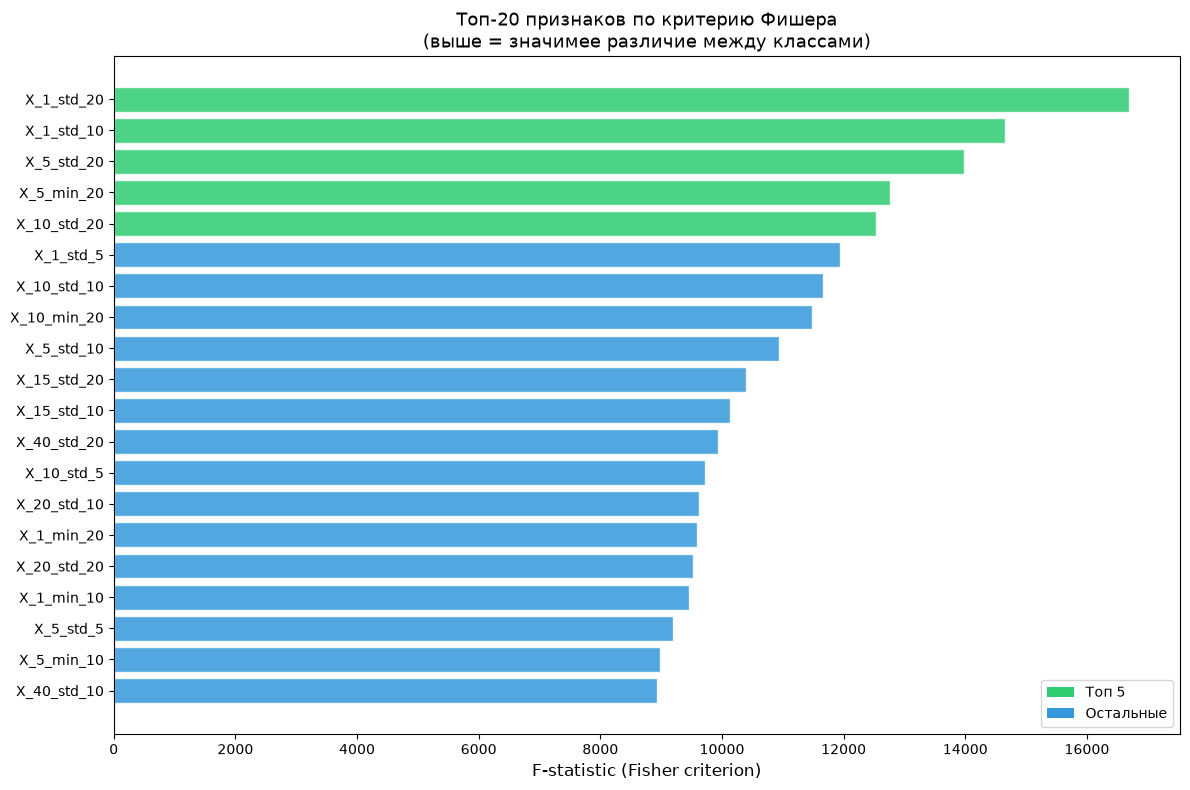

Всего признаков: 273
ANOVA F-тест (не точный тест Фишера), BH q<0.05: 259
Зависимость строк панели ограничивает интерпретацию ANOVA; q — описательный результат.

Топ-10 признаков по Fisher criterion:
                   f_stat  p_value
X_1_std_20   16695.126630      0.0
X_1_std_10   14653.333315      0.0
X_5_std_20   13975.912157      0.0
X_5_min_20   12767.769201      0.0
X_10_std_20  12536.629227      0.0
X_1_std_5    11938.512544      0.0
X_10_std_10  11656.128316      0.0
X_10_min_20  11481.624758      0.0
X_5_std_10   10942.672604      0.0
X_15_std_20  10397.350095      0.0


,mean_diff,null,n_days,block,seed,n_class0,n_class1,ci_low,ci_high,p,n_valid,n_boot,alpha,method,status,valid_fraction,q_BH,q_BY
feature,,,,,,,,,,,,,,,,,,
X_1_std_5,0.276018,0.0,1603,21,42,395987,366987,0.187641,0.344422,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.002999,0.018556
X_1_min_5,-0.357083,0.0,1603,21,42,395987,366987,-0.449825,-0.227386,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.002999,0.018556
X_1_max_5,0.327398,0.0,1603,21,42,395987,366987,0.231540,0.411095,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.002999,0.018556
X_1_std_10,0.279163,0.0,1603,21,42,395987,366987,0.191500,0.349188,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.002999,0.018556
X_1_max_10,0.453463,0.0,1603,21,42,395987,366987,0.304635,0.579345,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.002999,0.018556
X_1_min_10,-0.444023,0.0,1603,21,42,395987,366987,-0.552837,-0.299962,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.002999,0.018556
X_1_min_20,-0.537163,0.0,1603,21,42,395987,366987,-0.669623,-0.362506,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.002999,0.018556
X_1_std_20,0.273520,0.0,1603,21,42,395987,366987,0.189232,0.338845,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.002999,0.018556
X_180_std_10,0.514778,0.0,1603,21,42,395987,366987,0.377052,0.628873,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.002999,0.018556


Date-block q_BH<.05: 116
Консервативная q_BY<.05: 93
ANOVA+BH — описательная диагностика. Основной зависимый анализ — date blocks; BY учитывает произвольную зависимость между проверками признаков.


In [22]:
# Fisher's criterion для определения важности признаков
from scipy.stats import f_oneway

# Подготовим данные для расчёта F-статистики
fisher_scores = {}
X_for_fisher = eda_train[ALL_FEAT_COLS + ['Target']].dropna()
y_fisher = X_for_fisher['Target']

for col in ALL_FEAT_COLS:
    # Разделяем данные по классам
    class_0 = X_for_fisher[y_fisher == 0][col].values
    class_1 = X_for_fisher[y_fisher == 1][col].values

    # Вычисляем F-статистику (аналог ANOVA для двух групп)
    f_stat, p_value = f_oneway(class_0, class_1)
    fisher_scores[col] = {'f_stat': f_stat, 'p_value': p_value}

fisher_df = pd.DataFrame(fisher_scores).T.sort_values('f_stat', ascending=False)
fisher_df['q_BH'] = rr.bh_adjust(fisher_df.p_value.fillna(1))
fisher_df.to_csv(CACHE_DIR/'anova_bh.csv')

# Визуализация топ-20 признаков по Fisher criterion
fig, ax = plt.subplots(figsize=(12, 8))
top_fisher = fisher_df.head(20)
colors = ['#2ecc71' if idx < 5 else '#3498db' for idx in range(len(top_fisher))]
ax.barh(range(len(top_fisher)), top_fisher['f_stat'].values, color=colors, edgecolor='white', alpha=0.85)
ax.set_yticks(range(len(top_fisher)))
ax.set_yticklabels(top_fisher.index)
ax.set_xlabel('F-statistic (Fisher criterion)', fontsize=12)
ax.set_title('Топ-20 признаков по критерию Фишера\n(выше = значимее различие между классами)', fontsize=13)
ax.invert_yaxis()

# Легенда
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2ecc71', label='Топ 5'),
                   Patch(facecolor='#3498db', label='Остальные')]
ax.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.show()

print(f'Всего признаков: {len(ALL_FEAT_COLS)}')
print(f'ANOVA F-тест (не точный тест Фишера), BH q<0.05: {(fisher_df.q_BH < .05).sum()}')
print('Зависимость строк панели ограничивает интерпретацию ANOVA; q — описательный результат.')
print(f'\nТоп-10 признаков по Fisher criterion:')
print(fisher_df.head(10)[['f_stat', 'p_value']])
# Основная проверка связи признаков с классом учитывает зависимость строк:
# ресэмплирую смежные даты вместе со всеми акциями, только внутри train.
feature_block_df=ri.feature_block_tests(eda_train,ALL_FEAT_COLS,
    n_boot=N_BOOT,block=BOOT_BLOCK_DAYS,seed=SEED)
feature_block_df.to_csv(CACHE_DIR/'feature_date_block_tests.csv')
display(feature_block_df.sort_values('q_BY').head(20))
print('Date-block q_BH<.05:',int((feature_block_df.q_BH<.05).sum()))
print('Консервативная q_BY<.05:',int((feature_block_df.q_BY<.05).sum()))
print('ANOVA+BH — описательная диагностика. Основной зависимый анализ — date blocks; '
      'BY учитывает произвольную зависимость между проверками признаков.')


Интерпретация зависит от текущего прогона. EDA/PCA/t-SNE не доказывают
    прибыльность и не используются для выбора модели на тестовой части.
    Все 273 признака сохраняются независимо от ранга важности.


---
# 3. Построение моделей и валидация
## 3.1 Задача и выбор алгоритмов

Задача — бинарная классификация события достижения относительного уровня,
а не прогноз одного ценового ряда. Я сравниваю LR, RF, XGBoost, HistGB и KNN;
FLAML — дополнительный AutoML baseline, soft voting — дополнительный ансамбль.
Это сравнение конкретных конфигураций, а не доказательство превосходства
семейств алгоритмов при оптимальном подборе параметров.
Основная экономическая модель RF зафиксирована заранее.


In [23]:
df_sorted = daily_df.sort_values(['Date','Symbol']).reset_index(drop=True)
df_prediction = prediction_panel.sort_values(['Date','Symbol']).reset_index(drop=True)
calendar = pd.DatetimeIndex(index_df.Date.sort_values().unique())
first_oos_pos = calendar.searchsorted(OOS_START)
last_train_date = calendar[first_oos_pos-GAP_DAYS-1]
train_df = df_sorted[(df_sorted.Date<=last_train_date)&(df_sorted.LabelEnd<OOS_START)].copy()
test_df = df_sorted[df_sorted.Date.between(OOS_START,OOS_END)].copy()
assert train_df.LabelEnd.max() < test_df.Date.min()
FEATURE_COLS = ALL_FEAT_COLS.copy()
X_train,y_train = train_df[FEATURE_COLS],train_df.Target
X_test,y_test = test_df[FEATURE_COLS],test_df.Target
cv = rr.date_cv_splits(train_df,n_splits=5,gap=GAP_DAYS)
for tag,df in [('train',train_df),('test',test_df)]:
    print(tag,len(df),df.Date.min(),df.Date.max(),'class 0',1-df.Target.mean(),'class 1',df.Target.mean())
print('Последний LabelEnd train:',train_df.LabelEnd.max(),'первый test:',test_df.Date.min())


train 762974 2016-01-06 00:00:00 2022-05-17 00:00:00 class 0 0.5190045794483167 class 1 0.48099542055168326
test 305354 2022-06-02 00:00:00 2024-11-22 00:00:00 class 0 0.5116913484021823 class 1 0.4883086515978176
Последний LabelEnd train: 2022-06-01 00:00:00 первый test: 2022-06-02 00:00:00


In [24]:
df_sorted.head()


,Date,Close,SP500,Symbol,X_1,X_5,X_10,X_15,X_20,X_40,...,X_260_mean_10,X_260_std_10,X_260_min_10,X_260_max_10,X_260_cv_10,X_260_mean_20,X_260_std_20,X_260_min_20,X_260_max_20,X_260_cv_20
0,2016-01-06,40.730000,1990.26001,A,1.755437,0.390951,1.283415,2.759354,4.253155,11.980365,...,1.333035,2.169534,-0.201057,2.867127,1.414213,1.333035,2.169534,-0.201057,2.867127,1.414213
1,2016-01-06,25.174999,1990.26001,AAPL,-0.645429,-3.154861,-4.648876,-8.906170,-10.683591,-11.628514,...,-6.094894,0.016507,-6.106566,-6.083222,0.002708,-6.094894,0.016507,-6.106566,-6.083222,0.002708
2,2016-01-06,57.380001,1990.26001,ABBV,1.328974,0.757007,3.627983,5.066092,6.152081,-5.335896,...,-8.888669,3.495120,-11.360092,-6.417246,0.393211,-8.888669,3.495120,-11.360092,-6.417246,0.393211
3,2016-01-06,42.560001,1990.26001,ABT,0.472777,-2.875870,-1.832242,-3.454392,-2.405275,-1.538436,...,-3.481482,1.391568,-4.465469,-2.497495,0.399706,-3.481482,1.391568,-4.465469,-2.497495,0.399706
4,2016-01-06,23.070000,1990.26001,ACGL,1.470730,1.389395,0.853822,0.678937,-1.025318,-1.948469,...,20.259511,0.018022,20.246768,20.272254,0.000890,20.259511,0.018022,20.246768,20.272254,0.000890


---
## 3.1.1 Анализ многомерности данных: PCA и t-SNE

**Цель:** Визуализировать структуру данных в 2D пространстве, выявить естественные кластеры и разделимость классов.

### PCA (Principal Component Analysis)
- **Линейный** метод уменьшения размерности
- Сохраняет глобальную структуру данных
- Быстрый и интерпретируемый
- Подходит для понимания глобальных паттернов

### t-SNE (t-Distributed Stochastic Neighbor Embedding)
- **Нелинейный** метод уменьшения размерности
- Хорошо сохраняет локальную структуру данных
- Выявляет кластеры и выбросы
- Медленнее, но часто дает более информативную визуализацию

**Интерпретация:** Если классы 0 и 1 четко разделены в 2D пространстве PCA/t-SNE - это признак того, что задача легко решаема. Перекрытие облаков - признак высокой сложности.

Применяем PCA для визуализации...
Для отрисовки взята стратифицированная подвыборка: 5,000 из 762,974 точек (доля класса 1: 0.481 против 0.481 на полной)


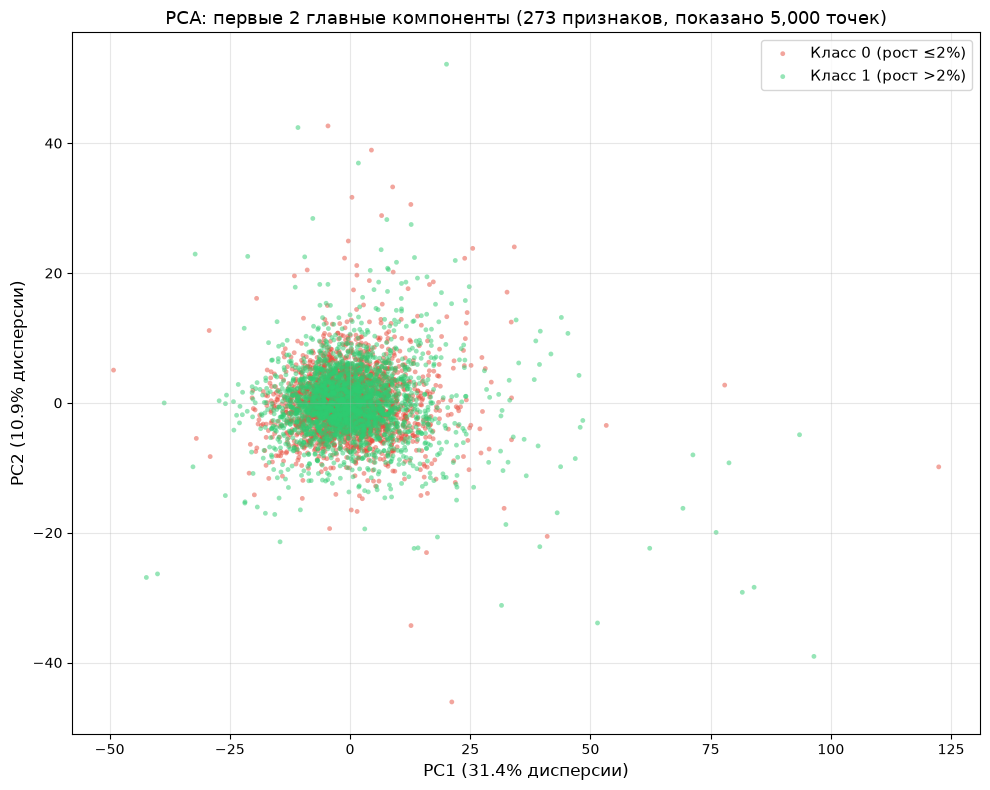

Доля объяснённой дисперсии PC1: 31.44%
Доля объяснённой дисперсии PC2: 10.86%
Суммарно: 42.30%


In [25]:
# PCA визуализация
from sklearn.decomposition import PCA

print('Применяем PCA для визуализации...')
X_train_clean = X_train.dropna()
y_train_clean = y_train.loc[X_train_clean.index]

# Масштабирование и PCA считаются на ПОЛНОЙ обучающей выборке, чтобы доли
# объяснённой дисперсии относились ко всем данным, а не к подвыборке.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train_clean)

pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

# ── Подвыборка для отрисовки ─────────────────────────────────────────────────
# Большое число точек с alpha=0.6 и s=30 сливаются в сплошное пятно, из которого
# ничего не видно, а t-SNE ниже на таком объёме считается больше получаса.
# Стратифицированная подвыборка фиксированного размера: доли классов
# сохраняются, картинка читается, сид зафиксирован.
rng_viz = np.random.default_rng(SEED)
y_arr = y_train_clean.to_numpy()

if len(y_arr) > VIZ_SAMPLE:
    per_class = {c: np.flatnonzero(y_arr == c) for c in np.unique(y_arr)}
    viz_idx = np.sort(np.concatenate([
        rng_viz.choice(pos, size=round(VIZ_SAMPLE * len(pos) / len(y_arr)),
                       replace=False)
        for pos in per_class.values()
    ]))
else:
    viz_idx = np.arange(len(y_arr))

y_viz = y_arr[viz_idx]
print(f'Для отрисовки взята стратифицированная подвыборка: '
      f'{len(viz_idx):,} из {len(y_arr):,} точек '
      f'(доля класса 1: {y_viz.mean():.3f} против {y_arr.mean():.3f} на полной)')

# ── Визуализация ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))
xy = X_pca[viz_idx]
ax.scatter(xy[y_viz == 0, 0], xy[y_viz == 0, 1], c='#e74c3c',
           label='Класс 0 (рост ≤2%)', alpha=0.5, s=12, edgecolors='none')
ax.scatter(xy[y_viz == 1, 0], xy[y_viz == 1, 1], c='#2ecc71',
           label='Класс 1 (рост >2%)', alpha=0.5, s=12, edgecolors='none')

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} дисперсии)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} дисперсии)', fontsize=12)
ax.set_title(f'PCA: первые 2 главные компоненты ({len(FEATURE_COLS)} признаков, '
             f'показано {len(viz_idx):,} точек)', fontsize=13)
ax.legend(loc='best', fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'pca_feature_space.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Доля объяснённой дисперсии PC1: {pca.explained_variance_ratio_[0]:.2%}')
print(f'Доля объяснённой дисперсии PC2: {pca.explained_variance_ratio_[1]:.2%}')
print(f'Суммарно: {sum(pca.explained_variance_ratio_):.2%}')


Интерпретация зависит от текущего прогона. EDA/PCA/t-SNE не доказывают
    прибыльность и не используются для выбора модели на тестовой части.
    Все 273 признака сохраняются независимо от ранга важности.


Применяем t-SNE: 5,000 точек x 50 компонент (PCA удержала 93.0% дисперсии)...


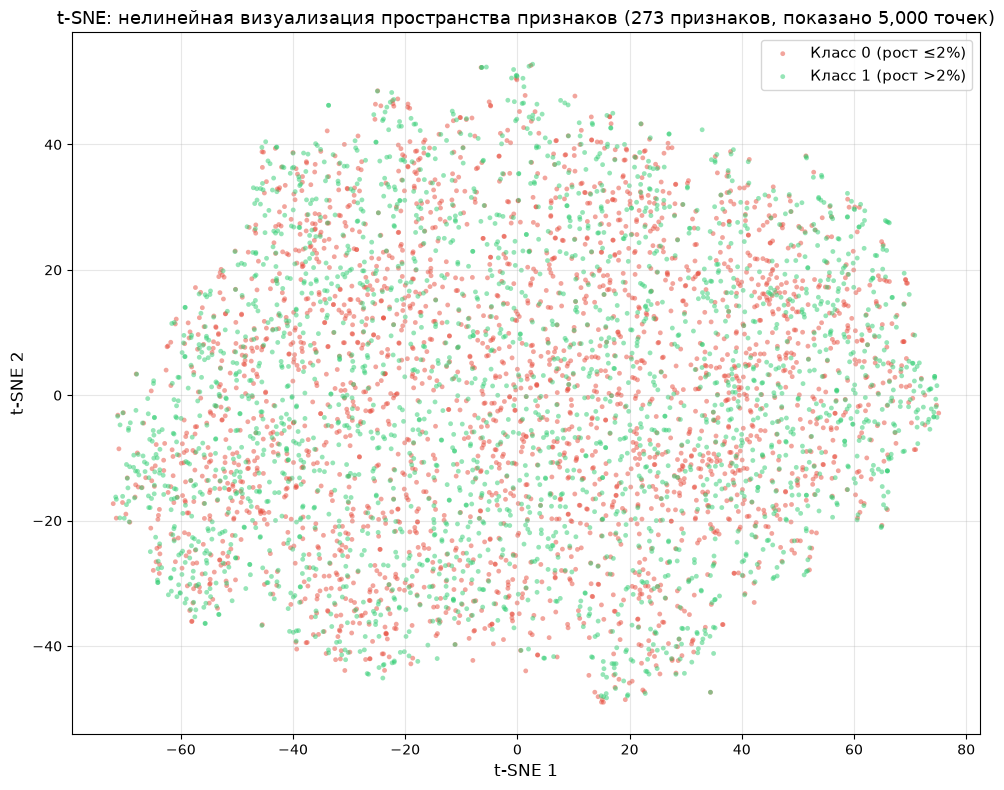

KL-дивергенция после 999 итераций: 2.095
Расстояния между кластерами на карте t-SNE не интерпретируются, а сама карта
зависит от perplexity - это иллюстрация зашумлённости данных, не доказательство.


In [26]:
# t-SNE визуализация
from sklearn.manifold import TSNE

n_pca = min(50, X_scaled.shape[1])
pca_prep = PCA(n_components=n_pca, random_state=SEED)
X_pca_prep = pca_prep.fit_transform(X_scaled)      # PCA на полной выборке
X_tsne_input = X_pca_prep[viz_idx]                 # t-SNE - на подвыборке

print(f'Применяем t-SNE: {X_tsne_input.shape[0]:,} точек x {n_pca} компонент '
      f'(PCA удержала {pca_prep.explained_variance_ratio_.sum():.1%} дисперсии)...')

tsne = TSNE(n_components=2, random_state=SEED, perplexity=30, max_iter=1000,
            init='pca', learning_rate='auto', verbose=0)
X_tsne = tsne.fit_transform(X_tsne_input)

# ── Визуализация ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(X_tsne[y_viz == 0, 0], X_tsne[y_viz == 0, 1], c='#e74c3c',
           label='Класс 0 (рост ≤2%)', alpha=0.5, s=12, edgecolors='none')
ax.scatter(X_tsne[y_viz == 1, 0], X_tsne[y_viz == 1, 1], c='#2ecc71',
           label='Класс 1 (рост >2%)', alpha=0.5, s=12, edgecolors='none')

ax.set_xlabel('t-SNE 1', fontsize=12)
ax.set_ylabel('t-SNE 2', fontsize=12)
ax.set_title(f't-SNE: нелинейная визуализация пространства признаков '
             f'({len(FEATURE_COLS)} признаков, показано {len(viz_idx):,} точек)',
             fontsize=13)
ax.legend(loc='best', fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'tsne_feature_space.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'KL-дивергенция после {tsne.n_iter_} итераций: {tsne.kl_divergence_:.3f}')
print('Расстояния между кластерами на карте t-SNE не интерпретируются, '
      'а сама карта\nзависит от perplexity - это иллюстрация зашумлённости '
      'данных, не доказательство.')


Интерпретация зависит от текущего прогона. EDA/PCA/t-SNE не доказывают
    прибыльность и не используются для выбора модели на тестовой части.
    Все 273 признака сохраняются независимо от ранга важности.


## 3.2 Методология обучения и протокол сравнения

Общий OOS: **2022-06-02…2024-11-22**, метка 10 дней, purge 10 дней.
Тестирование — одни и те же строки Date/Symbol и конфигурация модели.

| Вариант | История train | Обновление |
|---|---|---|
| Static | вся доступная до первого OOS | один раз |
| Expanding retrained | вся доступная до каждого фолда | каждые 21 день |
| Sliding retrained | последние 253 даты | каждые 21 день |

Expanding retrained vs Sliding retrained изолирует **форму окна** при общем
расписании и purge. Разный объём истории — свойство определения окна.
Static vs Expanding retrained оценивает обновление модели и доступной истории;
это не оценка «чистой частоты» при неизменном train.
Старый static с gap=260 не называется expanding walk-forward.


## 3.3 Реализация перебора гипотез — кросс-валидация

Пять expanding-фолдов строятся по уникальным датам внутри train. Все акции
одного дня лежат в одной части; перед validation удаляются 10 дат и все
строки с LabelEnd >= validation_start. Масштабирование обучается внутри Pipeline.
ROC-AUC — ранжирование; AP и дневной Precision@10 — качество отбора.
Достижение относительного уровня не равно положительному P&L сделки.


In [27]:
cv = rr.date_cv_splits(train_df,n_splits=5,gap=GAP_DAYS)


def make_models(seed=SEED):
    """Единый набор моделей для обеих схем валидации.

    Раньше expanding-схема работала на подобранных гиперпараметрах, а
    скользящее окно - на дефолтных. Сравнивались фактически разные модели,
    и разницу в доходности нельзя было отнести к схеме валидации.
    Теперь конфигурация одна и создаётся в одном месте.
    """
    gb = (HistGradientBoostingClassifier(max_iter=100, max_depth=4,
                                         random_state=seed, early_stopping=False)
          if USE_HIST_GB else
          GradientBoostingClassifier(n_estimators=100, max_depth=4,
                                     random_state=seed))
    return [
        ('Logistic Regression',
         Pipeline([('scaler', StandardScaler()),
                   ('clf', LogisticRegression(random_state=seed, max_iter=1000))])),
        ('Random Forest',
         RandomForestClassifier(criterion='entropy', max_depth=8,
                                n_estimators=100, random_state=seed, n_jobs=-1)),
        ('XGBoost',
         XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1,
                       subsample=0.8, eval_metric='logloss',
                       device=XGB_DEVICE, random_state=seed, verbosity=0)),
        ('Gradient Boosting', gb),
        ('KNN',
         Pipeline([('scaler', StandardScaler()),
                   ('clf', KNeighborsClassifier(n_neighbors=11,
                                                weights='distance', n_jobs=-1))])),
    ]


models = make_models()

if USE_HIST_GB:
    print('Внимание: GradientBoostingClassifier заменён на гистограммный '
          'HistGradientBoostingClassifier.')
    print('Тот же алгоритм с биннингом признаков: реализация с биннингом; время одной '
          'подгонки зависит от окружения,')
    print('что и делает прогон на десятках фолдов выполнимым. '
          'Замена отражена в тексте работы.\n')

results = []
print('Кросс-валидация (TimeSeriesSplit, 5 фолдов, метрика: ROC-AUC)...')
for name, model in models:
    scores = cross_val_score(model, X_train, y_train, scoring='roc_auc',
                             cv=cv, n_jobs=1)
    results.append({'Модель': name,
                    'CV ROC-AUC (mean)': scores.mean(),
                    'CV ROC-AUC (std)': scores.std(),
                    'folds': list(scores)})
    print(f'  {name:<25} {scores.mean():.4f} ± {scores.std():.4f}')

print('\n  AutoML (FLAML, 5-fold TimeSeriesSplit) ...')
flaml_fold_scores = []
splits = cv

for fold_i, (tr_idx, val_idx) in enumerate(splits):
    X_tr_fl, y_tr_fl = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
    X_val_fl, y_val_fl = X_train.iloc[val_idx], y_train.iloc[val_idx]

    inner_frame = train_df.iloc[tr_idx]
    inner_tr,inner_val = rr.date_cv_splits(inner_frame,n_splits=2,gap=GAP_DAYS)[-1]
    automl = FlamlAutoML()
    automl.fit(X_tr_fl.iloc[inner_tr], y_tr_fl.iloc[inner_tr],
               X_val=X_tr_fl.iloc[inner_val], y_val=y_tr_fl.iloc[inner_val], task='classification', metric='roc_auc',
               time_budget=30, seed=SEED, verbose=0,
               eval_method='holdout',split_type='time',
               estimator_list=['lrl2','rf','xgboost','histgb'])
    # Refit the selected estimator on the full OUTER train, then score outer validation.
    from sklearn.base import clone
    automl_selected = clone(automl.model.estimator).fit(X_tr_fl,y_tr_fl)
    fold_auc = roc_auc_score(y_val_fl, automl_selected.predict_proba(X_val_fl)[:, 1])
    flaml_fold_scores.append(fold_auc)
    print(f'    Fold {fold_i + 1}/5: ROC-AUC={fold_auc:.4f}  '
          f'best_estimator={automl.best_estimator}')

results.append({'Модель': 'FLAML AutoML',
                'CV ROC-AUC (mean)': float(np.mean(flaml_fold_scores)),
                'CV ROC-AUC (std)': float(np.std(flaml_fold_scores)),
                'folds': flaml_fold_scores})
print(f'  FLAML AutoML              {np.mean(flaml_fold_scores):.4f} ± '
      f'{np.std(flaml_fold_scores):.4f}')
flaml_best = automl

# Имя cv_results_df вместо results_df: ячейка скользящего окна ниже тоже
# собирает таблицу результатов, и раньше они перезаписывали друг друга -
# «лучшая модель» зависела от того, какая ячейка выполнилась последней.
cv_results_df = (pd.DataFrame(results)
                 .sort_values('CV ROC-AUC (mean)', ascending=False)
                 .reset_index(drop=True))

# Пофолдовые значения понадобятся для проверки значимости
cv_fold_scores = {r['Модель']: r['folds'] for r in results}

print('\nРазброс между соседними моделями сопоставим со стандартным '
      'отклонением по фолдам.')
print('Формальная проверка значимости этих различий - в разделе 3.6.')

cv_results_df.drop(columns='folds')


Внимание: GradientBoostingClassifier заменён на гистограммный HistGradientBoostingClassifier.
Тот же алгоритм с биннингом признаков: реализация с биннингом; время одной подгонки зависит от окружения,
что и делает прогон на десятках фолдов выполнимым. Замена отражена в тексте работы.

Кросс-валидация (TimeSeriesSplit, 5 фолдов, метрика: ROC-AUC)...
  Logistic Regression       0.5784 ± 0.0130
  Random Forest             0.5852 ± 0.0103
  XGBoost                   0.5826 ± 0.0097
  Gradient Boosting         0.5847 ± 0.0102
  KNN                       0.5335 ± 0.0058

  AutoML (FLAML, 5-fold TimeSeriesSplit) ...
    Fold 1/5: ROC-AUC=0.5497  best_estimator=lrl2
    Fold 2/5: ROC-AUC=0.5742  best_estimator=lrl2
    Fold 3/5: ROC-AUC=0.5937  best_estimator=lrl2
    Fold 4/5: ROC-AUC=0.5750  best_estimator=rf
    Fold 5/5: ROC-AUC=0.5833  best_estimator=histgb
  FLAML AutoML              0.5752 ± 0.0145

Разброс между соседними моделями сопоставим со стандартным отклонением по фолдам.
Формаль

,Модель,CV ROC-AUC (mean),CV ROC-AUC (std)
0,Random Forest,0.585192,0.010266
1,Gradient Boosting,0.584695,0.010247
2,XGBoost,0.582581,0.009717
3,Logistic Regression,0.578435,0.012959
4,FLAML AutoML,0.575171,0.014543
5,KNN,0.533499,0.005781


Визуализация сравнения моделей

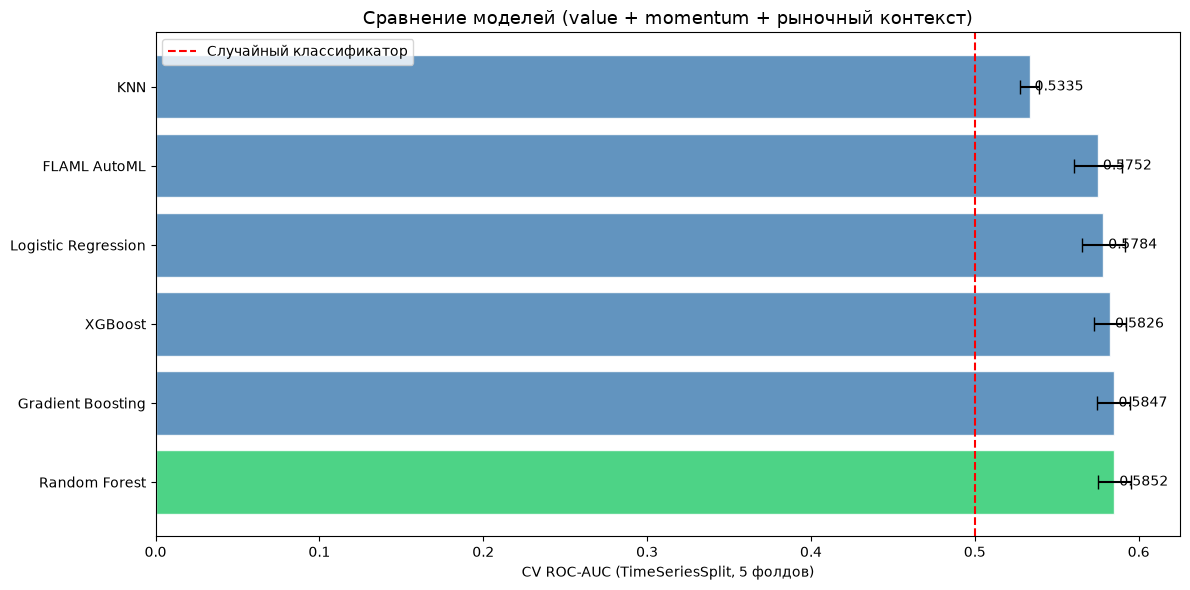

In [28]:
# Визуализация сравнения моделей
fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#2ecc71' if i == 0 else 'steelblue' for i in range(len(cv_results_df))]
bars = ax.barh(cv_results_df['Модель'], cv_results_df['CV ROC-AUC (mean)'],
               xerr=cv_results_df['CV ROC-AUC (std)'], color=colors,
               capsize=5, edgecolor='white', alpha=0.85)
ax.set_xlabel('CV ROC-AUC (TimeSeriesSplit, 5 фолдов)')
ax.set_title('Сравнение моделей (value + momentum + рыночный контекст)', fontsize=13)
ax.axvline(0.5, color='red', linestyle='--', linewidth=1.5, label='Случайный классификатор')
ax.legend()
for bar, val in zip(bars, cv_results_df['CV ROC-AUC (mean)']):
    ax.text(val + 0.003, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=10)
plt.tight_layout()
plt.show()


## 3.4 Дополнительные конфигурации и подбор гиперпараметров

Главный опыт использует одну базовую RF-конфигурацию во всех схемах и SHAP.
LR/RF/XGB с legacy-параметрами показаны дополнительно; они не называются
оптимальными на новой выборке. Новый RandomizedSearchCV запускается только
при явном флаге и использует purged CV внутри train, без выбора по тесту.
HistGB и KNN остаются фиксированными baseline: вычислительный бюджет
ограничен. Такое решение ограничивает выводы сравнением этих конфигураций.


In [29]:
# ── Подбор гиперпараметров: RandomizedSearchCV по трём моделям ──────────────
#
# Полный поиск - 3 модели x 10 кандидатов x 5 фолдов на обучающей выборке с
# 273 признаках - занимает часы. Найденные им параметры зафиксированы ниже,
# и по умолчанию модели просто строятся с этими параметрами.
# Чтобы перезапустить поиск, поставьте RUN_HYPERPARAM_SEARCH = True
# в ячейке протокола эксперимента.

best_name = cv_results_df.iloc[0]['Модель']
print(f'Лучшая модель по CV: {best_name}')

# Результат RandomizedSearchCV (random_state=42, n_iter=10, cv=TimeSeriesSplit(5))
BEST_PARAMS = {
    'LogReg': {'clf__C': 0.07887658410143283,
               'clf__penalty': 'l2',
               'clf__solver': 'liblinear'},
    'RandomForest': {'criterion': 'entropy', 'max_depth': 8,
                     'min_samples_leaf': 1, 'n_estimators': 413},
    'XGBoost': {'colsample_bytree': 0.6399899663272012,
                'gamma': 0.22962444598293358,
                'learning_rate': 0.07674172222780437,
                'max_depth': 5, 'min_child_weight': 6,
                'n_estimators': 408, 'subsample': 0.9879639408647978},
}
BEST_CV_SCORES = {'LogReg': np.nan, 'RandomForest': np.nan, 'XGBoost': np.nan}
print('Сохранённые параметры — legacy-конфигурации, НЕ новый результат поиска.')

if RUN_HYPERPARAM_SEARCH:
    lr_param_dist = {'clf__C': uniform(0.001, 100),
                     'clf__penalty': ['l1', 'l2'],
                     'clf__solver': ['liblinear']}
    lr_search = RandomizedSearchCV(
        Pipeline([('scaler', StandardScaler()),
                  ('clf', LogisticRegression(random_state=SEED, max_iter=1000))]),
        param_distributions=lr_param_dist, n_iter=10, scoring='roc_auc',
        cv=cv, random_state=SEED, n_jobs=1, verbose=1)
    lr_search.fit(X_train, y_train)

    rf_param_dist = {'n_estimators': randint(100, 500),
                     'max_depth': randint(4, 16),
                     'min_samples_leaf': randint(1, 20),
                     'criterion': ['gini', 'entropy']}
    rf_search = RandomizedSearchCV(
        RandomForestClassifier(random_state=SEED),
        param_distributions=rf_param_dist, n_iter=10, scoring='roc_auc',
        cv=cv, random_state=SEED, n_jobs=1, verbose=1)
    rf_search.fit(X_train, y_train)

    xgb_param_dist = {'n_estimators': randint(100, 500),
                      'max_depth': randint(3, 10),
                      'learning_rate': uniform(0.01, 0.2),
                      'subsample': uniform(0.6, 0.4),
                      'colsample_bytree': uniform(0.6, 0.4),
                      'min_child_weight': randint(1, 10),
                      'gamma': uniform(0, 0.5)}
    xgb_search = RandomizedSearchCV(
        XGBClassifier(eval_metric='logloss', device=XGB_DEVICE,
                      random_state=SEED, n_jobs=1),
        param_distributions=xgb_param_dist, n_iter=10, scoring='roc_auc',
        cv=cv, random_state=SEED, n_jobs=1, verbose=1)
    xgb_search.fit(X_train, y_train)

    BEST_PARAMS = {'LogReg': lr_search.best_params_,
                   'RandomForest': rf_search.best_params_,
                   'XGBoost': xgb_search.best_params_}
    BEST_CV_SCORES = {'LogReg': lr_search.best_score_,
                      'RandomForest': rf_search.best_score_,
                      'XGBoost': xgb_search.best_score_}
    print('\nПоиск перезапущен, параметры выше заменены найденными.')

# ── Сборка настроенных моделей ───────────────────────────────────────────────
tuned_estimators = {
    'LogReg (tuned)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(random_state=SEED, max_iter=1000)),
    ]).set_params(**BEST_PARAMS['LogReg']),
    'Random Forest (tuned)': RandomForestClassifier(
        random_state=SEED, n_jobs=-1, **BEST_PARAMS['RandomForest']),
    'XGBoost (tuned)': XGBClassifier(
        eval_metric='logloss', device=XGB_DEVICE, random_state=SEED,
        verbosity=0, **BEST_PARAMS['XGBoost']),
}

print('\nКонфигурации (новый поиск только при RUN_HYPERPARAM_SEARCH=True):')
for key, params in BEST_PARAMS.items():
    print(f'  {key:<13} CV ROC-AUC = {BEST_CV_SCORES[key]:.4f}')
    print(f'                {params}')

tuned_estimators['Random Forest (base)'] = dict(make_models())[BASE_MODEL]
print('\nОбучаем модели на train...')
for name, est in tuned_estimators.items():
    est.fit(X_train, y_train)
    print(f'  {name} - готово')

MODEL_DIR.mkdir(parents=True, exist_ok=True)
for name, est in tuned_estimators.items():
    fname = name.replace(' ', '_').replace('(', '').replace(')', '').lower()
    joblib.dump(est, MODEL_DIR / f'{fname}.pkl')
print(f'\nМодели сохранены в {MODEL_DIR}')


Лучшая модель по CV: Random Forest
Сохранённые параметры — legacy-конфигурации, НЕ новый результат поиска.

Конфигурации (новый поиск только при RUN_HYPERPARAM_SEARCH=True):
  LogReg        CV ROC-AUC = nan
                {'clf__C': 0.07887658410143283, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
  RandomForest  CV ROC-AUC = nan
                {'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 413}
  XGBoost       CV ROC-AUC = nan
                {'colsample_bytree': 0.6399899663272012, 'gamma': 0.22962444598293358, 'learning_rate': 0.07674172222780437, 'max_depth': 5, 'min_child_weight': 6, 'n_estimators': 408, 'subsample': 0.9879639408647978}

Обучаем модели на train...


c:\Users\dima\anaconda3\envs\bz\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


  LogReg (tuned) - готово
  Random Forest (tuned) - готово
  XGBoost (tuned) - готово
  Random Forest (base) - готово

Модели сохранены в c:\Users\dima\Desktop\Важные файлы с МГТУ им. Н.Э.Баумана и не только\ИУ6\3 курс\6 семестр\КУРСАЧИ\МЛ\MMOAI\models\versions\review_strict_2026_11_01


In [30]:
# Финальная оценка на тестовой выборке с расширенным набором метрик
final_results = {}
print(f"{'Модель':<30} {'ROC-AUC':>9} {'Avg Prec':>9} {'F1':>7} "
      f"{'Precision':>10} {'Recall':>8}")
print('-' * 78)

for name, model in tuned_estimators.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)
    r = {
        'model': model, 'y_prob': y_prob, 'y_pred': y_pred,
        'roc_auc': roc_auc_score(y_test, y_prob),
        'avg_prec': average_precision_score(y_test, y_prob),
        'f1': f1_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred, zero_division=0),
    }
    final_results[name] = r
    print(f'{name:<30} {r["roc_auc"]:>9.4f} {r["avg_prec"]:>9.4f} '
          f'{r["f1"]:>7.4f} {r["precision"]:>10.4f} {r["recall"]:>8.4f}')

# Primary RF fixed a priori; never select on holdout AP.
best_final_name = 'Random Forest (base)'
best = final_results[best_final_name]
print(f'\nОсновная конфигурация, выбранная заранее: {best_final_name}')

# ── Предсказания expanding-схемы в едином формате ────────────────────────────
# Пригодятся и для бэктеста, и для проверки значимости, и для повторного
# запуска ноутбука без переобучения.
expanding_preds = test_df[['Date', 'Symbol']].copy()
expanding_preds['y_true'] = y_test.values
for name, r in final_results.items():
    expanding_preds[name] = r['y_prob']
expanding_preds['y_prob'] = best['y_prob']

if SAVE_PREDICTIONS:
    rp.save_predictions(expanding_preds,PRED_DIR/'expanding_preds')
    print(f'Статические прогнозы сохранены: '
          f'{PRED_DIR / "expanding_preds.csv.gz"}')

# ── Precision@K ──────────────────────────────────────────────────────────────
# Считаем только подневно. Прежний вариант брал топ-50 строк по всему пулу
# теста сразу: эти 50 наблюдений приходят с двух-трёх дат, торговой
# интерпретации у такого числа нет.
K = TOP_K
baseline_rate = y_test.mean()

daily_precision_at_k = (expanding_preds
                        .groupby('Date', group_keys=False)
                        .apply(lambda x: x.nlargest(min(K, len(x)), 'y_prob')['y_true'].mean())
                        .mean())

daily_recalls = []
for date, day in expanding_preds.groupby('Date'):
    if day['y_true'].sum() == 0:
        continue
    top = day.nlargest(min(K, len(day)), 'y_prob')
    daily_recalls.append(top['y_true'].sum() / day['y_true'].sum())

print(f'\nСредний дневной Precision@{K}: {daily_precision_at_k:.3f}')
print(f'Средний дневной Recall@{K}:    {np.mean(daily_recalls):.3f}')
print(f'Базовая доля класса 1 в тесте: {baseline_rate:.3f}')
print(f'Lift: {daily_precision_at_k / baseline_rate:.2f}x')

# ── Сводная таблица: CV vs Тест ──────────────────────────────────────────────
# Раньше здесь был KeyError: в cv_results_df колонка называется
# 'CV ROC-AUC (mean)', а код искал 'ROC-AUC', поэтому таблица не выводилась.
print('\n' + '=' * 70)
print('СВОДНОЕ СРАВНЕНИЕ: CV ROC-AUC vs Тест ROC-AUC')
print('=' * 70)

cv_lookup = cv_results_df.set_index('Модель')['CV ROC-AUC (mean)'].to_dict()
tuned_to_base = {'LogReg (tuned)': 'Logistic Regression',
                 'Random Forest (tuned)': 'Random Forest',
                 'XGBoost (tuned)': 'XGBoost', 'Random Forest (base)': BASE_MODEL}

print(f"{'Модель':<30} {'CV ROC-AUC':>12} {'Тест ROC-AUC':>14} {'Gap':>8}")
print('-' * 68)
for name, res in final_results.items():
    cv_val = cv_lookup.get(BASE_MODEL,float('nan')) if name=='Random Forest (base)' else float('nan')
    gap = res['roc_auc'] - cv_val
    flag = ''
    print(f'{name:<30} {cv_val:>12.4f} {res["roc_auc"]:>14.4f} {gap:>+8.4f}{flag}')

print('\nCV/test gap показан только для одинаковой базовой RF-конфигурации; это описание, не тест drift.')


Модель                           ROC-AUC  Avg Prec      F1  Precision   Recall
------------------------------------------------------------------------------
LogReg (tuned)                    0.5753    0.5595  0.4877     0.5582   0.4330
Random Forest (tuned)             0.5781    0.5603  0.5312     0.5493   0.5142
XGBoost (tuned)                   0.5758    0.5574  0.5436     0.5427   0.5446
Random Forest (base)              0.5780    0.5602  0.5299     0.5491   0.5119

Основная конфигурация, выбранная заранее: Random Forest (base)
Статические прогнозы сохранены: c:\Users\dima\Desktop\Важные файлы с МГТУ им. Н.Э.Баумана и не только\ИУ6\3 курс\6 семестр\КУРСАЧИ\МЛ\MMOAI\data\derived\review_strict_2026_11_01\predictions\expanding_preds.csv.gz

Средний дневной Precision@10: 0.661
Средний дневной Recall@10:    0.029
Базовая доля класса 1 в тесте: 0.488
Lift: 1.35x

СВОДНОЕ СРАВНЕНИЕ: CV ROC-AUC vs Тест ROC-AUC
Модель                           CV ROC-AUC   Тест ROC-AUC      Gap
------------

Recall и Precision отвечают на разные вопросы; при ограничении k
оцениваем Precision@10 по дням и P&L с учётом риска и издержек.
Модель для основного экономического опыта фиксирована до просмотра теста.


In [31]:
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve
tr_pos,val_pos = cv[-1]
threshold_est = clone(best['model']).fit(X_train.iloc[tr_pos],y_train.iloc[tr_pos])
val_prob = threshold_est.predict_proba(X_train.iloc[val_pos])[:,1]
prec_arr,rec_arr,thresholds = precision_recall_curve(y_train.iloc[val_pos],val_prob)
f1_arr = 2*prec_arr[:-1]*rec_arr[:-1]/np.maximum(prec_arr[:-1]+rec_arr[:-1],1e-12)
best_thr = thresholds[np.argmax(f1_arr)]
y_pred_opt = (best['y_prob'] >= best_thr).astype(int)
print('Порог выбран на последнем purged train-фолде:',best_thr)
print(classification_report(y_test,y_pred_opt,zero_division=0))
print('Top-K стратегия от порога не зависит.')


Порог выбран на последнем purged train-фолде: 0.3486728114455931
              precision    recall  f1-score   support

           0       0.65      0.01      0.02    156247
           1       0.49      0.99      0.66    149107

    accuracy                           0.49    305354
   macro avg       0.57      0.50      0.34    305354
weighted avg       0.57      0.49      0.33    305354

Top-K стратегия от порога не зависит.


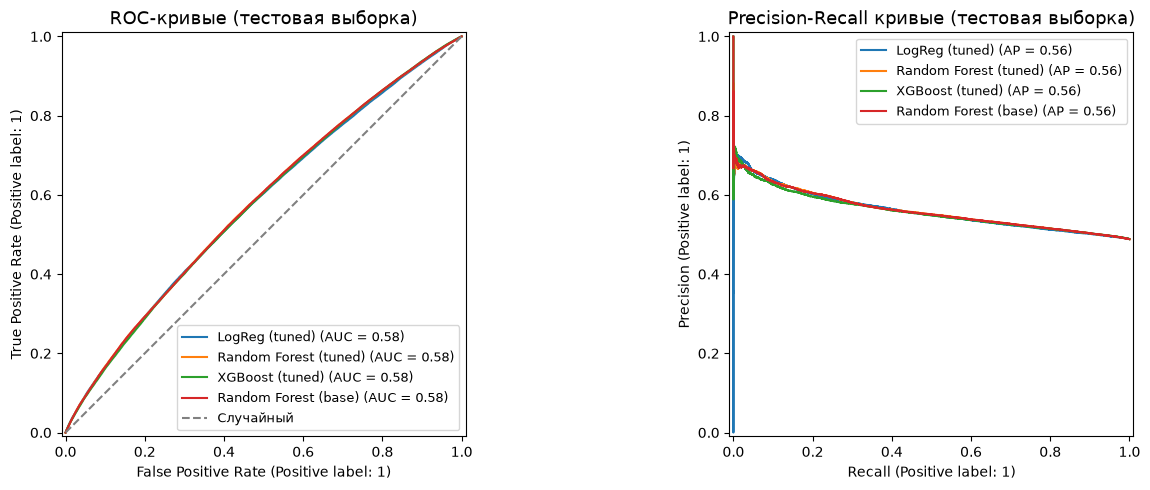

In [32]:
# ── FIX 8: PR-кривая через predict_proba (не predict) ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC-кривые обеих моделей
for name, res in final_results.items():
    RocCurveDisplay.from_predictions(y_test, res['y_prob'], name=name, ax=axes[0])
axes[0].plot([0,1],[0,1], linestyle='--', color='grey', label='Случайный')
axes[0].set_title('ROC-кривые (тестовая выборка)', fontsize=13)
axes[0].legend(fontsize=9)

# PR-кривые обеих моделей
for name, res in final_results.items():
    PrecisionRecallDisplay.from_predictions(y_test, res['y_prob'], name=name, ax=axes[1])
axes[1].set_title('Precision-Recall кривые (тестовая выборка)', fontsize=13)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


In [33]:
# Classification Report лучшей модели
print(f'Classification Report - {best_final_name}')
print(classification_report(y_test, best['y_pred'],
                             target_names=['Класс 0 (рост ≤2%)', 'Класс 1 (рост >2%)']))


Classification Report - Random Forest (base)
                    precision    recall  f1-score   support

Класс 0 (рост ≤2%)       0.56      0.60      0.58    156247
Класс 1 (рост >2%)       0.55      0.51      0.53    149107

          accuracy                           0.56    305354
         macro avg       0.56      0.56      0.55    305354
      weighted avg       0.56      0.56      0.56    305354



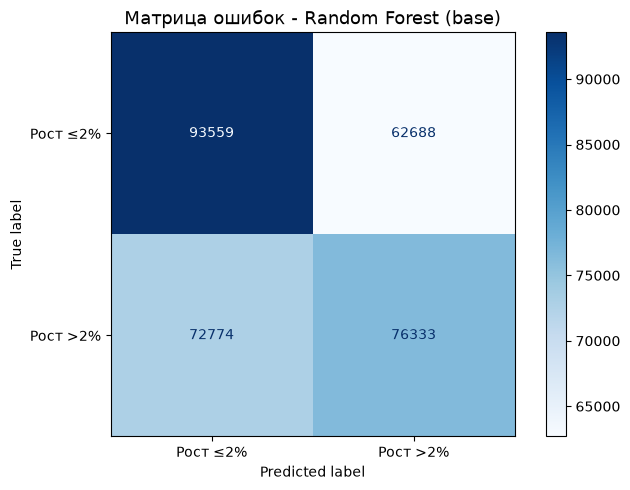

In [34]:
# Матрица ошибок лучшей модели
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, best['y_pred'],
    display_labels=['Рост ≤2%', 'Рост >2%'],
    cmap='Blues', ax=ax
)
ax.set_title(f'Матрица ошибок - {best_final_name}', fontsize=13)
plt.tight_layout()
plt.show()


False positive означает ошибку в событии опережения индекса, а не
обязательно денежный убыток. False negative также не определяет P&L.
Экономический результат рассчитывается по ценам исполнения отдельно.


In [35]:
# Дневное ранжирование для диагностики; не глобальный top по всему тесту.
sector_map=dict(zip(companies.Symbol,companies.Sector))
all_preds=expanding_preds[['Symbol','Date','y_true','y_prob']].rename(
    columns={'y_true':'Target','y_prob':'Prob'}).copy()
all_preds=all_preds.merge(df_sorted[['Date','Symbol','X_10']],on=['Date','Symbol'],validate='one_to_one')
all_preds['Sector']=all_preds.Symbol.map(sector_map)
unique_preds=pd.concat([day.nlargest(TOP_K,'Prob') for _,day in all_preds.groupby('Date')],ignore_index=True)
print('Только дневные top-K; диагностика секторов, без торговой фильтрации по Target.')


Только дневные top-K; диагностика секторов, без торговой фильтрации по Target.


In [36]:
sector_counts=unique_preds.Sector.value_counts()
sector_accuracy=unique_preds.groupby('Sector').Target.mean()
display(pd.DataFrame({'signals':sector_counts,'class1_rate':sector_accuracy}))


,signals,class1_rate
Sector,,
Basic Materials,459,0.651416
Communication Services,666,0.605105
Consumer Cyclical,745,0.702013
Consumer Defensive,285,0.543860
Energy,424,0.650943
Financial Services,428,0.672897
Healthcare,826,0.592010
Industrials,196,0.561224
Real Estate,34,0.676471


In [37]:
# Выбор секторов по реализованному Target теста создавал бы подгонку.
print('Секторальная статистика выше — диагностика; торговый фильтр по ней не строится.')


Секторальная статистика выше — диагностика; торговый фильтр по ней не строится.


In [38]:
target_date=all_preds.Date.max()
day_preds=all_preds[all_preds.Date.eq(target_date)]
display(day_preds.nlargest(TOP_K,'Prob')[['Symbol','Sector','Prob','Target','X_10']])


,Symbol,Sector,Prob,Target,X_10
305174,MRNA,Healthcare,0.848343,1,-11.777400
305020,ENPH,Technology,0.823102,1,-0.474815
305213,PARA,Communication Services,0.808047,0,-24.563005
305264,SMCI,Technology,0.766727,1,35.632757
304998,DLTR,Consumer Defensive,0.751556,1,8.562710
305172,MPWR,Technology,0.742972,1,-23.271135
305327,VST,Utilities,0.742487,0,14.545526
305228,PLTR,Technology,0.723972,1,10.644221
304876,AES,Utilities,0.720805,1,-3.680655
305295,TPL,Energy,0.717067,0,26.341257


Гипотезы об отскоке и momentum проверяются на текущем SHAP-графике.
Важность признака не определяет знак эффекта и не является торговой рекомендацией.


In [60]:
TRADING_DAYS_PER_YEAR=252
def run_backtest(*args,**kwargs):
    kwargs.setdefault('top_k',TOP_K)
    kwargs.setdefault('capital',INITIAL_CAPITAL)
    kwargs.setdefault('commission',COMMISSION)
    result=rr.run_backtest(*args,**kwargs)
    result['metrics'].update(rr.factor_risk_metrics(result['equity'],index_prices,factors,lag=BOOT_BLOCK_DAYS))
    rp.validate_backtest(result,kwargs['start'],kwargs['end'])
    return result

def print_backtest(result):
    m=result['metrics']
    print(result['label'],m['start'].date(),m['end'].date())
    print('CAPM alpha/year:',f"{m['jensen_alpha']:+.2%}",'HAC p:',round(m['jensen_p'],4))
    print('FF5+Mom alpha/year:',f"{m['ff_alpha']:+.2%}",'HAC p:',round(m['ff_p'],4))
    print('Beta:',round(m['beta'],3),'IR:',round(m['information_ratio'],3))
    print('Total return:',f"{m['total_return']:+.2%}",
          'Raw gap vs index:',f"{m['alpha_vs_index']:+.2%}")
    print('Sharpe excess:',round(m['sharpe'],3),'MDD:',f"{m['max_drawdown']:.2%}",
          'Profit factor:',round(m['profit_factor'],3),'turnover(two-sided):',round(m['avg_turnover'],3))

def evaluate_strategy(result):
    print('Статистические выводы — только по тестам раздела 3.7; пороги не доказывают готовности к торговле.')

def plot_backtest(result, color=None):
    eq = result['equity']
    m = result['metrics']
    label = result['label']
    if color is None:
        scheme = label.lower()
        color = ('#9b59b6' if 'long/short' in scheme else
                 '#2ecc71' if 'expanding' in scheme else
                 '#3498db' if 'sliding' in scheme else '#34495e')
    market = index_prices.set_index('Date').SP500.reindex(eq.index)
    fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
    axes[0].plot(eq.index, eq.Capital, color=color, linewidth=2,
                 label=label, zorder=3)
    axes[0].plot(eq.index, market / market.iloc[0] * result['params']['capital'],
                 color='#e67e22', linestyle='--', linewidth=1.8,
                 label='S&P 500 (price)')
    axes[0].legend(); axes[0].set_ylabel('Capital')
    axes[0].set_title(label)
    axes[1].plot(eq.index, result['drawdown'], color='#c0392b', linewidth=1)
    axes[1].fill_between(eq.index, result['drawdown'], 0,
                         color='#e74c3c', alpha=.35)
    axes[1].axhline(0, color='#555555', linewidth=.7)
    axes[1].set_ylabel('Drawdown'); axes[1].set_title(f"MDD {m['max_drawdown']:.2%}")
    for ax in axes:
        ax.grid(alpha=.25)
    plt.tight_layout()
    return fig


Static RF 2022-06-02 2024-11-22
CAPM alpha/year: -2.81% HAC p: 0.8522
FF5+Mom alpha/year: +2.98% HAC p: 0.8295
Beta: 1.416 IR: 0.074
Total return: +34.13% Raw gap vs index: -8.79%
Sharpe excess: 0.389 MDD: -31.13% Profit factor: 1.096 turnover(two-sided): 2.006


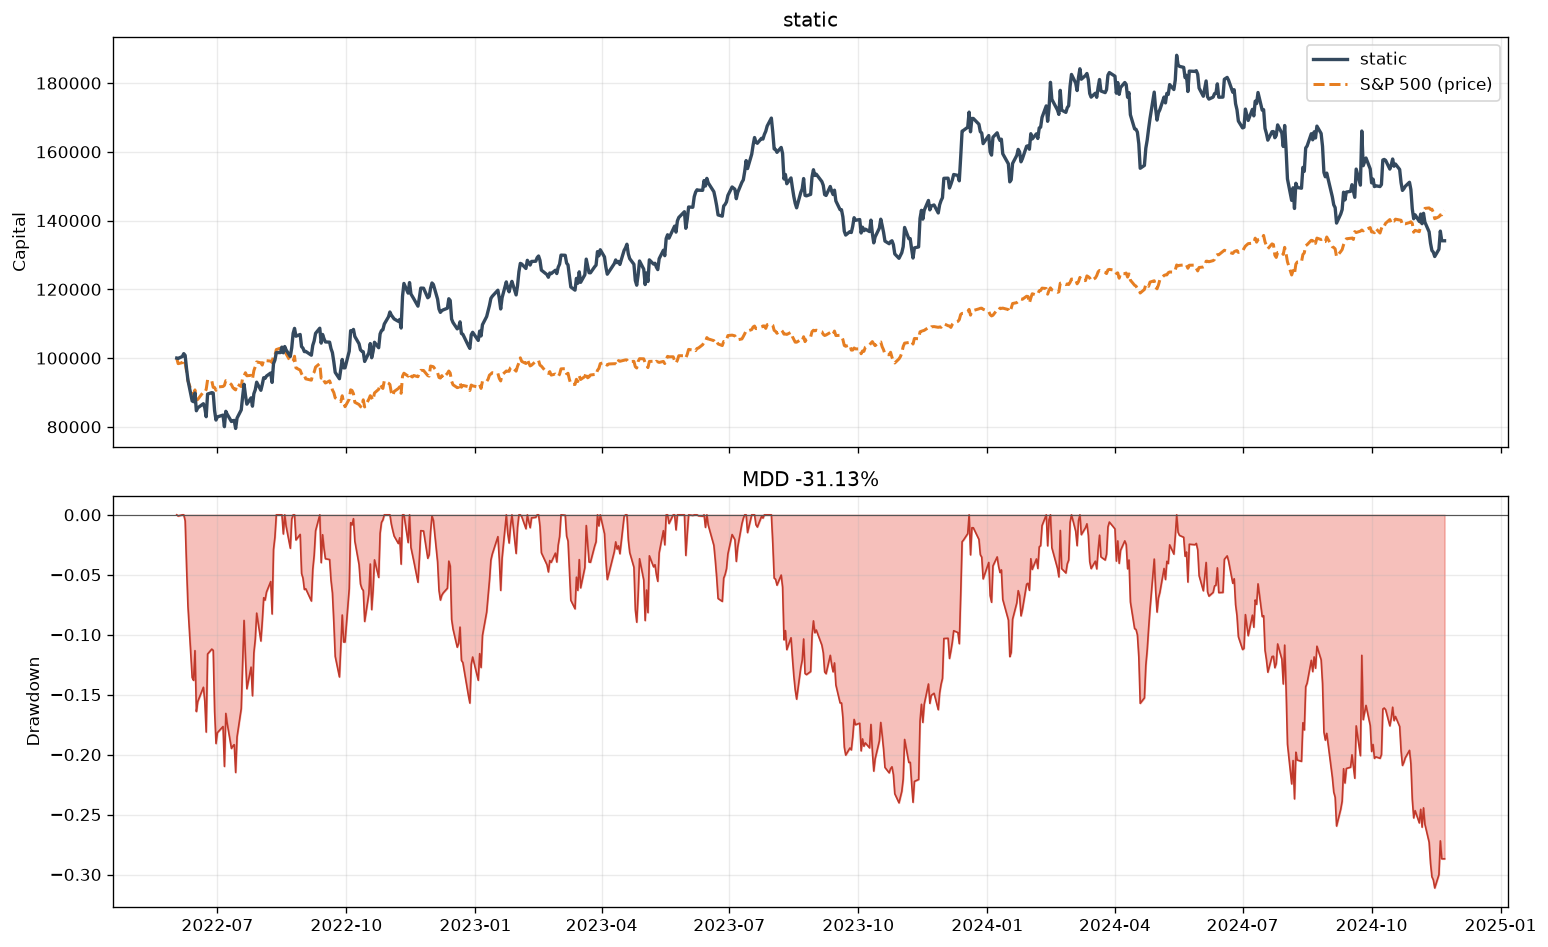

In [61]:
# Основной статический RF: та же конфигурация, что и walk-forward ниже
panel = full_price_panel.copy()
index_prices = index_df[['Date','SP500']].copy()
trade_test = df_prediction[df_prediction.Date.between(OOS_START,OOS_END)]
bt_preds = trade_test[['Date','Symbol','Target']].rename(columns={'Target':'y_true'}).copy()
bt_preds['y_prob'] = best['model'].predict_proba(trade_test[ALL_FEAT_COLS])[:,1]
res_expanding_full = run_backtest(bt_preds,panel,index_prices,horizon=HOLD_DAYS,
                                start=OOS_START,end=OOS_END,label='Static RF')
print_backtest(res_expanding_full)
plot_backtest(res_expanding_full)
plt.show()


Оценка стратегии включает риск-корректированную альфу, excess-return
Sharpe, ежедневную просадку и Profit Factor по реализованным денежным P&L.
Заранее установленные «хорошие» пороги не заменяют статистическую проверку.
CAPM использует дневной RF; факторная модель служит проверкой экспозиций.


Static RF long/short 2022-06-02 2024-11-22
CAPM alpha/year: -10.10% HAC p: 0.1993
FF5+Mom alpha/year: -6.96% HAC p: 0.3491
Beta: 0.281 IR: -1.008
Total return: -8.49% Raw gap vs index: -51.41%
Sharpe excess: -0.472 MDD: -25.50% Profit factor: 0.959 turnover(two-sided): 2.006


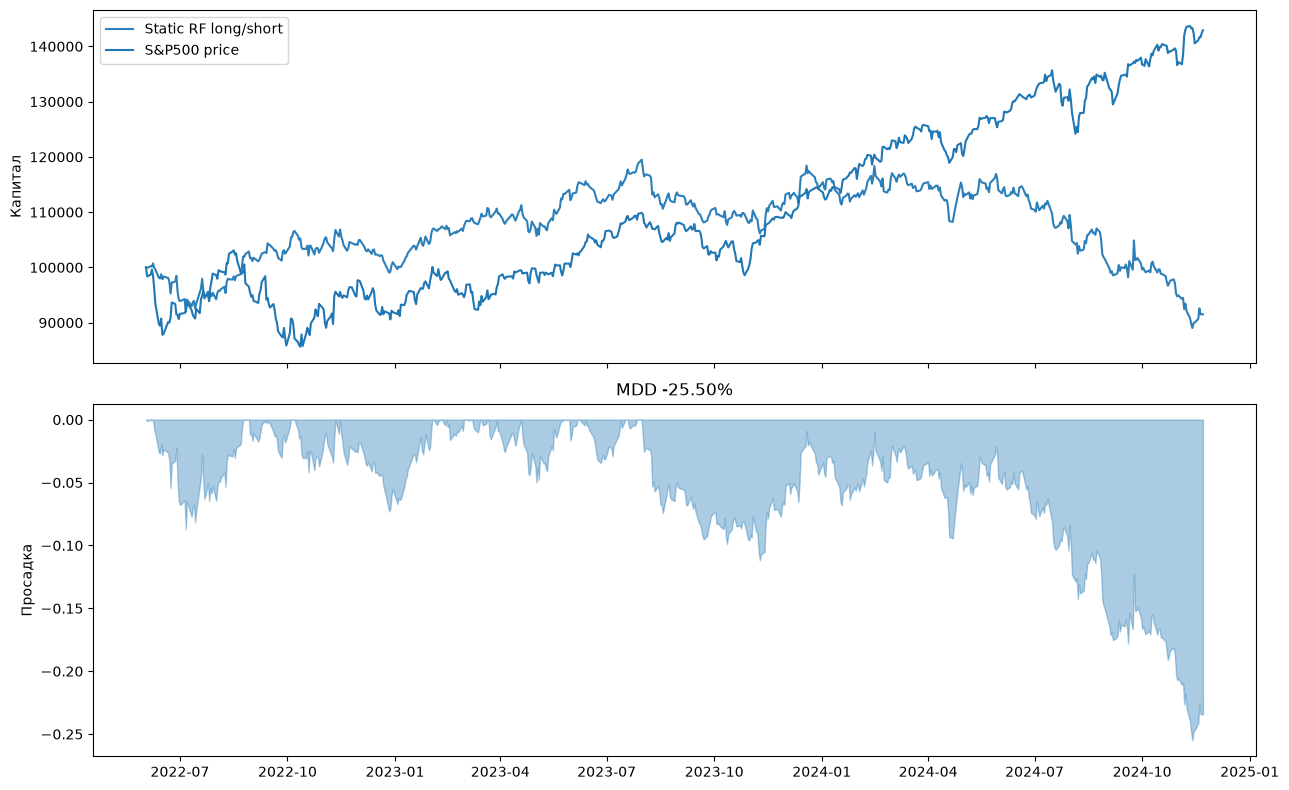

In [59]:
# Long/short — дополнительная диагностика, не главный результат статьи.
res_long_short=run_backtest(bt_preds,panel,index_prices,horizon=HOLD_DAYS,
    start=OOS_START,end=OOS_END,long_short=True,label='Static RF long/short')
print_backtest(res_long_short)
plot_backtest(res_long_short); plt.show()


Результаты выше относятся к static RF и дополнительному long/short примеру.
Основное сравнение форм окна и показателей риска приведено в разделе 3.7.
Пороговые таблицы не являются доказательством готовности стратегии к торговле.


Попробуем сделать ансмабль лучших моделей

In [42]:
from sklearn.ensemble import VotingClassifier

voting_clf = VotingClassifier(
    estimators=[
        ('lr',  tuned_estimators['LogReg (tuned)']),
        ('rf',  tuned_estimators['Random Forest (tuned)']),
        ('xgb', tuned_estimators['XGBoost (tuned)']),
    ],
    voting='soft',
    n_jobs=-1
)
voting_clf.fit(X_train, y_train)

y_prob_ens = voting_clf.predict_proba(X_test)[:, 1]
y_pred_ens = voting_clf.predict(X_test)

print(f"Ансамбль (Voting) на тесте:")
print(f"  ROC-AUC:  {roc_auc_score(y_test, y_prob_ens):.4f}")
print(f"  Avg Prec: {average_precision_score(y_test, y_prob_ens):.4f}")
print(f"  F1:       {f1_score(y_test, y_pred_ens):.4f}")
print(f"  Precision:{precision_score(y_test, y_pred_ens, zero_division=0):.4f}")
print(f"  Recall:   {recall_score(y_test, y_pred_ens):.4f}")
print()
print(classification_report(y_test, y_pred_ens,
      target_names=['Класс 0 (рост ≤2%)', 'Класс 1 (рост >2%)']))


Ансамбль (Voting) на тесте:
  ROC-AUC:  0.5816
  Avg Prec: 0.5634
  F1:       0.5253
  Precision:0.5541
  Recall:   0.4994

                    precision    recall  f1-score   support

Класс 0 (рост ≤2%)       0.56      0.62      0.59    156247
Класс 1 (рост >2%)       0.55      0.50      0.53    149107

          accuracy                           0.56    305354
         macro avg       0.56      0.56      0.56    305354
      weighted avg       0.56      0.56      0.56    305354



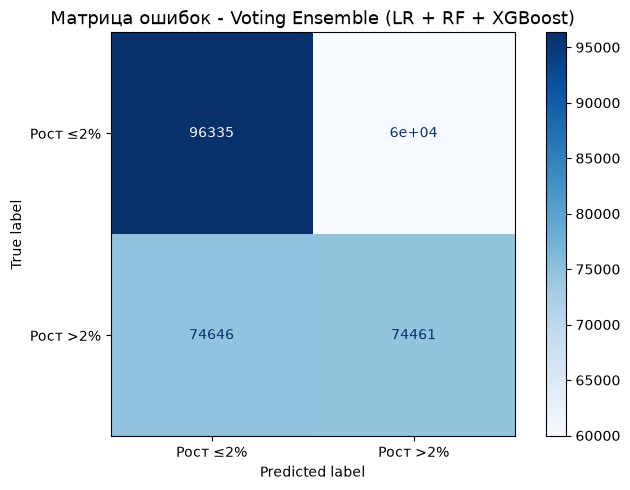

In [43]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, (y_prob_ens > 0.5).astype(int),
    display_labels=['Рост ≤2%', 'Рост >2%'],
    cmap='Blues', ax=ax
)
ax.set_title('Матрица ошибок - Voting Ensemble (LR + RF + XGBoost)', fontsize=13)
plt.tight_layout()
plt.show()


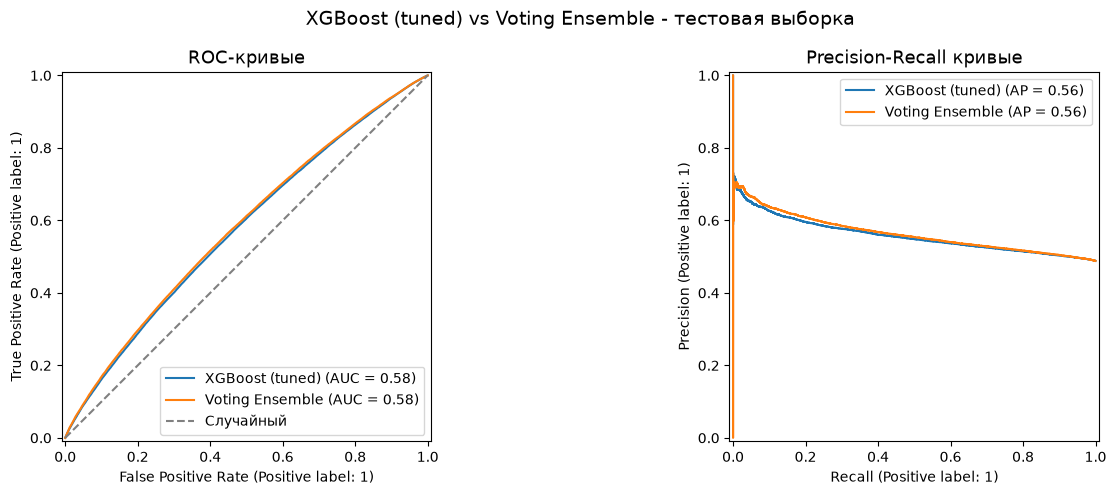

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Вероятности XGBoost tuned - уже посчитаны при финальной оценке
y_prob_xgb = final_results['XGBoost (tuned)']['y_prob']

# ROC-кривые
RocCurveDisplay.from_predictions(y_test, y_prob_xgb,   name='XGBoost (tuned)', ax=axes[0])
RocCurveDisplay.from_predictions(y_test, y_prob_ens,   name='Voting Ensemble', ax=axes[0])
axes[0].plot([0,1],[0,1], linestyle='--', color='grey', label='Случайный')
axes[0].set_title('ROC-кривые', fontsize=13)
axes[0].legend(fontsize=10)

# PR-кривые
PrecisionRecallDisplay.from_predictions(y_test, y_prob_xgb, name='XGBoost (tuned)', ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, y_prob_ens, name='Voting Ensemble', ax=axes[1])
axes[1].set_title('Precision-Recall кривые', fontsize=13)
axes[1].legend(fontsize=10)

plt.suptitle('XGBoost (tuned) vs Voting Ensemble - тестовая выборка', fontsize=14)
plt.tight_layout()
plt.show()


## 3.5 Скользящее окно (Sliding Window)

Train: последние 253 торговые даты. Purge: 10 дней. Test/step: 21 день.
Все OOS-прогнозы начинаются 2022-06-02; последний фолд может быть короче
21 дня, чтобы в точности завершиться 2024-11-22. Нет разных «общих» окон.


In [45]:
df_sorted_sw = df_prediction.copy()
models_sw = dict(make_models())
sw_preds,sw_fold_df = rr.walk_predict(df_sorted_sw,ALL_FEAT_COLS,models_sw,
    OOS_START,OOS_END,window=TRAIN_DAYS,gap=GAP_DAYS,step=STEP_DAYS,
    cache_dir=PRED_DIR/'sliding_models')
sw_fold_scores = {n:sw_fold_df.loc[sw_fold_df['Модель']==n,'ROC-AUC'].tolist() for n in models_sw}
SW_N_TRAIN,SW_N_TEST = int(sw_fold_df.n_train.mean()),int(sw_fold_df.n_test.mean())
sw_results_df = pd.DataFrame([{'Модель':n,'ROC-AUC (mean)':np.nanmean(sw_fold_scores[n]),
    'ROC-AUC (std)':np.nanstd(sw_fold_scores[n]),'ROC-AUC (пул)':roc_auc_score(sw_preds.loc[sw_preds.y_true.notna(),'y_true'],sw_preds.loc[sw_preds.y_true.notna(),n])}
    for n in models_sw]).sort_values('ROC-AUC (mean)',ascending=False)
rp.save_predictions(sw_preds,PRED_DIR/'sliding_preds')
sw_fold_df.to_csv(PRED_DIR/'sliding_fold_scores.csv',index=False)
display(sw_results_df)


fold 1/30 train=123,012 test=10,248
fold 2/30 train=123,075 test=10,248
fold 3/30 train=123,138 test=10,248
fold 4/30 train=123,201 test=10,248
fold 5/30 train=123,264 test=10,248
fold 6/30 train=123,325 test=10,248
fold 7/30 train=123,367 test=10,248
fold 8/30 train=123,409 test=10,248
fold 9/30 train=123,436 test=10,269
fold 10/30 train=123,468 test=10,269
fold 11/30 train=123,496 test=10,269
fold 12/30 train=123,517 test=10,269
fold 13/30 train=123,538 test=10,269
fold 14/30 train=123,559 test=10,269
fold 15/30 train=123,580 test=10,269
fold 16/30 train=123,601 test=10,269
fold 17/30 train=123,622 test=10,269
fold 18/30 train=123,643 test=10,269
fold 19/30 train=123,664 test=10,271
fold 20/30 train=123,685 test=10,290
fold 21/30 train=123,719 test=10,290
fold 22/30 train=123,751 test=10,290
fold 23/30 train=123,772 test=10,290
fold 24/30 train=123,793 test=10,302
fold 25/30 train=123,816 test=10,311
fold 26/30 train=123,858 test=10,311
fold 27/30 train=123,900 test=10,311
fold 28/30

,Модель,ROC-AUC (mean),ROC-AUC (std),ROC-AUC (пул)
1,Random Forest,0.560661,0.044298,0.560095
3,Gradient Boosting,0.552370,0.045524,0.554375
2,XGBoost,0.549962,0.042753,0.552128
0,Logistic Regression,0.543429,0.045494,0.547493
4,KNN,0.520698,0.019608,0.523098


In [46]:
# Оценочные прогнозы и календарь сохранены выше.
# Последняя модель фолда не выдаётся за модель на всей истории.
print(PRED_DIR/'sliding_fold_scores.csv')


c:\Users\dima\Desktop\Важные файлы с МГТУ им. Н.Э.Баумана и не только\ИУ6\3 курс\6 семестр\КУРСАЧИ\МЛ\MMOAI\data\derived\review_strict_2026_11_01\predictions\sliding_fold_scores.csv


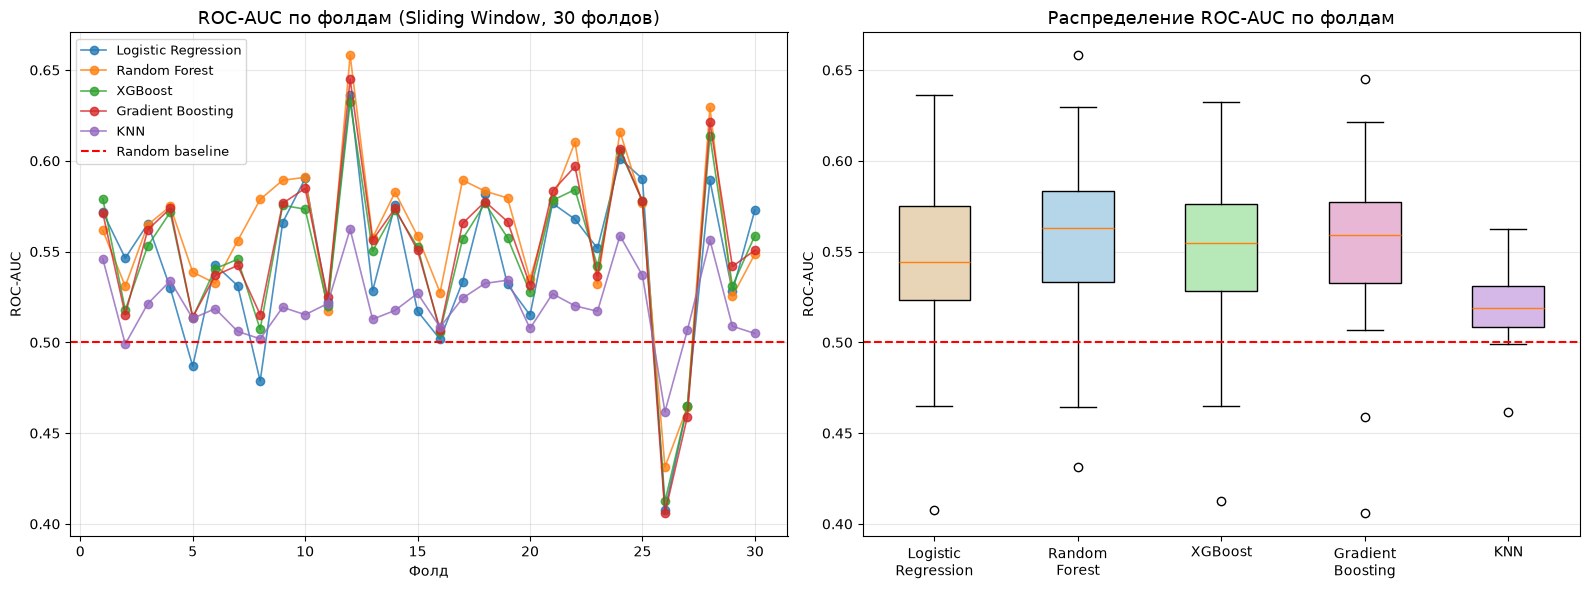

In [47]:
# ── Динамика ROC-AUC по фолдам ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

n_folds_plot = len(sw_fold_scores[next(iter(models_sw))])
marker = 'o' if n_folds_plot <= 30 else None   # при большом числе фолдов маркеры сливаются

for name in models_sw:
    axes[0].plot(range(1, len(sw_fold_scores[name]) + 1),
                 sw_fold_scores[name],
                 marker=marker, label=name, alpha=0.8, linewidth=1.2)

axes[0].axhline(0.5, color='red', linestyle='--',
                linewidth=1.5, label='Random baseline')
axes[0].set_title(f'ROC-AUC по фолдам (Sliding Window, {n_folds_plot} фолдов)',
                  fontsize=13)
axes[0].set_xlabel('Фолд')
axes[0].set_ylabel('ROC-AUC')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

# Boxplot
data_box   = [sw_fold_scores[n] for n in models_sw]
labels_box = [n.replace(' ', '\n') for n in models_sw]
bp = axes[1].boxplot(data_box, tick_labels=labels_box, patch_artist=True)
colors_bp  = ['#e8d5b7', '#b5d5e8', '#b7e8b7', '#e8b7d5', '#d5b7e8']
for patch, c in zip(bp['boxes'], colors_bp):
    patch.set_facecolor(c)
axes[1].axhline(0.5, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Распределение ROC-AUC по фолдам', fontsize=13)
axes[1].set_ylabel('ROC-AUC')
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(FIG_DIR / 'sliding_window_folds.png', dpi=120, bbox_inches='tight')
plt.show()


Пофолдовые графики описывают текущий прогон. Соседние фолды зависимы;
выбор победителя по визуальному расстоянию кривых не обоснован.
Формальная проверка приведена ниже.


In [48]:
# ══════════════════════════════════════════════════════════════════════════════
# Precision@K для скользящего окна
#
# Метрика считается ТОЛЬКО подневно. Прежний вариант брал топ-50 строк по
# всему пулу предсказаний сразу; такие 50 наблюдений приходят с двух-трёх
# дат, и торгового смысла у полученного числа нет.
# ══════════════════════════════════════════════════════════════════════════════

sector_map = dict(zip(companies['Symbol'], companies['Sector']))

sw_view = sw_preds[['Date', 'Symbol', 'y_true', 'fold']].copy()
sw_view['y_prob'] = sw_preds[BASE_MODEL]
sw_view['Sector'] = sw_view['Symbol'].map(sector_map)
sw_view = sw_view.merge(df_sorted_sw[['Date', 'Symbol', 'X_10']],
                        on=['Date', 'Symbol'], how='left')

baseline_sw = sw_view['y_true'].mean()
print(f'Уникальных тикеров: {sw_view["Symbol"].nunique()} | '
      f'наблюдений: {len(sw_view):,}')
print(f'Базовая доля класса 1: {baseline_sw:.3f}')

# ── Precision@K по дням ──────────────────────────────────────────────────────
print(f'\n{"K":>5}  {"Precision@K":>12}  {"Lift":>7}  {"Дней":>6}')
print('-' * 36)
prec_rows = []
for k in [1, 3, 5, 10, 20, 50]:
    per_day = (sw_view.groupby('Date', group_keys=False)
               .apply(lambda x: x.nlargest(min(k, len(x)), 'y_prob')['y_true'].mean()))
    prec_rows.append({'K': k, 'Precision@K': per_day.mean(),
                      'Lift': per_day.mean() / baseline_sw,
                      'Дней': len(per_day)})
    print(f'{k:>5}  {per_day.mean():>12.3f}  '
          f'{per_day.mean() / baseline_sw:>6.2f}x  {len(per_day):>6}')

precision_sw_df = pd.DataFrame(prec_rows)

# ── Распределение по секторам ────────────────────────────────────────────────
top10_daily = (sw_view.groupby('Date', group_keys=False)
               .apply(lambda x: x.nlargest(min(10, len(x)), 'y_prob')))

sector_stats = (top10_daily.groupby('Sector')
                .agg(Сигналов=('y_true', 'size'),
                     Точность=('y_true', 'mean'))
                .sort_values('Сигналов', ascending=False))
sector_stats['Lift'] = sector_stats['Точность'] / baseline_sw

print(f'\nСектора в дневных топ-10 (всего {len(top10_daily):,} сигналов):')
print(sector_stats.round(3).to_string())
print('\nСектора с малым числом сигналов интерпретировать нельзя - '
      'точность там\nсчитается по единицам наблюдений.')

# ── Сигналы за последнюю дату ────────────────────────────────────────────────
last_date = sw_view['Date'].max()
day = sw_view[sw_view['Date'] == last_date].nlargest(10, 'y_prob')

print(f'\n--- Сигналы за {last_date.date()} ---')
print(day[['Symbol', 'Sector', 'y_prob', 'y_true', 'X_10']]
      .to_string(index=False))
print(f'Precision@10 за этот день: {day["y_true"].mean():.3f} '
      f'(одна дата, не оценка стратегии)')


Уникальных тикеров: 492 | наблюдений: 305,354
Базовая доля класса 1: 0.488

    K   Precision@K     Lift    Дней
------------------------------------
    1         0.639    1.31x     624
    3         0.656    1.34x     624
    5         0.656    1.34x     624
   10         0.653    1.34x     624
   20         0.629    1.29x     624
   50         0.600    1.23x     624

Сектора в дневных топ-10 (всего 6,240 сигналов):
                        Сигналов  Точность   Lift
Sector                                           
Technology                  1782     0.695  1.424
Healthcare                   794     0.610  1.248
Consumer Cyclical            639     0.707  1.449
Energy                       596     0.614  1.258
Communication Services       499     0.635  1.301
Basic Materials              496     0.617  1.263
Financial Services           464     0.685  1.404
Consumer Defensive           377     0.525  1.076
Utilities                    280     0.714  1.463
Industrials                 

## 3.6 Статистические различия между алгоритмами

Использую общие circular moving-block выборки дат (основной блок 21 день,
не менее 2 000 повторов). Переношу весь день со всеми акциями и предсказаниями.
Оценка — pooled ROC-AUC; пофолдовое среднее — отдельная величина.

CI и p получены инверсией одного basic equal-tail теста центрированной
bootstrap-ошибки, с plus-one и проверкой конечновыборочной согласованности.
Публикуются номинальные 95% интервалы и отдельно Holm-adjusted p; номинальный
интервал не является одновременным интервалом после поправки.

Для 10 пар пяти заданных моделей применяется Holm. Значимость заявляется
по согласованному правилу bootstrap + приближённый NB-тест по фолдам.
Уилкоксон — чувствительность; DeLong — только iid-диагностика, не точный
тест для зависимой панели и не гарантированная нижняя граница ошибки.
Отдельная проверка AUC против .5 имеет своё семейство из пяти гипотез.


In [49]:
def _midrank(x):
    """Ранги с усреднением связок (midranks)."""
    order = np.argsort(x)
    sorted_x = x[order]
    n = len(x)
    ranks_sorted = np.empty(n, dtype=float)

    i = 0
    while i < n:
        j = i
        while j < n and sorted_x[j] == sorted_x[i]:
            j += 1
        ranks_sorted[i:j] = 0.5 * (i + j - 1) + 1
        i = j

    ranks = np.empty(n, dtype=float)
    ranks[order] = ranks_sorted
    return ranks


def _fast_delong(scores_by_model, n_pos):
    """Быстрый алгоритм DeLong (Sun & Xu, 2014).

    Args:
        scores_by_model: массив (k, n), столбцы отсортированы так, что первые
            `n_pos` наблюдений - класс 1.
        n_pos: число положительных наблюдений.

    Returns:
        (aucs, cov) - оценки AUC для k моделей и их ковариационная матрица.
    """
    m = n_pos
    n = scores_by_model.shape[1] - m
    k = scores_by_model.shape[0]

    positive = scores_by_model[:, :m]
    negative = scores_by_model[:, m:]

    tx = np.empty((k, m))
    ty = np.empty((k, n))
    tz = np.empty((k, m + n))
    for r in range(k):
        tx[r] = _midrank(positive[r])
        ty[r] = _midrank(negative[r])
        tz[r] = _midrank(scores_by_model[r])

    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m

    sx = np.cov(v01)
    sy = np.cov(v10)
    if k == 1:                       # np.cov схлопывает размерность
        sx = np.array([[float(sx)]])
        sy = np.array([[float(sy)]])

    return aucs, sx / m + sy / n


def delong_test(y_true, prob_a, prob_b, alpha=0.05):
    """Тест DeLong на равенство двух коррелированных ROC-AUC.

    Returns:
        Словарь с AUC обеих моделей, разностью, доверительным интервалом
        разности, z-статистикой и двусторонним p-value.
    """
    y_true = np.asarray(y_true)
    n_pos = int((y_true == 1).sum())
    if n_pos == 0 or n_pos == len(y_true):
        raise ValueError('DeLong: в выборке присутствует только один класс')

    order = np.argsort(-y_true, kind='mergesort')   # сначала класс 1

    scores = np.vstack([np.asarray(prob_a)[order], np.asarray(prob_b)[order]])
    aucs, cov = _fast_delong(scores, n_pos)

    diff = aucs[0] - aucs[1]
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    se = np.sqrt(max(var, 0.0))

    z = diff / se if se > 0 else 0.0
    p = 2 * (1 - norm.cdf(abs(z)))
    half = norm.ppf(1 - alpha / 2) * se

    return {'auc_a': aucs[0], 'auc_b': aucs[1], 'diff': diff, 'se': se,
            'ci_low': diff - half, 'ci_high': diff + half, 'z': z, 'p': p}



def block_bootstrap_aucs(df,model_names,n_boot=2000,alpha=.05,seed=SEED):
    return ri.block_bootstrap_aucs(df,model_names,n_boot=n_boot,block=BOOT_BLOCK_DAYS,alpha=alpha,seed=seed)
def bootstrap_diff(boot,name_a,name_b):
    return ri.bootstrap_diff(boot,name_a,name_b)

def corrected_paired_ttest(scores_a, scores_b, n_train, n_test):
    """Парный t-тест с поправкой Nadeau-Bengio на перекрытие обучающих выборок.

    Обычный парный t-тест по фолдам считает их независимыми. У скользящего
    окна соседние обучающие выборки пересекаются на 253-21 = 232 дня, из-за
    чего дисперсия разностей занижена, а p-value - оптимистично. Поправка
    домножает дисперсию на (1/k + n_test / n_train).

    Args:
        scores_a, scores_b: метрики по фолдам для двух моделей.
        n_train, n_test: типичные размеры обучающей и тестовой частей фолда.

    Returns:
        Словарь со средней разностью, t-статистикой, числом степеней
        свободы и двусторонним p-value.
    """
    d = np.asarray(scores_a) - np.asarray(scores_b)
    k = len(d)
    mean_d = d.mean()
    var_d = d.var(ddof=1)

    factor = 1 / k + n_test / n_train
    se = np.sqrt(factor * var_d)

    t_stat = mean_d/se if se>0 else (0. if mean_d==0 else np.inf)
    p = float(2*student_t.sf(abs(t_stat),df=k-1))

    return {'mean_diff': mean_d, 't': t_stat, 'df': k - 1, 'p': p,
            'se': se, 'n_folds': k}


def holm_correction(pvalues):
    return ri.holm(pvalues)


def significance_report(fold_scores, pooled_preds=None, n_train=None,
                        n_test=None, n_boot=1000, alpha=0.05, boot=None):
    """Полная таблица попарных сравнений моделей.

    Args:
        fold_scores: {имя модели: список ROC-AUC по фолдам}.
        pooled_preds: датафрейм [Date, y_true, <имя модели>...] с вероятностями
            на объединённой OOS-выборке. Если None, DeLong и bootstrap
            пропускаются.
        n_train, n_test: размеры фолда для поправки Nadeau-Bengio.
        boot: готовый результат block_bootstrap_aucs на тех же моделях.
            Если передан, bootstrap не пересчитывается - это основной способ
            не платить за одни и те же выборки дважды.

    Returns:
        Датафрейм с результатами всех попарных тестов.
    """
    names = list(fold_scores)
    rows = []

    if pooled_preds is not None and boot is None:
        boot = block_bootstrap_aucs(pooled_preds, names, n_boot=n_boot,
                                    alpha=alpha)

    for i, a in enumerate(names):
        for b in names[i + 1:]:
            sa = np.asarray(fold_scores[a])
            sb = np.asarray(fold_scores[b])

            mask=np.isfinite(sa)&np.isfinite(sb)
            sa,sb=sa[mask],sb[mask]
            w_p=wilcoxon(sa,sb,zero_method='wilcox',alternative='two-sided').pvalue if len(sa)>=3 and np.any(sa!=sb) else 1.
            nb = corrected_paired_ttest(sa, sb, n_train, n_test)

            row = {
                'Модель A': a, 'Модель B': b,
                'AUC A (фолды)': sa.mean(), 'AUC B (фолды)': sb.mean(),
                'Δ по фолдам': sa.mean() - sb.mean(),
                'Побед A': int((sa > sb).sum()), 'Фолдов': len(sa),
                'Wilcoxon p': w_p,
                'NB t': nb['t'], 'NB p': nb['p'],
            }

            if pooled_preds is not None:
                dl = delong_test(pooled_preds['y_true'],
                                 pooled_preds[a], pooled_preds[b], alpha)
                bs = bootstrap_diff(boot, a, b)
                row.update({
                    'Δ пул': dl['diff'],
                    'DeLong p': dl['p'],
                    'Bootstrap ДИ': f"[{bs['ci_low']:+.4f}, {bs['ci_high']:+.4f}]",
                    'Bootstrap p': bs['p'],
                })

            rows.append(row)

    out = pd.DataFrame(rows)
    for col, adj in [('Wilcoxon p', 'Wilcoxon p (Holm)'),
                     ('NB p', 'NB p (Holm)'),
                     ('DeLong p', 'DeLong p (Holm)'),
                     ('Bootstrap p', 'Bootstrap p (Holm)')]:
        if col in out:
            out[adj] = holm_correction(out[col])

    return out


In [50]:
model_names=list(models_sw)
scored_sw_preds=sw_preds.dropna(subset=['y_true']).copy()
with threadpool_limits(limits=1):
    boot=block_bootstrap_aucs(scored_sw_preds,model_names,n_boot=N_BOOT)
auc_signal_df=pd.DataFrame([{'Модель':name,'AUC':boot['observed'][name],
    **boot['inference'][name]} for name in model_names])
auc_signal_df['p_Holm']=ri.holm(auc_signal_df.p)
display(auc_signal_df)
auc_signal_df.to_csv(CACHE_DIR/'auc_vs_random_tests.csv',index=False)
sig_df=significance_report(sw_fold_scores,
    pooled_preds=scored_sw_preds[['Date','y_true']+model_names],
    n_train=TRAIN_DAYS,n_test=sw_preds.groupby('fold').Date.nunique().mean(),boot=boot)
sig_df['Значимо']=(sig_df['Bootstrap p (Holm)']<.05)&(sig_df['NB p (Holm)']<.05)
display(sig_df)
sig_df.to_csv(CACHE_DIR/'significance_tests.csv',index=False)
print('Значимых пар по двум критериям:',int(sig_df['Значимо'].sum()),'из',len(sig_df))
print('Интервалы номинальные; решения после множественности — по Holm p, '
      'а не по одному только пересечению 95% ДИ с нулём.')


,Модель,AUC,ci_low,ci_high,p,n_valid,n_boot,alpha,method,status,valid_fraction,p_Holm
0,Logistic Regression,0.547493,0.531787,0.565164,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.004998
1,Random Forest,0.560095,0.542329,0.580077,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.004998
2,XGBoost,0.552128,0.537974,0.568712,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.004998
3,Gradient Boosting,0.554375,0.539430,0.571688,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.004998
4,KNN,0.523098,0.514089,0.532939,0.001,2000,2000,0.05,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,0.004998


,Модель A,Модель B,AUC A (фолды),AUC B (фолды),Δ по фолдам,Побед A,Фолдов,Wilcoxon p,NB t,NB p,Δ пул,DeLong p,Bootstrap ДИ,Bootstrap p,Wilcoxon p (Holm),NB p (Holm),DeLong p (Holm),Bootstrap p (Holm),Значимо
0,Logistic Regression,Random Forest,0.543429,0.560661,-0.017232,10,30,0.003223,-1.825494,0.078242,-0.012602,0.000000e+00,"[-0.0215, -0.0026]",0.021989,0.012892,0.426982,0.000000e+00,0.113943,False
1,Logistic Regression,XGBoost,0.543429,0.549962,-0.006533,12,30,0.066665,-1.147389,0.260599,-0.004635,2.940605e-08,"[-0.0105, +0.0018]",0.154923,0.104527,0.530119,5.881211e-08,0.155922,False
2,Logistic Regression,Gradient Boosting,0.543429,0.552370,-0.008941,12,30,0.024786,-1.384700,0.176706,-0.006882,0.000000e+00,"[-0.0133, +0.0000]",0.051974,0.074358,0.530119,0.000000e+00,0.155922,False
3,Logistic Regression,KNN,0.543429,0.520698,0.022731,22,30,0.001457,1.989527,0.056148,0.024395,0.000000e+00,"[+0.0143, +0.0349]",0.001000,0.008745,0.393034,0.000000e+00,0.009995,False
4,Random Forest,XGBoost,0.560661,0.549962,0.010699,22,30,0.000608,1.873119,0.071164,0.007966,0.000000e+00,"[+0.0008, +0.0141]",0.028986,0.004259,0.426982,0.000000e+00,0.115942,False
5,Random Forest,Gradient Boosting,0.560661,0.552370,0.008291,22,30,0.001864,1.664132,0.106856,0.005719,0.000000e+00,"[-0.0005, +0.0108]",0.067966,0.009320,0.427425,0.000000e+00,0.155922,False
6,Random Forest,KNN,0.560661,0.520698,0.039963,27,30,0.000001,3.695238,0.000909,0.036996,0.000000e+00,"[+0.0261, +0.0484]",0.001000,0.000014,0.009089,0.000000e+00,0.009995,True
7,XGBoost,Gradient Boosting,0.549962,0.552370,-0.002407,10,30,0.052263,-1.135043,0.265652,-0.002247,1.631092e-06,"[-0.0042, -0.0004]",0.018991,0.104527,0.530119,1.631092e-06,0.113943,False
8,XGBoost,KNN,0.549962,0.520698,0.029265,26,30,0.000035,3.064464,0.004679,0.029030,0.000000e+00,"[+0.0208, +0.0377]",0.001000,0.000311,0.042112,0.000000e+00,0.009995,True
9,Gradient Boosting,KNN,0.552370,0.520698,0.031672,27,30,0.000035,2.997226,0.005537,0.031277,0.000000e+00,"[+0.0224, +0.0406]",0.001000,0.000311,0.044299,0.000000e+00,0.009995,True


Значимых пар по двум критериям: 3 из 10
Интервалы номинальные; решения после множественности — по Holm p, а не по одному только пересечению 95% ДИ с нулём.


## 3.7 Экономическое сравнение и статистическая значимость

Я разделяю три сравнения: форму окна (expanding/sliding при обновлении каждые
21 день), обновление доступной истории (expanding/static) и удержание 10/21
день на общей дневной сетке перекрывающихся долей. Модель и 10-дневная метка
одинаковы. Разный объём истории — часть определения формы окна.

Портфель: k=10, равные доли. Top-k фиксируется после закрытия t, вход — по
закрытию t+1; недоступная цена входа оставляет долю cash, без продвижения
следующей бумаги по факту будущей доступности. Выход через h сессий, только
внутри общего OOS. Переоценка ежедневная; первая потеря входит в просадку.
Позиции ликвидируются полностью, даже повторная покупка платит комиссию.
Оборот обычной стратегии: (покупки+продажи)/капитал перед циклом, two-sided.
Для overlapping дополнительно указывается дневной оборот совокупных долей.

**Первичный показатель:** годовая CAPM alpha с реальным RF; FF5+Mom —
дополнительный контроль экспозиций. Sharpe считается по excess returns.
Простое превышение доходности индекса показано отдельно; это не Jensen alpha.
Используются ценовые доходности без дивидендов; премии French являются
факторными total-return рядами, поэтому FF-регрессия — проверка экспозиций,
а не заявление о реализованной total-return альфе.

Парные bootstrap-тесты пересчитывают регрессии и все показатели на общих
блоках дат. Проверяются CAPM/FF alpha, annual log growth, Sharpe, MDD,
Profit Factor и накопленная доходность. PF — сумма положительных денежных
P&L / сумма абсолютных отрицательных P&L; bootstrap переносит совместные
дневные суммы P&L на датах закрытия. Этот интервал условен на наблюдаемом
пути номиналов и не имитирует заново всю стратегию после перемешивания.
Модель также не переобучается внутри bootstrap: вывод условен на прогнозах.

Основной блок — 21 день; длины 2/3/5/8 периодов проверяются отдельно как
чувствительность. Семейства Holm объявлены по типу сравнения: primary alpha
отдельно, остальные показатели — вторичное семейство. Индивидуальные тесты
Sharpe/alpha против нуля и PF против единицы имеют отдельное семейство.
MDD против нуля — только диагностика наличия потерь, не тест преимущества.

Накопленная доходность и MDD — вторичные оценки фиксированного окна;
annual log growth удобнее для сравнения процесса доходностей. Никакой
bootstrap не гарантирует точности при произвольной нестационарности.


fold 1/30 train=762,974 test=10,248
fold 2/30 train=773,222 test=10,248
fold 3/30 train=783,470 test=10,248
fold 4/30 train=793,718 test=10,248
fold 5/30 train=803,966 test=10,248
fold 6/30 train=814,214 test=10,248
fold 7/30 train=824,462 test=10,248
fold 8/30 train=834,710 test=10,248
fold 9/30 train=844,958 test=10,269
fold 10/30 train=855,217 test=10,269
fold 11/30 train=865,486 test=10,269
fold 12/30 train=875,755 test=10,269
fold 13/30 train=886,024 test=10,269
fold 14/30 train=896,293 test=10,269
fold 15/30 train=906,562 test=10,269
fold 16/30 train=916,831 test=10,269
fold 17/30 train=927,100 test=10,269
fold 18/30 train=937,369 test=10,269
fold 19/30 train=947,638 test=10,271
fold 20/30 train=957,907 test=10,290
fold 21/30 train=968,189 test=10,290
fold 22/30 train=978,479 test=10,290
fold 23/30 train=988,769 test=10,290
fold 24/30 train=999,059 test=10,302
fold 25/30 train=1,009,351 test=10,311
fold 26/30 train=1,019,662 test=10,311
fold 27/30 train=1,029,973 test=10,311
fold

,jensen_alpha,jensen_p,ff_alpha,ff_p,beta,information_ratio,total_return,alpha_vs_index,alpha_vs_equal_weight,sharpe,max_drawdown,profit_factor,avg_turnover,one_way_turnover,n_rebalances
static,-0.028094,0.852213,0.029845,0.829511,1.416184,0.073587,0.341263,-0.087896,-0.051396,0.389153,-0.311259,1.096143,2.006437,1.003219,62
expanding,0.027357,0.85328,0.068625,0.622817,1.481738,0.31973,0.565408,0.136249,0.172749,0.571084,-0.262113,1.162872,2.009025,1.004513,62
sliding,0.007751,0.953286,0.052259,0.666385,1.364204,0.210151,0.474225,0.045066,0.081566,0.51462,-0.271635,1.178012,2.008109,1.004055,62


,scheme,holding,cost_multiplier,total_return,jensen_alpha,alpha_vs_index,avg_turnover
0,static,10,1,0.341263,-0.028094,-0.087896,2.006437
1,static,10,3,0.046667,-0.127668,-0.382492,2.002436
2,static,10,5,-0.183227,-0.226849,-0.612386,1.998451
3,static,21,1,0.024455,-0.146757,-0.404704,2.004439
4,static,21,3,-0.087749,-0.193763,-0.516908,2.000442
5,static,21,5,-0.187664,-0.240585,-0.616823,1.996461
6,expanding,10,1,0.565408,0.027357,0.136249,2.009025
7,expanding,10,3,0.221580,-0.072260,-0.207579,2.005019
8,expanding,10,5,-0.046731,-0.171484,-0.475890,2.001029
9,expanding,21,1,0.582029,0.028770,0.152870,2.019246


static 2022-06-02 2024-11-22
CAPM alpha/year: -2.81% HAC p: 0.8522
FF5+Mom alpha/year: +2.98% HAC p: 0.8295
Beta: 1.416 IR: 0.074
Total return: +34.13% Raw gap vs index: -8.79%
Sharpe excess: 0.389 MDD: -31.13% Profit factor: 1.096 turnover(two-sided): 2.006
expanding 2022-06-02 2024-11-22
CAPM alpha/year: +2.74% HAC p: 0.8533
FF5+Mom alpha/year: +6.86% HAC p: 0.6228
Beta: 1.482 IR: 0.32
Total return: +56.54% Raw gap vs index: +13.62%
Sharpe excess: 0.571 MDD: -26.21% Profit factor: 1.163 turnover(two-sided): 2.009
sliding 2022-06-02 2024-11-22
CAPM alpha/year: +0.78% HAC p: 0.9533
FF5+Mom alpha/year: +5.23% HAC p: 0.6664
Beta: 1.364 IR: 0.21
Total return: +47.42% Raw gap vs index: +4.51%
Sharpe excess: 0.515 MDD: -27.16% Profit factor: 1.178 turnover(two-sided): 2.008


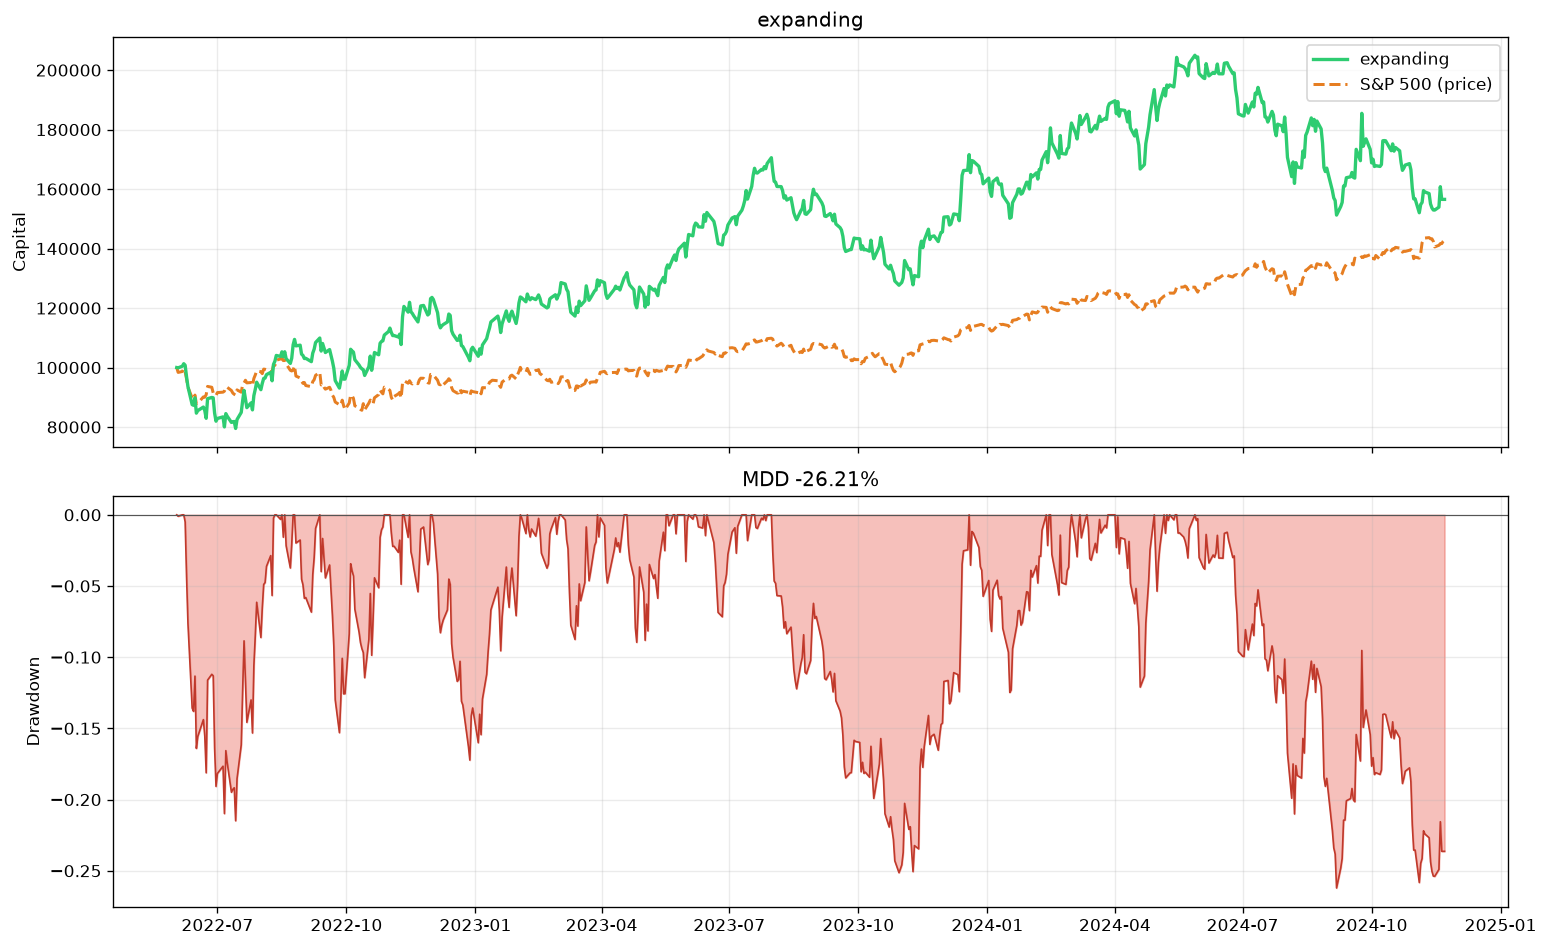

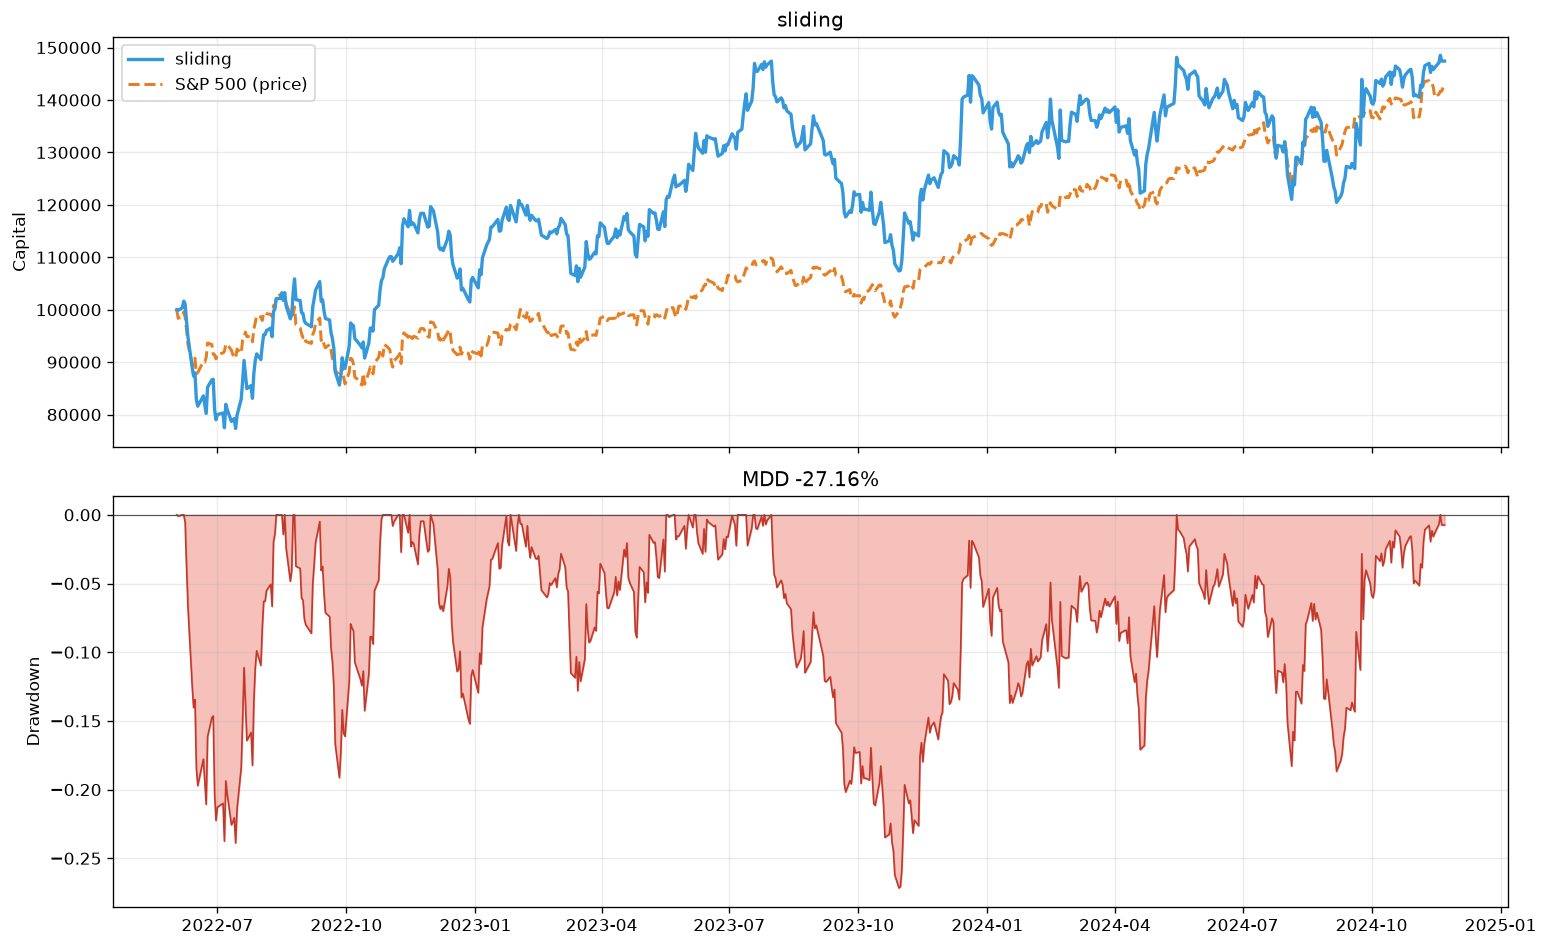

WindowsPath('c:/Users/dima/Desktop/Важные файлы с МГТУ им. Н.Э.Баумана и не только/ИУ6/3 курс/6 семестр/КУРСАЧИ/МЛ/MMOAI/data/derived/review_strict_2026_11_01/predictions/static_rf.csv.gz')

In [57]:
panel = full_price_panel.copy()
index_prices = index_df[['Date','SP500']].copy()
primary_models = {BASE_MODEL:dict(make_models())[BASE_MODEL]}
exp_monthly,exp_fold_df = rr.walk_predict(df_prediction,ALL_FEAT_COLS,primary_models,
    OOS_START,OOS_END,gap=GAP_DAYS,step=STEP_DAYS,cache_dir=PRED_DIR/'expanding_rf')
static_preds,static_fold_df = rr.walk_predict(df_prediction,ALL_FEAT_COLS,primary_models,
    OOS_START,OOS_END,gap=GAP_DAYS,step=STEP_DAYS,static=True,cache_dir=PRED_DIR/'static_rf')
common_start,common_end = OOS_START,OOS_END
def prep(preds,model_col=BASE_MODEL):
    return preds[['Date','Symbol','y_true',model_col]].rename(columns={model_col:'y_prob'}).copy()
pred_sources = {'static':static_preds,'expanding':exp_monthly,'sliding':sw_preds}
keys = exp_monthly[['Date','Symbol']].reset_index(drop=True)
for scheme,p in pred_sources.items():
    assert p[['Date','Symbol']].reset_index(drop=True).equals(keys),scheme
runs,robust_runs,cost_rows,cost_runs = {},{},[],{}
for scheme,p in pred_sources.items():
    runs[scheme] = run_backtest(prep(p),panel,index_prices,horizon=HOLD_DAYS,
        start=common_start,end=common_end,label=scheme)
    robust_runs[scheme] = run_backtest(prep(p),panel,index_prices,horizon=HOLD_DAYS_ROBUST,
        start=common_start,end=common_end,label=scheme+' h21')
    for h in [10,21]:
        for multiplier in [1,3,5]:
            result = run_backtest(prep(p),panel,index_prices,horizon=h,start=common_start,
                                 end=common_end,commission=COMMISSION*multiplier,label=scheme)
            cost_runs[(scheme,h,multiplier)]=result
            cost_rows.append({'scheme':scheme,'holding':h,'cost_multiplier':multiplier,**result['metrics']})
comparison_df = pd.DataFrame({n:r['metrics'] for n,r in runs.items()}).T
main_cols = ['jensen_alpha','jensen_p','ff_alpha','ff_p','beta','information_ratio','total_return',
             'alpha_vs_index','alpha_vs_equal_weight','sharpe','max_drawdown',
             'profit_factor','avg_turnover','one_way_turnover','n_rebalances']
display(comparison_df[main_cols])
comparison_df.to_csv(CACHE_DIR/'primary_economic_comparison.csv')
cost_df = pd.DataFrame(cost_rows)
cost_df.to_csv(CACHE_DIR/'commission_stress.csv',index=False)
display(cost_df[['scheme','holding','cost_multiplier','total_return','jensen_alpha','alpha_vs_index','avg_turnover']])
for name,r in runs.items():
    r['equity'].to_csv(CACHE_DIR/f'equity_{name}.csv')
    r['trades'].to_csv(CACHE_DIR/f'trades_{name}.csv',index=False)
    print_backtest(r)
exp_fold_df.to_csv(CACHE_DIR/'expanding_fold_scores.csv',index=False)
static_fold_df.to_csv(CACHE_DIR/'static_fold_scores.csv',index=False)
plot_backtest(runs['expanding']); plt.show()
plot_backtest(runs['sliding']); plt.show()

for key,result in cost_runs.items():
    rp.validate_backtest(result,common_start,common_end)
    if len(result['entry_audit']):
        result['entry_audit'].to_csv(CACHE_DIR/f'entry_audit_{key[0]}_h{key[1]}_cost{key[2]}.csv',index=False)
rp.save_predictions(exp_monthly,PRED_DIR/'expanding_retrained')
rp.save_predictions(static_preds,PRED_DIR/'static_rf')


In [52]:
# Matched CI/p, common daily dates, actual RF, refitted factor regressions.
def annotated_tests(table,category,comparison,h,block):
    table=table.copy()
    table.attrs={}
    table['category']=category
    table['comparison']=comparison
    table['holding']=h
    table['primary_block']=block==BOOT_BLOCK_DAYS
    table['family']=category+np.where(table.metric.eq('jensen_alpha'),':primary_CAPM',':secondary_metrics')
    rp.validate_inference(table)
    return table

def adjust_families(table):
    table=table.copy()
    table['p_Holm']=np.nan
    # Sensitivity blocks are not searched for a winning p-value.
    for _,positions in table.groupby(['family','block']).groups.items():
        table.loc[positions,'p_Holm']=ri.holm(table.loc[positions,'p'])
    table['significant_Holm']=table.p_Holm.lt(.05)&table.status.eq('ok')
    rp.validate_inference(table)
    return table

scheme_rows,individual_rows,cost_rows_tests=[],[],[]
with threadpool_limits(limits=1):
    for h,group in [(HOLD_DAYS,runs),(HOLD_DAYS_ROBUST,robust_runs)]:
        blocks=sorted(set([BOOT_BLOCK_DAYS]+[h*k for k in [2,3,5,8]]))
        for block in blocks:
            for a,b in [('expanding','sliding'),('expanding','static'),('sliding','static')]:
                table=ri.economic_bootstrap(group[a],group[b],index_prices,factors=factors,
                    n_boot=N_BOOT,block=block,seed=SEED)
                scheme_rows.append(annotated_tests(table,'schemes',a+' - '+b,h,block))
            # Individual evidence, not a profit claim from a Sharpe point estimate.
            if block==BOOT_BLOCK_DAYS:
                for scheme,result in group.items():
                    table=ri.individual_bootstrap(result,index_prices,factors=factors,
                        n_boot=N_BOOT,block=block,seed=SEED)
                    individual_rows.append(annotated_tests(table,'individual',scheme,h,block))
        for scheme in group:
            for multiplier in [3,5]:
                stressed=cost_runs[(scheme,h,multiplier)]
                base=cost_runs[(scheme,h,1)]
                table=ri.economic_bootstrap(stressed,base,index_prices,factors=factors,
                    n_boot=N_BOOT,block=BOOT_BLOCK_DAYS,seed=SEED)
                cost_rows_tests.append(annotated_tests(table,'cost_change',f'{scheme}: {multiplier}x - 1x',h,BOOT_BLOCK_DAYS))
                table=ri.individual_bootstrap(stressed,index_prices,factors=factors,
                    n_boot=N_BOOT,block=BOOT_BLOCK_DAYS,seed=SEED)
                individual_rows.append(annotated_tests(table,'individual_stress',f'{scheme} cost{multiplier}',h,BOOT_BLOCK_DAYS))

alpha_tests=adjust_families(pd.concat(scheme_rows,ignore_index=True))
individual_tests=adjust_families(pd.concat(individual_rows,ignore_index=True))
cost_tests=adjust_families(pd.concat(cost_rows_tests,ignore_index=True))
alpha_tests.to_csv(CACHE_DIR/'scheme_all_metrics_significance.csv',index=False)
individual_tests.to_csv(CACHE_DIR/'individual_metrics_significance.csv',index=False)
cost_tests.to_csv(CACHE_DIR/'commission_significance.csv',index=False)
print('Основные сравнения схем: блок21, CAPM alpha')
display(alpha_tests[alpha_tests.primary_block&alpha_tests.metric.eq('jensen_alpha')])
print('Вторичные показатели схем, блок21')
display(alpha_tests[alpha_tests.primary_block&~alpha_tests.metric.eq('jensen_alpha')])
print('Индивидуальные alpha/Sharpe/PF, блок21')
display(individual_tests[individual_tests.metric.isin(['jensen_alpha','ff_alpha','sharpe','profit_factor'])])
print('Комиссии: изменение primary alpha')
display(cost_tests[cost_tests.metric.eq('jensen_alpha')])

# Overlapping 1/h sleeves: same daily calendar for both holding horizons.
overlap_results,overlap_rows={},[]
with threadpool_limits(limits=1):
    for scheme,p in pred_sources.items():
        pair={}
        for h in [HOLD_DAYS,HOLD_DAYS_ROBUST]:
            result=rr.overlapping_backtest(prep(p),panel,index_prices,horizon=h,
                start=common_start,end=common_end,top_k=TOP_K,commission=COMMISSION,
                capital=INITIAL_CAPITAL,label=scheme+' overlapping')
            result['metrics'].update(rr.factor_risk_metrics(result['equity'],index_prices,factors,lag=BOOT_BLOCK_DAYS))
            rp.validate_backtest(result,common_start,common_end)
            pair[h]=result
            result['equity'].to_csv(CACHE_DIR/f'overlap_equity_{scheme}_h{h}.csv')
            result['trades'].to_csv(CACHE_DIR/f'overlap_trades_{scheme}_h{h}.csv',index=False)
        overlap_results[scheme]=pair
        for block in sorted(set([BOOT_BLOCK_DAYS]+[HOLD_DAYS_ROBUST*k for k in [2,3,5,8]])):
            table=ri.economic_bootstrap(pair[HOLD_DAYS_ROBUST],pair[HOLD_DAYS],index_prices,
                factors=factors,n_boot=N_BOOT,block=block,seed=SEED)
            overlap_rows.append(annotated_tests(table,'holding_overlap',scheme+' h21 - h10',21,block))
overlap_tests=adjust_families(pd.concat(overlap_rows,ignore_index=True))
overlap_tests.to_csv(CACHE_DIR/'overlapping_horizon_all_metrics.csv',index=False)
display(overlap_tests[overlap_tests.primary_block])
print('Отсутствие значимости не доказывает эквивалентности. '
      'Номинальный CI сравнивается с raw p; вывод после множественности — по p_Holm.')


Основные сравнения схем: блок21, CAPM alpha


,metric,estimate,null,block,n_days,capm_source,estimand,ci_low,ci_high,p,...,method,status,valid_fraction,category,comparison,holding,primary_block,family,p_Holm,significant_Holm
22,jensen_alpha,0.019606,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.164708,0.205677,0.847576,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - sliding,10,True,schemes:primary_CAPM,1.000000,False
29,jensen_alpha,0.055451,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.039100,0.141756,0.229885,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - static,10,True,schemes:primary_CAPM,1.000000,False
36,jensen_alpha,0.035845,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.161376,0.230154,0.680660,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,sliding - static,10,True,schemes:primary_CAPM,1.000000,False
106,jensen_alpha,0.135835,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.090694,0.362712,0.255872,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - sliding,21,True,schemes:primary_CAPM,1.000000,False
113,jensen_alpha,0.175527,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,0.033497,0.291327,0.018991,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - static,21,True,schemes:primary_CAPM,0.113943,False
120,jensen_alpha,0.039692,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.175309,0.262702,0.710645,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,sliding - static,21,True,schemes:primary_CAPM,1.000000,False


Вторичные показатели схем, блок21


,metric,estimate,null,block,n_days,capm_source,estimand,ci_low,ci_high,p,...,method,status,valid_fraction,category,comparison,holding,primary_block,family,p_Holm,significant_Holm
21,annual_log_growth,0.024275,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.154065,0.205998,0.838581,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - sliding,10,True,schemes:secondary_metrics,1.000000,False
23,sharpe,0.056465,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.511846,0.626016,0.882559,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - sliding,10,True,schemes:secondary_metrics,1.000000,False
24,max_drawdown,0.009522,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,fixed_horizon_secondary,-0.119893,0.144182,0.842579,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - sliding,10,True,schemes:secondary_metrics,1.000000,False
25,profit_factor,-0.015140,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,conditional_observed_notional_realized_trade_PnL,-0.247385,0.260911,0.855572,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - sliding,10,True,schemes:secondary_metrics,1.000000,False
26,total_return,0.091183,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,fixed_horizon_secondary,-0.838480,0.958337,0.789605,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - sliding,10,True,schemes:secondary_metrics,1.000000,False
27,ff_alpha,0.016365,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.157506,0.200182,0.887556,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - sliding,10,True,schemes:secondary_metrics,1.000000,False
28,annual_log_growth,0.062509,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.033320,0.151231,0.180910,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - static,10,True,schemes:secondary_metrics,1.000000,False
30,sharpe,0.181931,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.099958,0.442989,0.185907,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - static,10,True,schemes:secondary_metrics,1.000000,False
31,max_drawdown,0.049146,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,fixed_horizon_secondary,-0.014633,0.141906,0.086957,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - static,10,True,schemes:secondary_metrics,1.000000,False
32,profit_factor,0.066730,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,conditional_observed_notional_realized_trade_PnL,-0.066005,0.169255,0.264868,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - static,10,True,schemes:secondary_metrics,1.000000,False


Индивидуальные alpha/Sharpe/PF, блок21


,metric,estimate,null,block,n_days,capm_source,estimand,ci_low,ci_high,p,...,method,status,valid_fraction,category,comparison,holding,primary_block,family,p_Holm,significant_Holm
1,jensen_alpha,-0.028094,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.310905,0.263187,0.851574,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,individual,static,10,True,individual:primary_CAPM,1.0,False
2,sharpe,0.389153,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.716877,1.526836,0.502749,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,individual,static,10,True,individual:secondary_metrics,1.0,False
4,profit_factor,1.096143,1.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,conditional_observed_notional_realized_trade_PnL,0.636391,1.407079,0.606697,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,individual,static,10,True,individual:secondary_metrics,1.0,False
6,ff_alpha,0.029845,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.227575,0.289277,0.883558,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,individual,static,10,True,individual:secondary_metrics,1.0,False
8,jensen_alpha,0.027357,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.254445,0.307726,0.856572,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,individual,expanding,10,True,individual:primary_CAPM,1.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118,ff_alpha,-0.118302,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.345690,0.090693,0.277861,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,individual_stress,sliding cost3,21,True,individual_stress:secondary_metrics,1.0,False
120,jensen_alpha,-0.200871,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.440147,0.051687,0.123938,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,individual_stress,sliding cost5,21,True,individual_stress:primary_CAPM,1.0,False
121,sharpe,-0.144670,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-1.282388,1.137864,0.825587,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,individual_stress,sliding cost5,21,True,individual_stress:secondary_metrics,1.0,False
123,profit_factor,0.923578,1.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,conditional_observed_notional_realized_trade_PnL,0.213736,1.319480,0.773613,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,individual_stress,sliding cost5,21,True,individual_stress:secondary_metrics,1.0,False


Комиссии: изменение primary alpha


,metric,estimate,null,block,n_days,capm_source,estimand,ci_low,ci_high,p,...,method,status,valid_fraction,category,comparison,holding,primary_block,family,p_Holm,significant_Holm
1,jensen_alpha,-0.099574,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.104469,-0.093926,0.001,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,cost_change,static: 3x - 1x,10,True,cost_change:primary_CAPM,0.011994,True
8,jensen_alpha,-0.198756,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.208528,-0.187485,0.001,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,cost_change,static: 5x - 1x,10,True,cost_change:primary_CAPM,0.011994,True
15,jensen_alpha,-0.099617,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.104482,-0.094012,0.001,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,cost_change,expanding: 3x - 1x,10,True,cost_change:primary_CAPM,0.011994,True
22,jensen_alpha,-0.198841,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.208555,-0.187653,0.001,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,cost_change,expanding: 5x - 1x,10,True,cost_change:primary_CAPM,0.011994,True
29,jensen_alpha,-0.099437,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.104289,-0.093739,0.001,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,cost_change,sliding: 3x - 1x,10,True,cost_change:primary_CAPM,0.011994,True
36,jensen_alpha,-0.198481,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.208169,-0.187111,0.001,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,cost_change,sliding: 5x - 1x,10,True,cost_change:primary_CAPM,0.011994,True
43,jensen_alpha,-0.047006,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.049719,-0.044644,0.001,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,cost_change,static: 3x - 1x,21,True,cost_change:primary_CAPM,0.011994,True
50,jensen_alpha,-0.093828,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.099237,-0.089113,0.001,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,cost_change,static: 5x - 1x,21,True,cost_change:primary_CAPM,0.011994,True
57,jensen_alpha,-0.047088,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.049801,-0.044651,0.001,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,cost_change,expanding: 3x - 1x,21,True,cost_change:primary_CAPM,0.011994,True
64,jensen_alpha,-0.093991,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.099406,-0.089130,0.001,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,cost_change,expanding: 5x - 1x,21,True,cost_change:primary_CAPM,0.011994,True


,metric,estimate,null,block,n_days,capm_source,estimand,ci_low,ci_high,p,...,method,status,valid_fraction,category,comparison,holding,primary_block,family,p_Holm,significant_Holm
0,annual_log_growth,0.019741,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.073188,0.094791,0.612694,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,holding_overlap,static h21 - h10,21,True,holding_overlap:secondary_metrics,1.000000,False
1,jensen_alpha,0.019504,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.073297,0.098372,0.610695,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,holding_overlap,static h21 - h10,21,True,holding_overlap:primary_CAPM,1.000000,False
2,sharpe,0.057998,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.222022,0.285518,0.613693,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,holding_overlap,static h21 - h10,21,True,holding_overlap:secondary_metrics,1.000000,False
3,max_drawdown,0.034727,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,fixed_horizon_secondary,-0.049951,0.107170,0.330835,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,holding_overlap,static h21 - h10,21,True,holding_overlap:secondary_metrics,1.000000,False
4,profit_factor,0.048983,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,conditional_observed_notional_realized_trade_PnL,-0.233893,0.271653,0.701649,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,holding_overlap,static h21 - h10,21,True,holding_overlap:secondary_metrics,1.000000,False
5,total_return,0.059468,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,fixed_horizon_secondary,-0.236660,0.350807,0.571714,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,holding_overlap,static h21 - h10,21,True,holding_overlap:secondary_metrics,1.000000,False
6,ff_alpha,0.001980,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.075792,0.077880,0.870565,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,holding_overlap,static h21 - h10,21,True,holding_overlap:secondary_metrics,1.000000,False
35,annual_log_growth,0.019929,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.058943,0.081689,0.564718,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,holding_overlap,expanding h21 - h10,21,True,holding_overlap:secondary_metrics,1.000000,False
36,jensen_alpha,0.020541,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.053930,0.084523,0.554723,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,holding_overlap,expanding h21 - h10,21,True,holding_overlap:primary_CAPM,1.000000,False
37,sharpe,0.069201,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.162017,0.259477,0.506747,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,holding_overlap,expanding h21 - h10,21,True,holding_overlap:secondary_metrics,1.000000,False


Отсутствие значимости не доказывает эквивалентности. Номинальный CI сравнивается с raw p; вывод после множественности — по p_Holm.


---
# 4. Интерпретация модели (SHAP)

SHAP (SHapley Additive exPlanations) - метод интерпретации, основанный на теории кооперативных игр.
Он отвечает на вопрос: **насколько каждый признак повлиял на конкретный прогноз?**


Модель для SHAP: RandomForestClassifier | признаков: 273
Подвыборка: 2,000 из 305,354 строк (доля класса 1: 0.488 против 0.488 на полной)
SHAP посчитан за 9.3 с


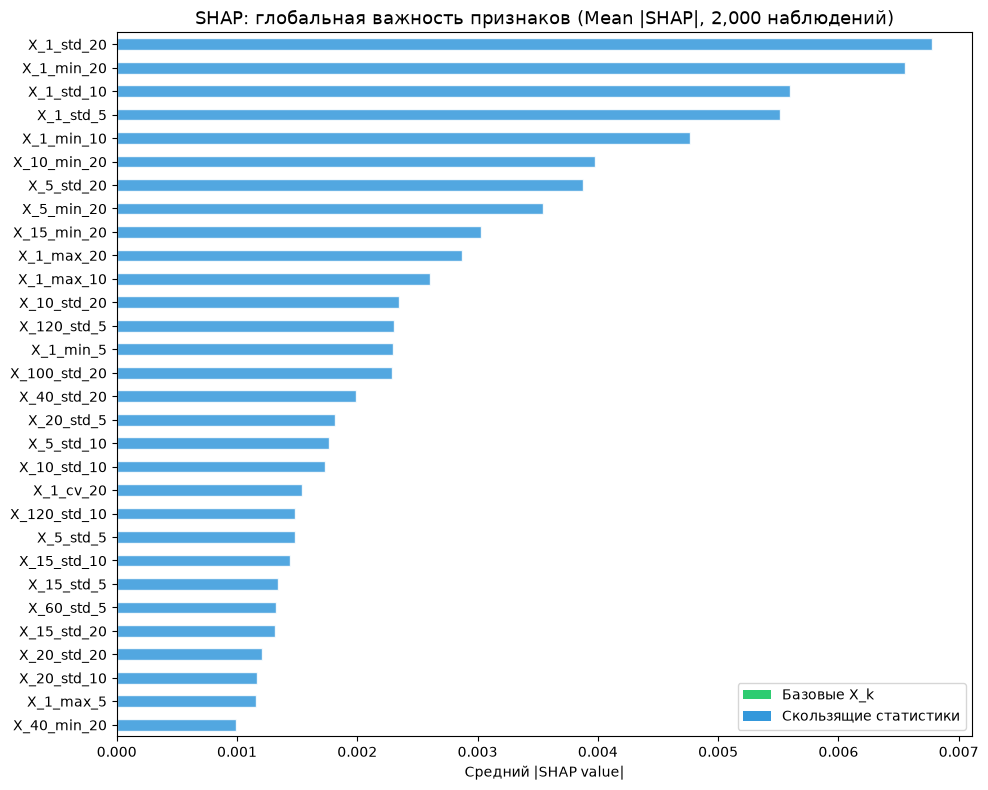


SHAP Summary Plot (распределение влияния каждого признака):


C:\Users\dima\AppData\Local\Temp\ipykernel_30504\3485059523.py:100: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_shap, feature_names=FEATURE_COLS, show=False,


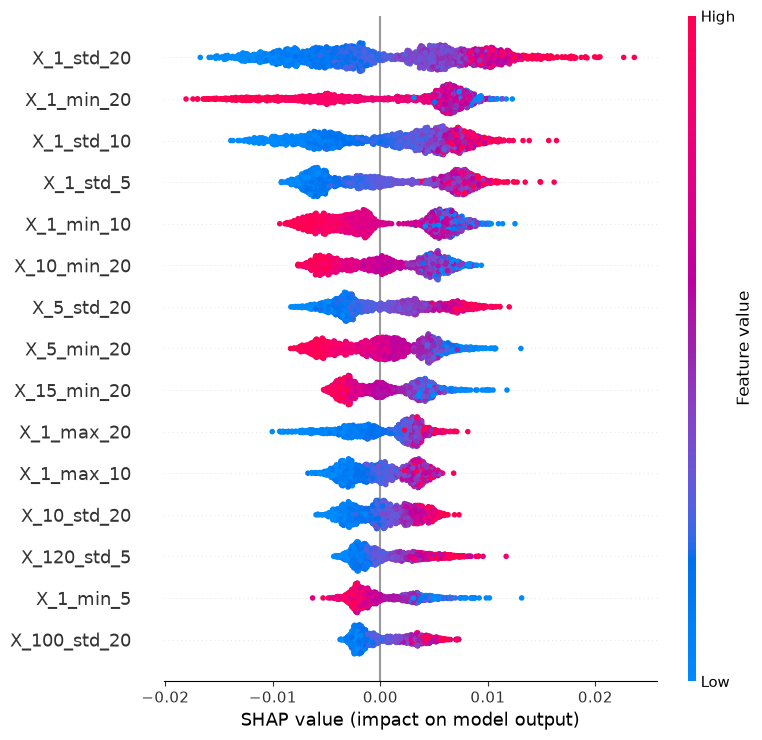


Топ-5 признаков по среднему |SHAP|:
  X_1_std_20           0.00678  (статистика)
  X_1_min_20           0.00655  (статистика)
  X_1_std_10           0.00560  (статистика)
  X_1_std_5            0.00552  (статистика)
  X_1_min_10           0.00476  (статистика)

Красные точки на beeswarm - высокое значение признака; сдвиг вправо повышает P(рост > 2%).
Mean |SHAP| показывает силу влияния, но не его направление и не причинность.


In [53]:
# Та же базовая RF-конфигурация, что в основном экономическом опыте.
from matplotlib.patches import Patch

SHAP_SAMPLE = min(SHAP_SAMPLE,len(X_test))

best_model_obj = best['model']  # primary RF base, как в экономическом сравнении

# Pipeline - берём сам классификатор и подаём ему масштабированные признаки
if isinstance(best_model_obj, Pipeline):
    clf_for_shap = best_model_obj[-1]
    steps = best_model_obj.named_steps
    X_shap_full = (pd.DataFrame(steps['scaler'].transform(X_test),
                                columns=FEATURE_COLS, index=X_test.index)
                   if 'scaler' in steps else X_test.copy())
else:
    clf_for_shap = best_model_obj
    X_shap_full = X_test.copy()

model_type = type(clf_for_shap).__name__
print(f'Модель для SHAP: {model_type} | признаков: {len(FEATURE_COLS)}')

# ── Стратифицированная подвыборка теста ──────────────────────────────────────
y_test_arr = y_test.to_numpy()
rng_shap = np.random.default_rng(SEED)

if len(y_test_arr) > SHAP_SAMPLE:
    shap_idx = np.sort(np.concatenate([
        rng_shap.choice(np.flatnonzero(y_test_arr == c),
                        size=round(SHAP_SAMPLE * (y_test_arr == c).mean()),
                        replace=False)
        for c in np.unique(y_test_arr)
    ]))
else:
    shap_idx = np.arange(len(y_test_arr))

X_shap = X_shap_full.iloc[shap_idx]
print(f'Подвыборка: {len(shap_idx):,} из {len(y_test_arr):,} строк '
      f'(доля класса 1: {y_test_arr[shap_idx].mean():.3f} против '
      f'{y_test_arr.mean():.3f} на полной)')

# ── Расчёт SHAP ──────────────────────────────────────────────────────────────
TREE_MODELS = ('RandomForestClassifier', 'GradientBoostingClassifier',
               'HistGradientBoostingClassifier', 'XGBClassifier',
               'LGBMClassifier', 'DecisionTreeClassifier')

t_shap = time.time()
if model_type in TREE_MODELS:
    explainer = shap.TreeExplainer(clf_for_shap)
    raw = explainer.shap_values(X_shap, check_additivity=False)
elif model_type == 'LogisticRegression':
    # Для линейной модели SHAP считается аналитически - доли секунды
    explainer = shap.LinearExplainer(clf_for_shap, X_shap_full.iloc[shap_idx])
    raw = explainer.shap_values(X_shap)
else:
    # KernelExplainer - последнее средство, поэтому выборка ещё меньше
    background = shap.kmeans(X_shap_full, 50)
    explainer = shap.KernelExplainer(clf_for_shap.predict_proba, background)
    raw = explainer.shap_values(X_shap.iloc[:200], nsamples=100)
    X_shap = X_shap.iloc[:200]

# Приведение к 2D (n_samples, n_features) для класса 1
if isinstance(raw, list):
    sv = raw[1] if len(raw) == 2 else raw[0]
elif raw.ndim == 3:
    sv = raw[:, :, 1] if raw.shape[2] == 2 else raw[:, :, 0]
else:
    sv = raw

assert sv.shape == (len(X_shap), len(FEATURE_COLS)), (
    f'Неожиданная форма SHAP: {sv.shape}, ожидалось '
    f'{(len(X_shap), len(FEATURE_COLS))}')
print(f'SHAP посчитан за {time.time() - t_shap:.1f} с')

# ── График 1: глобальная важность ────────────────────────────────────────────
feat_importance = (pd.Series(np.abs(sv).mean(axis=0), index=FEATURE_COLS)
                   .sort_values(ascending=True).tail(30))

# Раньше цвет задавался по подстрокам 'Momentum'/'Return', которых в именах
# признаков нет - все столбцы выходили одного цвета, а легенда вводила в
# заблуждение. Разделяем базовые относительные доходности X_k и производные
# от них скользящие статистики.
is_base = [f in FEAT_COLS for f in feat_importance.index]
colors = ['#2ecc71' if b else '#3498db' for b in is_base]

fig, ax = plt.subplots(figsize=(10, 8))
feat_importance.plot(kind='barh', ax=ax, color=colors, edgecolor='white',
                     alpha=0.85)
ax.set_title(f'SHAP: глобальная важность признаков (Mean |SHAP|, '
             f'{len(X_shap):,} наблюдений)', fontsize=13)
ax.set_xlabel('Средний |SHAP value|')
ax.legend(handles=[Patch(facecolor='#2ecc71', label='Базовые X_k'),
                   Patch(facecolor='#3498db', label='Скользящие статистики')])
plt.tight_layout()
plt.savefig(FIG_DIR / 'shap_feature_importance.png', dpi=120,
            bbox_inches='tight')
plt.show()

# ── График 2: beeswarm ───────────────────────────────────────────────────────
print('\nSHAP Summary Plot (распределение влияния каждого признака):')
shap.summary_plot(sv, X_shap, feature_names=FEATURE_COLS, show=False,
                  plot_type='dot', max_display=15)
plt.tight_layout()
plt.savefig(FIG_DIR / 'shap_beeswarm.png', dpi=120, bbox_inches='tight')
plt.show()

# ── Интерпретация ────────────────────────────────────────────────────────────
top = feat_importance.tail(5).iloc[::-1]
print('\nТоп-5 признаков по среднему |SHAP|:')
for name, val in top.items():
    kind = 'базовый' if name in FEAT_COLS else 'статистика'
    print(f'  {name:<20} {val:.5f}  ({kind})')
print('\nКрасные точки на beeswarm - высокое значение признака; '
      'сдвиг вправо повышает P(рост > 2%).')
print('Mean |SHAP| показывает силу влияния, но не его направление и '
      'не причинность.')


SHAP описывает базовый статический RF той же конфигурации, что применяется
во всех экономических схемах. Интерпретируется один fit и фиксированная
подвыборка; устойчивость направлений эффекта между всеми фолдами не заявляется.
Ранг |SHAP| не определяет знак; знак читается по текущему beeswarm.
SHAP помогает понять факторную экспозицию, но не доказывает превосходство окна.


In [54]:
# Все проверки выполняются до отметки completed.
for name,p in pred_sources.items():
    rp.validate_predictions(p)
for table in [alpha_tests,individual_tests,cost_tests,overlap_tests]:
    rp.validate_inference(table)
assert train_df.LabelEnd.max()<test_df.Date.min()
assert len(ALL_FEAT_COLS)==273 and ALL_FEAT_COLS==rr.ALL_FEATURES
assert config['loaded']==price_downloaded.Symbol.nunique()
assert all(r['equity'].index.equals(runs['expanding']['equity'].index) for r in runs.values())
print('СВОДКА НОВОГО ПРОГОНА')
print('Запрошено:',len(requested_symbols),'историй:',price_downloaded.Symbol.nunique(),
      'бумаг с полным Target:',daily_df.Symbol.nunique(),'строк:',len(daily_df))
print('Класс0:',1-daily_df.Target.mean(),'класс1:',daily_df.Target.mean())
display(funnel_df)
display(cv_results_df.drop(columns='folds'))
display(sw_results_df)
display(comparison_df[main_cols])
display(alpha_tests[alpha_tests.primary_block&alpha_tests.metric.eq('jensen_alpha')])
display(overlap_tests[overlap_tests.primary_block&overlap_tests.metric.eq('jensen_alpha')])
print('Feature date-block BH:',int(feature_block_df.q_BH.lt(.05).sum()),
      'BY:',int(feature_block_df.q_BY.lt(.05).sum()))
print('Согласованных значимых пар алгоритмов:',int(sig_df['Значимо'].sum()))
config['eligible']=int(daily_df.Symbol.nunique())
config['rows']=len(daily_df)
config['environment']=environment
config['all_502_histories']=bool(price_downloaded.Symbol.nunique()==len(requested_symbols))
config['inference_integrity']='matched_CI_p_all_passed'
config['limitations']=['retrospective_OOS','conditional_on_fitted_predictions',
    'survivorship_bias','price_returns_without_dividends','PF_conditional_observed_notional_path',
    'block_stationarity_approximation']
(CACHE_DIR/'run_completed.json').write_text(json.dumps({'status':'completed','config':config},indent=2),encoding='utf-8')
print('Расчёт завершён. Источник чисел для статьи — CSV этого каталога:',CACHE_DIR)


СВОДКА НОВОГО ПРОГОНА
Запрошено: 502 историй: 495 бумаг с полным Target: 492 строк: 1077612
Класс0: 0.5177392233939488 класс1: 0.48226077660605116


,Шаг,Тикеров,Причина отсева
0,Запрошено фиксированных тикеров,502,снимок состава 2024
1,Загружены непустые истории,495,см. manifest
2,Есть 273 признака и полный таргет,492,IPO/пропуски/прогрев


,Модель,CV ROC-AUC (mean),CV ROC-AUC (std)
0,Random Forest,0.585192,0.010266
1,Gradient Boosting,0.584695,0.010247
2,XGBoost,0.582581,0.009717
3,Logistic Regression,0.578435,0.012959
4,FLAML AutoML,0.575171,0.014543
5,KNN,0.533499,0.005781


,Модель,ROC-AUC (mean),ROC-AUC (std),ROC-AUC (пул)
1,Random Forest,0.560661,0.044298,0.560095
3,Gradient Boosting,0.552370,0.045524,0.554375
2,XGBoost,0.549962,0.042753,0.552128
0,Logistic Regression,0.543429,0.045494,0.547493
4,KNN,0.520698,0.019608,0.523098


,jensen_alpha,jensen_p,ff_alpha,ff_p,beta,information_ratio,total_return,alpha_vs_index,alpha_vs_equal_weight,sharpe,max_drawdown,profit_factor,avg_turnover,one_way_turnover,n_rebalances
static,-0.028094,0.852213,0.029845,0.829511,1.416184,0.073587,0.341263,-0.087896,-0.051396,0.389153,-0.311259,1.096143,2.006437,1.003219,62
expanding,0.027357,0.85328,0.068625,0.622817,1.481738,0.31973,0.565408,0.136249,0.172749,0.571084,-0.262113,1.162872,2.009025,1.004513,62
sliding,0.007751,0.953286,0.052259,0.666385,1.364204,0.210151,0.474225,0.045066,0.081566,0.51462,-0.271635,1.178012,2.008109,1.004055,62


,metric,estimate,null,block,n_days,capm_source,estimand,ci_low,ci_high,p,...,method,status,valid_fraction,category,comparison,holding,primary_block,family,p_Holm,significant_Holm
22,jensen_alpha,0.019606,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.164708,0.205677,0.847576,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - sliding,10,True,schemes:primary_CAPM,1.000000,False
29,jensen_alpha,0.055451,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.039100,0.141756,0.229885,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - static,10,True,schemes:primary_CAPM,1.000000,False
36,jensen_alpha,0.035845,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.161376,0.230154,0.680660,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,sliding - static,10,True,schemes:primary_CAPM,1.000000,False
106,jensen_alpha,0.135835,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.090694,0.362712,0.255872,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - sliding,21,True,schemes:primary_CAPM,1.000000,False
113,jensen_alpha,0.175527,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,0.033497,0.291327,0.018991,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,expanding - static,21,True,schemes:primary_CAPM,0.113943,False
120,jensen_alpha,0.039692,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.175309,0.262702,0.710645,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,schemes,sliding - static,21,True,schemes:primary_CAPM,1.000000,False


,metric,estimate,null,block,n_days,capm_source,estimand,ci_low,ci_high,p,...,method,status,valid_fraction,category,comparison,holding,primary_block,family,p_Holm,significant_Holm
1,jensen_alpha,0.019504,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.073297,0.098372,0.610695,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,holding_overlap,static h21 - h10,21,True,holding_overlap:primary_CAPM,1.000000,False
36,jensen_alpha,0.020541,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.053930,0.084523,0.554723,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,holding_overlap,expanding h21 - h10,21,True,holding_overlap:primary_CAPM,1.000000,False
71,jensen_alpha,0.049952,0.0,21,623,actual_index_excess_return_CAPM_external_daily_RF,daily_process,-0.027200,0.126088,0.202899,...,circular_moving_block_basic_equal_tail_plus_one,ok,1.0,holding_overlap,sliding h21 - h10,21,True,holding_overlap:primary_CAPM,0.608696,False


Feature date-block BH: 116 BY: 93
Согласованных значимых пар алгоритмов: 3
Расчёт завершён. Источник чисел для статьи — CSV этого каталога: c:\Users\dima\Desktop\Важные файлы с МГТУ им. Н.Э.Баумана и не только\ИУ6\3 курс\6 семестр\КУРСАЧИ\МЛ\MMOAI\data\derived\review_strict_2026_11_01


# 5. Итоги и ограничения

Я формулирую численные выводы только по предыдущей сводке и сохранённым CSV.
Главный вывод о форме окна относится к expanding/sliding с одинаковым
расписанием, purge, моделью и OOS. Основная проверка — CAPM alpha;
FF5+momentum, Sharpe, просадка, PF и log growth дополняют её.

1. Положительная доходность или Precision@10 выше baseline не доказывают
   риск-корректированного преимущества. Достижение цели не равно P&L сделки.
2. После множественных сравнений вывод делается по заранее определённому
   Holm-семейству. Номинальный 95% CI не выдаётся за одновременный интервал.
3. 21-дневное удержание — исполнение исходного 10-дневного сигнала, а не
   сравнение моделей с разными метками. Overlapping учитывает cash на краях.
4. Фактическая полнота и пригодность данных указаны отдельно. Неполная
   вселенная не становится полной от увеличения числа строк.
5. Исторический состав индекса не восстановлен; survivorship bias остаётся.
   Пропущенные/делистингованные истории не заменяются историями покупателей.
6. Основной RF и SHAP имеют одну конфигурацию. Дополнительные legacy tuning
   параметры не объявляются оптимальными на новой вселенной.
7. Доходности ценовые, без дивидендов; нет slippage/impact/borrow fees.
   FF-факторы — total-return премии: регрессия контролирует экспозиции, а не
   устраняет все различия определения доходности.
8. Bootstrap условен на прогнозах и наблюдаемом пути P&L, не повторяет fit
   модели и выбор экспериментов. Длины блоков — чувствительность; при
   нестационарности и небольшом числе независимых блоков мощность ограничена.
9. OOS уже использовался в предыдущих версиях. Это ретроспективная оценка;
   строгое независимое подтверждение потребует нового периода/выборки.

Публикация кода подготовлена локально, push не выполняется. Для статьи
остаются редакторские изменения: ссылки на таблицы, раздельные таблицы
scheme/horizon/cost, перенос собственных результатов из Related Work,
обоснование или замена нерелевантных источников. PDF в этой задаче не изменяется.
